<h1 style="text-align:center;">Decoding Visual Stimuli from Neural Population Activity </h1>
<h3 style="text-align:center;">Mathematical Modelling for Neuroscience (30563)</h3>
<h5 style="text-align:center;">
Antonescu Victor-Gabriel &middot;
Di Pietro Letizia&middot;
Lukanov Martin &middot;
Stoica Alexandru &middot;
Troiano Antonio 
</h5>

### Table of Contents
0. Inspecting Functional Data
1. Static Analysis
2. Temporal Analysis
3. Final Comparison


# Part 0: Inspecting Functional Data

Import libraries and packages that we need.

In [229]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [230]:
#Import our package
import microns_datacleaner as mic

Now we initialize the reader to access the functional data from MICrONS dataset.  
In particular, we use a reduced version of this data that is indeed the h5 file.

In [231]:
funcreader = mic.MicronsFunctionalReader(path= "./microns.h5")

In [232]:
# List the public methods of the reader, useful for discovering what queries are available.
dir(funcreader)


['__class__',
 '__delattr__',
 '__dict__',
 '__dir__',
 '__doc__',
 '__enter__',
 '__eq__',
 '__exit__',
 '__format__',
 '__ge__',
 '__getattribute__',
 '__gt__',
 '__hash__',
 '__init__',
 '__init_subclass__',
 '__le__',
 '__lt__',
 '__module__',
 '__ne__',
 '__new__',
 '__reduce__',
 '__reduce_ex__',
 '__repr__',
 '__setattr__',
 '__sizeof__',
 '__str__',
 '__subclasshook__',
 '__weakref__',
 '_decode_hash',
 '_encode_hash',
 '_read_trial',
 'close',
 'f',
 'file_path',
 'filename',
 'get_available_brain_areas',
 'get_full_data_by_hash',
 'get_hashes_by_session',
 'get_hashes_by_type',
 'get_responses_by_hash',
 'get_trial',
 'get_video_data',
 'get_video_type',
 'homedir',
 'print_structure']

In [233]:
# Print the hierarchical structure of the HDF5 file
# (sessions, videos, types, brain areas) for initial exploration.
funcreader.print_structure()



Structure of: ./microns.h5
📂 BRAIN_AREAS/ 
    📂 AL/ 
        🔗 4_7                -> /sessions/4_7
        🔗 5_6                -> /sessions/5_6
        🔗 5_7                -> /sessions/5_7
        🔗 6_2                -> /sessions/6_2
        🔗 6_4                -> /sessions/6_4
        ... and 9 more items
    📂 LM/ 
        🔗 4_7                -> /sessions/4_7
        🔗 5_6                -> /sessions/5_6
        🔗 5_7                -> /sessions/5_7
        🔗 6_2                -> /sessions/6_2
        🔗 6_4                -> /sessions/6_4
        ... and 9 more items
    📂 RL/ 
        🔗 4_7                -> /sessions/4_7
        🔗 5_6                -> /sessions/5_6
        🔗 5_7                -> /sessions/5_7
        🔗 6_2                -> /sessions/6_2
        🔗 6_4                -> /sessions/6_4
        ... and 9 more items
    📂 V1/ 
        🔗 4_7                -> /sessions/4_7
        🔗 5_6                -> /sessions/5_6
        🔗 5_7                -> /sessions/5

The dataset structure was inspected using the `print_structure()` method.

The inspection of the HDF5 file structure shows that the dataset is organized into four main sections:

- **SESSIONS**: contains the neural recordings organized by experimental session;
- **VIDEOS**: contains the visual stimuli (clips) presented during the experiment;
- **TYPES**: groups the videos by category of stimuli (e.g. *TRIPPY*, *MONET2*, *CLIP*);
- **BRAIN_AREAS**: organizes neurons according to their brain region (e.g. V1, LM, RL, AL).

For our project, the most important part is `SESSIONS`, because it contains the **functional data**, that is, neural activity over time.

In particular each session contains:

- a `META` section with general information (fps, unit_ids, etc.);
- a `TRIALS` section, where each trial contains:
    - `responses`: neural activity matrix (neurons × time);
    - `stim_times`: timestamps associated with each frame;
    - `pupil` and `treadmill`, which are not used in this project.

The `VIDEOS` section instead contains the visual stimuli as sequences of frames (`clip`), along with metadata such as video duration, frame rate and stimulus type (natural clip, Monet, Trippy, etc.).

The MICrONS dataset contains multiple experimental sessions, each corresponding to a different recording of neural activity.  
For this project, we start by working on the single session `4_7` which contains a large number of trials, providing sufficient data for building a decoding model.

In [234]:
# Obtain number of trials for session 4_7

hashes = funcreader.get_hashes_by_session("4_7")
print("Number of trials:", len(hashes))

Number of trials: 464


In [235]:
# Inspect the form of the hash strings
print(hashes[:5])


['JEL5/i5FccX4ykUOKaDW', 'AAQ1HNKGrg1cIXlMw7nz', 'ksTS42zV+O0YJqa0+s4Y', 'm5JLObtSRnbRKw1ukcSE', 'L8Z/mji+v1WipuJe4GaL']


In [236]:
# Distinct stimulus types present in this session
types = [funcreader.get_video_type(h) for h in hashes]
print(set(types))


{'Monet2', 'Trippy', 'Clip'}


In [237]:
# Number of trials per stimulus type
from collections import Counter
print(Counter(types))


Counter({'Clip': 384, 'Monet2': 40, 'Trippy': 40})


The analysis of the session shows that three types of stimuli are present:

- Clip: 384 trials
- Monet2: 40 trials
- Trippy: 40 trials

The dataset is therefore highly imbalanced, with Clip stimuli dominating the session.

As part of the data exploration, we now check the number of neurons recorded in each brain area.


In [238]:
f = funcreader.f

area_indices = f["sessions/4_7/meta/area_indices"]

print("NUMBER OF NEURONS PER AREA (session 4_7):")
print("-" * 40)

for area in ["V1", "LM", "AL", "RL"]:
    n_neuron = len(area_indices[area][()])
    print(f"{area}: {n_neuron} neurons")

print("-" * 40)

total = len(f["sessions/4_7/meta/brain_areas"][()])
print(f"TOTAL: {total} neurons")

NUMBER OF NEURONS PER AREA (session 4_7):
----------------------------------------
V1: 5312 neurons
LM: 983 neurons
AL: 387 neurons
RL: 811 neurons
----------------------------------------
TOTAL: 7493 neurons


## Visualizations

Before starting the actual analysis we explore the data a little further.

First, we partition all hashes by stimulus category — **Trippy**, **Monet2**, **Clip**.

Then, taking the first trial of each category, we print the shape of the response matrix per brain area to verify that the four areas have consistent neuron counts within a trial.

Next we visualize the first frame of the first trial for each category, giving a direct comparison of the visual input.

Finally we plot the activity of **neuron 0** during the first trial for each category and brain area. Neuron 0 is used here as a representative example: neuron indices are stable across trials within an area, so the same panel position always tracks the same neuron.


In [239]:
AREAS = ["V1", "LM", "AL", "RL"]

trippy_hashes = [h for h in hashes if funcreader.get_video_type(h) == "Trippy"]
monet_hashes  = [h for h in hashes if funcreader.get_video_type(h) == "Monet2"]
clip_hashes   = [h for h in hashes if funcreader.get_video_type(h) == "Clip"]

# Inspect the first trial for each category
h_trippy = trippy_hashes[0]
h_monet = monet_hashes[0]
h_clip = clip_hashes[0]

# Extract and print responses for all areas
for area in AREAS:
    r_trippy = funcreader.get_responses_by_hash(h_trippy, area)[0]
    r_monet = funcreader.get_responses_by_hash(h_monet, area)[0]
    r_clip = funcreader.get_responses_by_hash(h_clip, area)[0]

    print(f"\n=== Area: {area} ===")
    print(f"Trippy shape: {r_trippy['responses'].shape}")
    print(f"Monet2 shape: {r_monet['responses'].shape}")
    print(f"Clip shape:   {r_clip['responses'].shape}")


=== Area: V1 ===
Trippy shape: (5312, 113)
Monet2 shape: (5312, 113)
Clip shape:   (5312, 75)

=== Area: LM ===
Trippy shape: (983, 113)
Monet2 shape: (983, 113)
Clip shape:   (983, 75)

=== Area: AL ===
Trippy shape: (387, 113)
Monet2 shape: (387, 113)
Clip shape:   (387, 75)

=== Area: RL ===
Trippy shape: (811, 113)
Monet2 shape: (811, 113)
Clip shape:   (811, 75)


We observe that all categories share the same number of neurons per area, while the number of time steps differs across them.

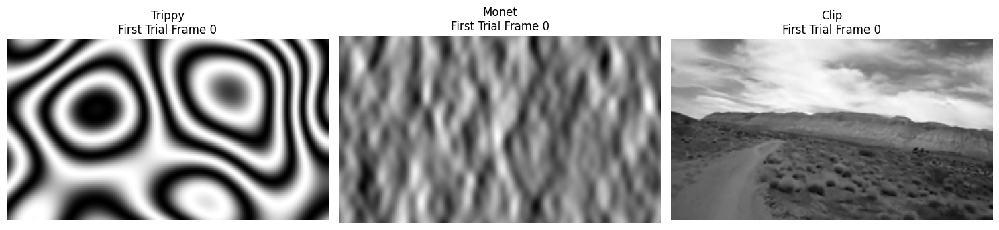

In [240]:
video_trippy = funcreader.get_video_data(h_trippy)
video_monet  = funcreader.get_video_data(h_monet)
video_clip   = funcreader.get_video_data(h_clip)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# Trippy
axes[0].imshow(video_trippy['clip'][0], cmap='gray')
axes[0].set_title("Trippy\nFirst Trial Frame 0")
axes[0].axis('off')

# Monet
axes[1].imshow(video_monet['clip'][0], cmap='gray')
axes[1].set_title("Monet\nFirst Trial Frame 0")
axes[1].axis('off')

# Clip
axes[2].imshow(video_clip['clip'][0], cmap='gray')
axes[2].set_title("Clip\nFirst Trial Frame 0")
axes[2].axis('off')

plt.tight_layout()
plt.show()

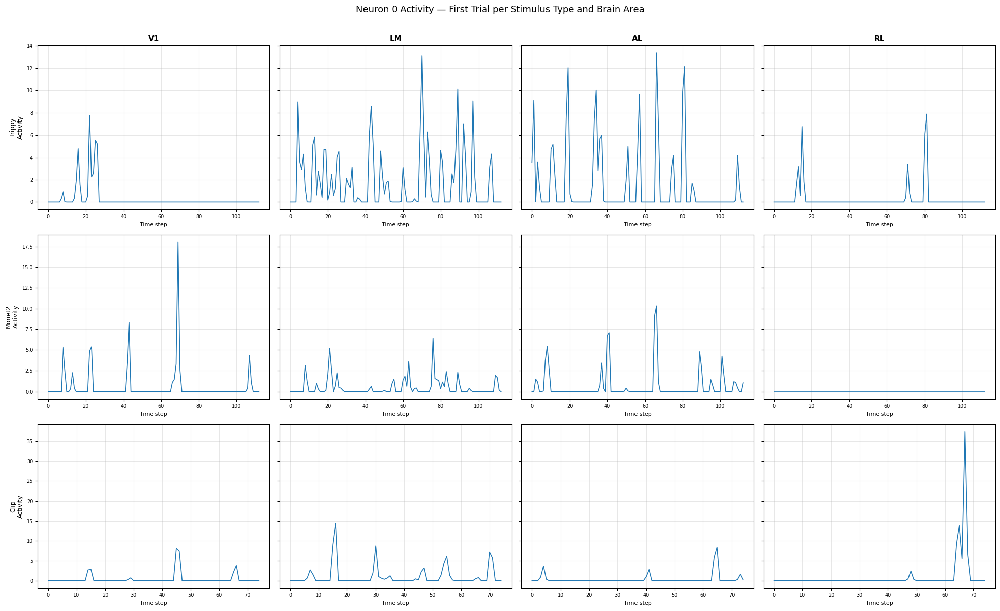

In [241]:
AREAS = ["V1", "LM", "AL", "RL"]

stim_labels = ["Trippy", "Monet2", "Clip"]
stim_hashes = [h_trippy, h_monet, h_clip]

fig, axes = plt.subplots(3, 4, figsize=(20, 12), sharey='row')

for row, (label, h) in enumerate(zip(stim_labels, stim_hashes)):
    for col, area in enumerate(AREAS):
        ax = axes[row, col]
        r  = funcreader.get_responses_by_hash(h, area)[0]
        ax.plot(r['responses'][0, :], linewidth=1.2)
        ax.set_xlabel("Time step", fontsize=8)
        if col == 0:
            ax.set_ylabel(f"{label}\nActivity", fontsize=9)
        if row == 0:
            ax.set_title(area, fontsize=11, fontweight='bold')
        ax.tick_params(labelsize=7)
        ax.grid(True, alpha=0.3)

plt.suptitle("Neuron 0 Activity — First Trial per Stimulus Type and Brain Area",
             fontsize=13, y=1.01)
plt.tight_layout()
plt.savefig("neuron0_activity_all_areas.png", dpi=150, bbox_inches='tight')
plt.show()


An example calcium activity trace for neuron 0 across stimulus types and visual areas. The traces show sparse, stimulus-dependent activity patterns, with different response profiles across cortical areas.

## Checks before starting

Above we verified that the first trial of each category has the same number of neurons per area. As an additional sanity check, we verify that this number is consistent across all trials within each category.

Moreover, we want to ensure that the recorded neurons are not only equal in number, but also correspond to the same set of neurons across trials. This guarantees that any comparison of neuronal activity across trials and categories is meaningful and based on a consistent neural population.

In [242]:
from collections import defaultdict

AREAS = ["V1", "LM", "AL", "RL"]

# Group hashes by stimulus category
stim_types = defaultdict(list)
for h in hashes:
    stim_types[funcreader.get_video_type(h)].append(h)

print("=" * 60)
print("NEURON COUNT CHECK — ALL AREAS")
print("=" * 60)

for area in AREAS:
    print(f"\n--- {area} ---")
    neurons_per_category = {}

    for stim_type, hash_list in stim_types.items():
        neuron_counts = set()
        for h in hash_list:
            r = funcreader.get_responses_by_hash(h, area)[0]
            neuron_counts.add(r["responses"].shape[0])
        neurons_per_category[stim_type] = neuron_counts

    all_consistent  = all(len(c) == 1 for c in neurons_per_category.values())
    all_counts      = {next(iter(c)) for c in neurons_per_category.values()}

    if all_consistent and len(all_counts) == 1:
        print(f"All categories share the same number of neurons: {all_counts.pop()}")
    elif all_consistent:
        print("Internally consistent, but counts differ across categories:")
        for stim_type, counts in neurons_per_category.items():
            print(f"  {stim_type}: {next(iter(counts))} neurons")
    else:
        print("Variability detected within categories:")
        for stim_type, counts in neurons_per_category.items():
            print(f"  {stim_type}: {counts}")


NEURON COUNT CHECK — ALL AREAS

--- V1 ---
All categories share the same number of neurons: 5312

--- LM ---
All categories share the same number of neurons: 983

--- AL ---
All categories share the same number of neurons: 387

--- RL ---
All categories share the same number of neurons: 811


In [243]:
AREAS = ["V1", "LM", "AL", "RL"]

# Select one trial per category (first one)
selected_hashes = {stim: hs[0] for stim, hs in stim_types.items()}

# Build hash → trial number map (done once)
hash_to_trial = {}
for trial_num, trial in f["sessions/4_7/trials"].items():
    condition_hash = trial.attrs.get("condition_hash", "")
    if isinstance(condition_hash, bytes):
        condition_hash = condition_hash.decode("utf-8")
    hash_to_trial[condition_hash] = int(trial_num)

def get_active_neurons(condition_hash, area_ids):
    trial_num = hash_to_trial[condition_hash]
    responses = f[f"sessions/4_7/trials/{trial_num}/responses"][()]
    responses_area = responses[area_ids, :]
    is_active = np.any(responses_area != 0, axis=1)
    return area_ids[is_active]

print("=" * 70)
print("NEURON ID CONSISTENCY CHECK — ALL AREAS")
print("=" * 70)

for area in AREAS:
    area_ids = f[f"sessions/4_7/meta/area_indices/{area}"][()]

    neuron_lists = {
        stim: get_active_neurons(h, area_ids)
        for stim, h in selected_hashes.items()
    }

    print(f"\n{'=' * 60}")
    print(f"AREA: {area} ({len(area_ids)} neurons total)")
    print(f"{'=' * 60}")

    for stim, h in selected_hashes.items():
        ids = neuron_lists[stim]
        print(f"\n  {stim.upper()} — Hash: {h[:12]}...")
        print(f"  Active neurons: {len(ids)}")
        print(f"  First 10 IDs: {ids[:10].tolist()}")
        print(f"  Last 10 IDs:  {ids[-10:].tolist()}")

    # Consistency check across categories
    all_equal = all(
        np.array_equal(list(neuron_lists.values())[0], arr)
        for arr in neuron_lists.values()
    )

    print()
    if all_equal:
        n = len(next(iter(neuron_lists.values())))
        print(f"  All categories share the exact same {n} active neurons")
    else:
        print("  Neuron sets differ across categories")
        common = set.intersection(*(set(v) for v in neuron_lists.values()))
        print(f"  Common neurons: {len(common)}")
        for stim, ids in neuron_lists.items():
            others = set.union(*(set(v) for k, v in neuron_lists.items() if k != stim))
            unique = set(ids) - others
            print(f"  {stim}: {len(unique)} unique neurons")


NEURON ID CONSISTENCY CHECK — ALL AREAS

AREA: V1 (5312 neurons total)

  CLIP — Hash: JEL5/i5FccX4...
  Active neurons: 5312
  First 10 IDs: [15, 18, 19, 20, 21, 22, 23, 24, 25, 27]
  Last 10 IDs:  [7478, 7480, 7481, 7483, 7486, 7488, 7489, 7490, 7491, 7492]

  MONET2 — Hash: DKYV7TrfEl+C...
  Active neurons: 5312
  First 10 IDs: [15, 18, 19, 20, 21, 22, 23, 24, 25, 27]
  Last 10 IDs:  [7478, 7480, 7481, 7483, 7486, 7488, 7489, 7490, 7491, 7492]

  TRIPPY — Hash: tRgm529SPpQs...
  Active neurons: 5312
  First 10 IDs: [15, 18, 19, 20, 21, 22, 23, 24, 25, 27]
  Last 10 IDs:  [7478, 7480, 7481, 7483, 7486, 7488, 7489, 7490, 7491, 7492]

  All categories share the exact same 5312 active neurons

AREA: LM (983 neurons total)

  CLIP — Hash: JEL5/i5FccX4...
  Active neurons: 983
  First 10 IDs: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
  Last 10 IDs:  [6910, 6912, 7112, 7222, 7269, 7283, 7324, 7361, 7443, 7482]

  MONET2 — Hash: DKYV7TrfEl+C...
  Active neurons: 983
  First 10 IDs: [0, 1, 2, 3, 4, 5,

### Sanity check

Before moving to specific clip identification, it is important to verify that the hash labels are consistent with the experimental design.

Here, a **hash** is simply a unique identifier (a code) assigned to each video clip, allowing us to track the same stimulus across repetitions.

This check ensures that:
- each clip corresponds to a unique hash,
- repetitions are correctly represented,
- and there is no overlap between categories.

Without this validation, the train/test split and the clip-identity decoding task in **Part 1.2** (and its temporal counterpart in **Part 2.2**) could be unreliable or misleading.


In [244]:
print("=" * 60)
print("DIMENSIONS OF HASH LISTS")
print("=" * 60)
print(f"monet_hashes:  {len(monet_hashes)}")
print(f"clip_hashes:   {len(clip_hashes)}")
print(f"trippy_hashes: {len(trippy_hashes)}")

# first 3 hashes per category
print("\n" + "=" * 60)
print("FIRST 3 HASHES PER CATEGORY")
print("=" * 60)

print("Monet2:")
for h in monet_hashes[:3]:
    print(f"  {h}")

print("\nClip:")
for h in clip_hashes[:3]:
    print(f"  {h}")

print("\nTrippy:")
for h in trippy_hashes[:3]:
    print(f"  {h}")

# Set of unique hashes per category
monet_set  = set(monet_hashes)
clip_set   = set(clip_hashes)
trippy_set = set(trippy_hashes)

print("\n" + "=" * 60)
print("UNIQUE HASH COUNTS")
print("=" * 60)
print(f"Monet2 uniques:  {len(monet_set)}")
print(f"Clip uniques:    {len(clip_set)}")
print(f"Trippy unques:  {len(trippy_set)}")

# Overlap among categories
overlap_tm = trippy_set & monet_set
overlap_tc = trippy_set & clip_set
overlap_mc = monet_set  & clip_set

print("\n" + "=" * 60)
print("OVERLAP AMONG CATEGORIES (unique hashes in common)")
print("=" * 60)
print(f"Trippy ∩ Monet2: {len(overlap_tm)}")
print(f"Trippy ∩ Clip:   {len(overlap_tc)}")
print(f"Monet2 ∩ Clip:   {len(overlap_mc)}")


for name, overlap in [("Trippy ∩ Monet2", overlap_tm),
                       ("Trippy ∩ Clip",   overlap_tc),
                       ("Monet2 ∩ Clip",   overlap_mc)]:
    if overlap:
        print(f"\n  Hash in common {name}:")
        for h in overlap:
            print(f"   {h}")
    else:
        print(f" No overlap {name}")

DIMENSIONS OF HASH LISTS
monet_hashes:  40
clip_hashes:   384
trippy_hashes: 40

FIRST 3 HASHES PER CATEGORY
Monet2:
  DKYV7TrfEl+C8nvadH+1
  +rgSVBVRE8Ij1WNhq8ZW
  GHn0W57E+2PS+Qr5yD2r

Clip:
  JEL5/i5FccX4ykUOKaDW
  AAQ1HNKGrg1cIXlMw7nz
  ksTS42zV+O0YJqa0+s4Y

Trippy:
  tRgm529SPpQspr220FRm
  bPIYtu0PZKbei9UFlwH6
  2L0dFgMONTKcgyZJiM/T

UNIQUE HASH COUNTS
Monet2 uniques:  20
Clip uniques:    240
Trippy unques:  20

OVERLAP AMONG CATEGORIES (unique hashes in common)
Trippy ∩ Monet2: 0
Trippy ∩ Clip:   0
Monet2 ∩ Clip:   0
 No overlap Trippy ∩ Monet2
 No overlap Trippy ∩ Clip
 No overlap Monet2 ∩ Clip


# Part 1: Static Analysis

## Part 1.1: Stimulus Category Classification


### Rationale and Experimental Design

To decode stimulus category identity (Clip / Monet2 / Trippy) from neural population activity, we recorded responses from four visual areas of the mouse cortex: **V1** (primary visual cortex), **LM** (lateromedial area), **AL** (anterolateral area), and **RL** (rostrolateral area), using the MICrONs functional connectomics dataset (session 4_7).

---

### Deduplication — Removing Repeated Presentations

Each hash is a unique identifier for a **specific clip**. The same clip can be shown multiple times, so using all hashes without deduplication causes **data leakage** (same clip in both train and test).

Unique hashes per category:
- **Monet2**: 40 total → **20 unique** clips
- **Trippy**: 40 total → **20 unique** clips
- **Clip**: 384 total → **240 unique** clips

---

### Dataset Construction — Balancing Across Classes

We randomly sample **20 unique clips** from Clip to match the size of Monet2 and Trippy: 20 clips × 3 classes = 60 trials total.

---

### Train/Test Split — At the Trial Level

Split ratio: **80/20** → 16 train + 4 test trials per class (48 train / 12 test), performed separately per class before extracting timepoints.

---

### Temporal Subsampling — 11 Uniformly Spaced Timepoints per Trial

Each trial is subsampled to **11 timepoints**, giving 528 training samples and 132 test samples per area.

---

### V1 — Full Population (5312 neurons)

As a first analysis, classification is performed on **V1 using all 5312 recorded neurons**, without any dimensionality reduction or subsampling. This establishes an upper-bound reference for how much stimulus-category information the full V1 population carries.

---

### Cross-Area Equalization via Random Subsampling

A central challenge in comparing decoding performance across brain areas is the **substantial difference in recorded population size**: V1 contributes 5312 neurons, LM 983, RL 811, and AL only 387. Naively training a classifier on the full population of each area would confound neural information content with population size — larger areas would have an inherent advantage simply due to more features.

To achieve a **fair cross-area comparison**, we adopted a **random subsampling strategy**: for V1, LM, and RL, we randomly drew **N = 387 neurons** (matching AL, the smallest area) from the full population without replacement. For AL, all 387 neurons were used. This was repeated **30 times** with different random seeds, and classification accuracy and F1 score were averaged across iterations to obtain stable estimates (mean ± std).

This approach is **biologically motivated**: it asks whether a random sample of N neurons from a given area carries stimulus category information, without imposing any prior assumption about which neurons are most informative. Crucially, the **variance across iterations** is itself an informative quantity:
- **Low variance** across seeds indicates that stimulus information is **distributed homogeneously** across the population — any random sample of N neurons is approximately equally informative.
- **High variance** suggests that information is **concentrated in a sparse neuronal subpopulation** — some random draws happen to include the most informative neurons, others do not.

---

### Classifiers

Two classifiers were evaluated:
- **Random Forest (RF)**: 100 trees, max depth 20 — a non-linear ensemble method robust to correlated features.
- **Logistic Regression (LR)**: L2 regularization, `lbfgs` solver — assumes linear separability of class representations in neural state space.

The **chance-level baseline** for a balanced 3-class problem is **33.3%**.

---


Unique hashes per category (after deduplication):
   Monet2: 20
   Trippy: 20
   Clip:   240

Balanced dataset: 20 unique clips per category
Split (per category): 16 train | 4 test



BUILDING DATASETS — all neurons per area (no subsampling)

V1: 5312 neurons
   X_train: (528, 5312) | X_test: (132, 5312)
   Saved → 'dataset_classification_V1.npz'

LM: 983 neurons
   X_train: (528, 983) | X_test: (132, 983)
   Saved → 'dataset_classification_LM.npz'

AL: 387 neurons
   X_train: (528, 387) | X_test: (132, 387)
   Saved → 'dataset_classification_AL.npz'

RL: 811 neurons
   X_train: (528, 811) | X_test: (132, 811)
   Saved → 'dataset_classification_RL.npz'

All datasets saved.


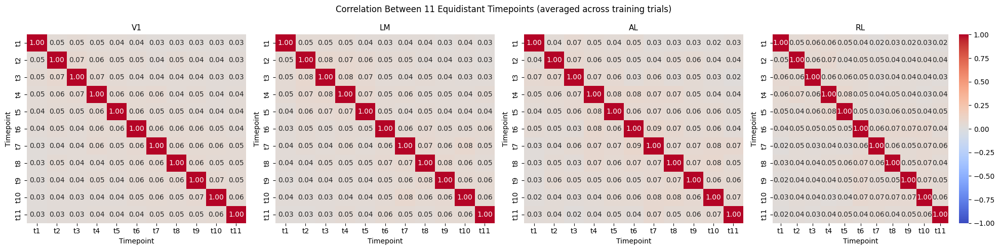

In [245]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler

AREAS       = ["V1", "LM", "AL", "RL"]
N_TRIALS    = 20
N_TIME      = 11
TEST_SIZE   = 0.2
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

monet_unique  = sorted(set(monet_hashes))
trippy_unique = sorted(set(trippy_hashes))
clip_unique   = sorted(set(clip_hashes))

print("Unique hashes per category (after deduplication):")
print(f"   Monet2: {len(monet_unique)}")
print(f"   Trippy: {len(trippy_unique)}")
print(f"   Clip:   {len(clip_unique)}")

clip_selected = list(np.random.choice(clip_unique, N_TRIALS, replace=False))
print(f"\nBalanced dataset: {N_TRIALS} unique clips per category")

monet_train,  monet_test  = train_test_split(monet_unique,  test_size=TEST_SIZE, random_state=RANDOM_SEED)
clip_train,   clip_test   = train_test_split(clip_selected, test_size=TEST_SIZE, random_state=RANDOM_SEED)
trippy_train, trippy_test = train_test_split(trippy_unique, test_size=TEST_SIZE, random_state=RANDOM_SEED)

print(f"Split (per category): {len(monet_train)} train | {len(monet_test)} test")

def extract_trial(funcreader, hash_val, area, n_time):
    r = funcreader.get_responses_by_hash(hash_val, area)[0]
    responses = r["responses"]
    indices = np.linspace(0, responses.shape[1] - 1, n_time, dtype=int)
    return responses[:, indices].T   # (n_time, n_neurons)

def build_split(funcreader, hash_dict, area, n_time):
    X_list, y_list = [], []
    for label, hashes in hash_dict.items():
        for h in hashes:
            X_trial = extract_trial(funcreader, h, area, n_time)
            X_list.append(X_trial)
            y_list.extend([label] * n_time)
    return np.vstack(X_list), np.array(y_list)

le = LabelEncoder()
le.fit(["Clip", "Monet2", "Trippy"])

print("\n" + "=" * 60)
print("BUILDING DATASETS — all neurons per area (no subsampling)")
print("=" * 60)

for area in AREAS:
    X_train, y_train_raw = build_split(funcreader, {
        "Monet2": monet_train, "Clip": clip_train, "Trippy": trippy_train
    }, area, N_TIME)
    X_test, y_test_raw = build_split(funcreader, {
        "Monet2": monet_test, "Clip": clip_test, "Trippy": trippy_test
    }, area, N_TIME)

    y_train = le.transform(y_train_raw).astype(np.int64)
    y_test  = le.transform(y_test_raw).astype(np.int64)
    X_train = np.nan_to_num(X_train.astype(np.float64), nan=0.0, posinf=0.0, neginf=0.0)
    X_test  = np.nan_to_num(X_test.astype(np.float64),  nan=0.0, posinf=0.0, neginf=0.0)

    scaler  = StandardScaler()
    X_train = scaler.fit_transform(X_train)
    X_test  = scaler.transform(X_test)

    np.savez(f"dataset_classification_{area}.npz",
             X_train=X_train, X_test=X_test,
             y_train=y_train, y_test=y_test,
             classes=le.classes_)

    print(f"\n{area}: {X_train.shape[1]} neurons")
    print(f"   X_train: {X_train.shape} | X_test: {X_test.shape}")
    print(f"   Saved → 'dataset_classification_{area}.npz'")

print("\nAll datasets saved.")

# ============================================================
# Correlation matrix between the 11 timepoints
# ============================================================
fig, axes = plt.subplots(1, 4, figsize=(20, 5))
tp_labels = [f"t{i+1}" for i in range(N_TIME)]

for ax, area in zip(axes, AREAS):
    data     = np.load(f"dataset_classification_{area}.npz", allow_pickle=True)
    X        = np.nan_to_num(data['X_train'].astype(np.float64), nan=0.0)
    n_trials = X.shape[0] // N_TIME

    X_reshaped = X[:n_trials * N_TIME].reshape(n_trials, N_TIME, -1)

    corr_sum = np.zeros((N_TIME, N_TIME))
    for trial in X_reshaped:
        corr_sum += np.corrcoef(trial)
    corr_mean = corr_sum / n_trials

    sns.heatmap(corr_mean, annot=True, fmt=".2f", cmap="coolwarm",
                vmin=-1, vmax=1, ax=ax,
                xticklabels=tp_labels, yticklabels=tp_labels,
                cbar=(area == "RL"))
    ax.set_title(f"{area}", fontsize=11)
    ax.set_xlabel("Timepoint")
    ax.set_ylabel("Timepoint")

plt.suptitle(
    "Correlation Between 11 Equidistant Timepoints (averaged across training trials)",
    fontsize=12
)
plt.tight_layout()
plt.savefig("timepoint_correlation_all_areas.png", dpi=150)
plt.show()


We observe that off-diagonal correlations are close to 0 across all categories, suggesting that the sampled timepoints provide largely non-redundant snapshots of neural activity. This supports their use as separate static features.

X_train: (528, 5312) | X_test: (132, 5312)
Features: 5312 raw V1 neurons

RF: Accuracy=0.7879  F1=0.7892
LR: Accuracy=0.8409  F1=0.8406
Baseline (chance): 0.3333 (33.33%)


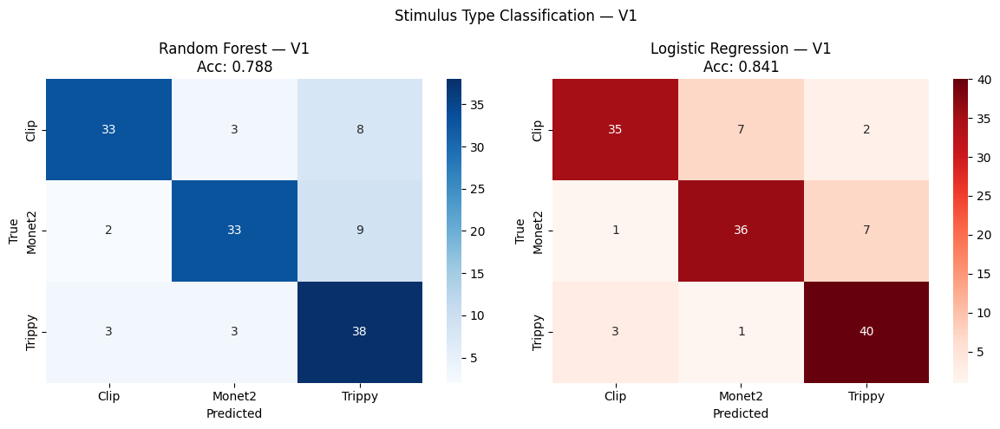

In [246]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix

data    = np.load("dataset_classification_V1.npz", allow_pickle=True)
X_train = np.nan_to_num(data['X_train'].astype(np.float64), nan=0.0)
X_test  = np.nan_to_num(data['X_test'].astype(np.float64),  nan=0.0)
y_train = data['y_train'].astype(np.int64)
y_test  = data['y_test'].astype(np.int64)
classes = data['classes']

print(f"X_train: {X_train.shape} | X_test: {X_test.shape}")
print(f"Features: {X_train.shape[1]} raw V1 neurons")

# Random Forest
rf = RandomForestClassifier(n_estimators=100, max_depth=20, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)
acc_rf = accuracy_score(y_test, y_pred_rf)
f1_rf  = f1_score(y_test, y_pred_rf, average='weighted')

# Logistic Regression
lr = LogisticRegression(max_iter=1000, random_state=42, solver='lbfgs')
lr.fit(X_train, y_train)
y_pred_lr = lr.predict(X_test)
acc_lr = accuracy_score(y_test, y_pred_lr)
f1_lr  = f1_score(y_test, y_pred_lr, average='weighted')

print(f"\nRF: Accuracy={acc_rf:.4f}  F1={f1_rf:.4f}")
print(f"LR: Accuracy={acc_lr:.4f}  F1={f1_lr:.4f}")
print(f"Baseline (chance): {1/3:.4f} (33.33%)")

# Confusion matrices
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, y_pred, title, cmap in zip(
    axes,
    [y_pred_rf, y_pred_lr],
    ['Random Forest', 'Logistic Regression'],
    ['Blues', 'Reds']
):
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap=cmap,
                xticklabels=classes, yticklabels=classes, ax=ax)
    acc = acc_rf if title == 'Random Forest' else acc_lr
    ax.set_title(f"{title} — V1\nAcc: {acc:.3f}")
    ax.set_xlabel('Predicted')
    ax.set_ylabel('True')

plt.suptitle('Stimulus Type Classification — V1', fontsize=12)
plt.tight_layout()
plt.savefig('classification_V1_nopca.png', dpi=150)
plt.show()


### Results 
Using the full V1 population of 5312 neurons, both classifiers decoded stimulus category well above the 33.3% chance baseline. **Logistic Regression reached the higher accuracy (0.8409, F1 = 0.8406)**, while Random Forest came close behind (0.7879, F1 = 0.7892).

This suggests that, when the full V1 population is available, broad stimulus category information is strongly represented and is at least partly linearly separable in the population activity space.

Therefore, high V1 decoding accuracy should be interpreted as evidence for stimulus-related visual information in V1, not necessarily as evidence for high-level category representation.


### What Are the Most Important Neurons Doing? (V1)

Having trained the classifiers on V1, we can now identify which neurons were most influential for distinguishing the three stimulus categories and examine their actual activity traces during Clip, Monet2, and Trippy trials.

- **For Random Forest**, importance is measured by mean decrease in impurity (feature importance).
- **For Logistic Regression**, importance is measured by the L2 norm of the coefficient vector across all three classes.

For each classifier, we select the **top 10 most important neurons** and plot their mean activity across the 11 sampled timepoints, separately for each stimulus category. This reveals whether these neurons show category-selective responses and whether their tuning profiles differ between the two classifiers' preferred neurons.

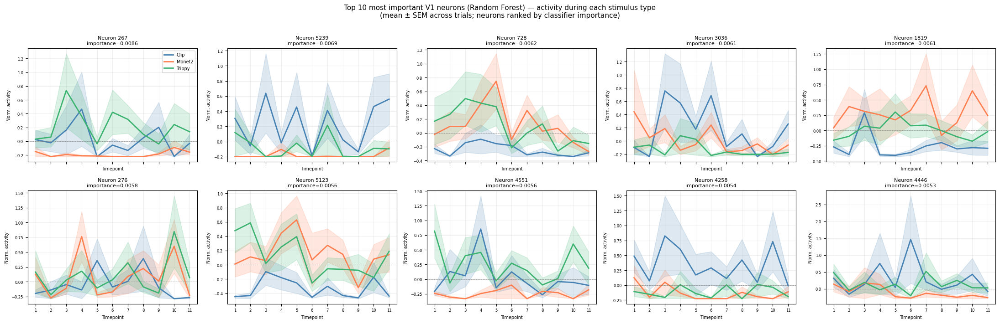

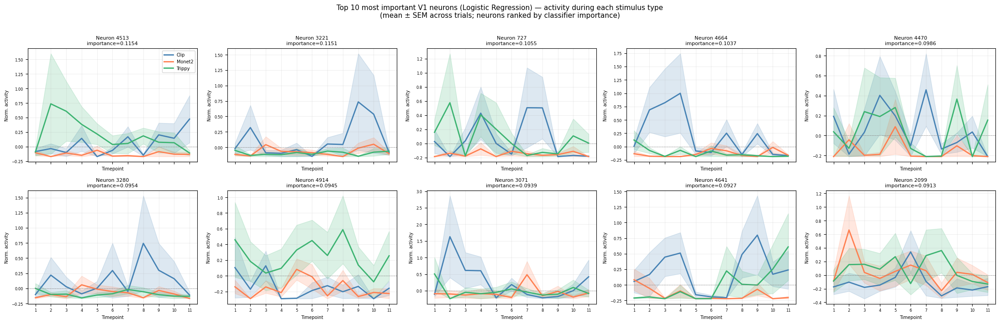


Neurons in both RF and LR top-10: []
Overlap count: 0 / 10


In [247]:
# ============================================================
# Most important neurons for static classification — V1
# What do they do during different stimulus types?
# ============================================================
import numpy as np
import matplotlib.pyplot as plt

# Reload V1 dataset
data_v1    = np.load("dataset_classification_V1.npz", allow_pickle=True)
X_train_v1 = np.nan_to_num(data_v1['X_train'].astype(np.float64), nan=0.0)
X_test_v1  = np.nan_to_num(data_v1['X_test'].astype(np.float64),  nan=0.0)
y_train_v1 = data_v1['y_train'].astype(np.int64)
y_test_v1  = data_v1['y_test'].astype(np.int64)
classes_v1 = data_v1['classes']          # ['Clip', 'Monet2', 'Trippy']

# Use full dataset (train + test) for plotting activity
X_all = np.vstack([X_train_v1, X_test_v1])
y_all = np.concatenate([y_train_v1, y_test_v1])

N_TOP       = 10      # how many top neurons to show
N_TIME      = 11      # timepoints per trial window
stim_colors = ['steelblue', 'coral', 'mediumseagreen']

# ----------------------------------------------------------
# Helper: reshape flat samples back to (n_trials, N_TIME, n_neurons)
# Each trial contributed N_TIME rows to X_all
# ----------------------------------------------------------
def reshape_to_trials(X, y, n_time):
    """Return X as (n_trials, n_time, n_neurons) and matching label array."""
    assert X.shape[0] % n_time == 0
    n_trials = X.shape[0] // n_time
    X_3d = X.reshape(n_trials, n_time, X.shape[1])
    y_trial = y[::n_time]           # one label per trial
    return X_3d, y_trial

X_3d, y_trial = reshape_to_trials(X_all, y_all, N_TIME)

# ----------------------------------------------------------
# Importance from RF (already trained above)
# ----------------------------------------------------------
rf_importance  = rf.feature_importances_          # (n_neurons,)
top_rf_idx     = np.argsort(rf_importance)[::-1][:N_TOP]

# Importance from LR: L2 norm of coefficients across classes
lr_importance  = np.linalg.norm(lr.coef_, axis=0)  # (n_neurons,)
top_lr_idx     = np.argsort(lr_importance)[::-1][:N_TOP]

timepoints = np.arange(1, N_TIME + 1)

# ----------------------------------------------------------
# Plot function
# ----------------------------------------------------------
def plot_top_neurons(top_idx, importance_vals, classifier_name, filename):
    fig, axes = plt.subplots(
        2, N_TOP // 2, figsize=(22, 7),
        sharex=True, sharey=False
    )
    axes = axes.flatten()

    for rank, (ax, neuron_idx) in enumerate(zip(axes, top_idx)):
        for cls_idx, (cls_name, color) in enumerate(zip(classes_v1, stim_colors)):
            mask = y_trial == cls_idx
            # Mean activity trace across trials for this class
            traces = X_3d[mask, :, neuron_idx]   # (n_trials_cls, N_TIME)
            mean_trace = traces.mean(axis=0)
            sem_trace  = traces.std(axis=0) / np.sqrt(mask.sum())

            ax.plot(timepoints, mean_trace, color=color,
                    linewidth=2, label=cls_name)
            ax.fill_between(
                timepoints,
                mean_trace - sem_trace,
                mean_trace + sem_trace,
                alpha=0.18, color=color
            )

        imp_val = importance_vals[neuron_idx]
        ax.set_title(f"Neuron {neuron_idx}\nimportance={imp_val:.4f}",
                     fontsize=8)
        ax.set_xlabel("Timepoint", fontsize=7)
        ax.set_ylabel("Norm. activity", fontsize=7)
        ax.tick_params(labelsize=6)
        ax.set_xticks(timepoints)
        ax.axhline(0, color='gray', linewidth=0.5, linestyle='--')
        ax.grid(True, alpha=0.2)
        if rank == 0:
            ax.legend(fontsize=7, loc='upper right')

    fig.suptitle(
        f"Top {N_TOP} most important V1 neurons ({classifier_name}) — "
        f"activity during each stimulus type\n"
        f"(mean ± SEM across trials; neurons ranked by classifier importance)",
        fontsize=11, y=1.01
    )
    plt.tight_layout()
    plt.savefig(filename, dpi=150, bbox_inches='tight')
    plt.show()


# ----------------------------------------------------------
# Run for both classifiers
# ----------------------------------------------------------
plot_top_neurons(top_rf_idx, rf_importance,
                 "Random Forest",
                 "top_neurons_RF_activity.png")

plot_top_neurons(top_lr_idx, lr_importance,
                 "Logistic Regression",
                 "top_neurons_LR_activity.png")

# ----------------------------------------------------------
# Summary: overlap between the two classifiers' top neurons
# ----------------------------------------------------------
overlap = set(top_rf_idx) & set(top_lr_idx)
print(f"\nNeurons in both RF and LR top-{N_TOP}: {sorted(overlap)}")
print(f"Overlap count: {len(overlap)} / {N_TOP}")


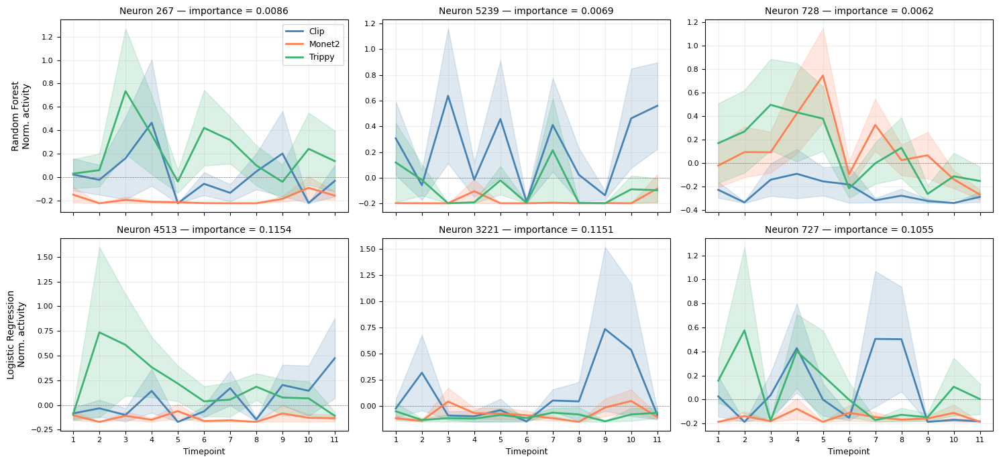


Neurons in both RF and LR top-3: []
Overlap count: 0 / 3


In [248]:
# ============================================================
# Most important neurons for static classification — V1
# What do they do during different stimulus types?
# ============================================================
import numpy as np
import matplotlib.pyplot as plt

# Reload V1 dataset
data_v1    = np.load("dataset_classification_V1.npz", allow_pickle=True)
X_train_v1 = np.nan_to_num(data_v1['X_train'].astype(np.float64), nan=0.0)
X_test_v1  = np.nan_to_num(data_v1['X_test'].astype(np.float64),  nan=0.0)
y_train_v1 = data_v1['y_train'].astype(np.int64)
y_test_v1  = data_v1['y_test'].astype(np.int64)
classes_v1 = data_v1['classes']          # ['Clip', 'Monet2', 'Trippy']

X_all = np.vstack([X_train_v1, X_test_v1])
y_all = np.concatenate([y_train_v1, y_test_v1])

N_TOP       = 3
N_TIME      = 11
stim_colors = ['steelblue', 'coral', 'mediumseagreen']

# ----------------------------------------------------------
# Reshape flat samples back to (n_trials, N_TIME, n_neurons)
# ----------------------------------------------------------
def reshape_to_trials(X, y, n_time):
    assert X.shape[0] % n_time == 0
    n_trials = X.shape[0] // n_time
    X_3d = X.reshape(n_trials, n_time, X.shape[1])
    y_trial = y[::n_time]
    return X_3d, y_trial

X_3d, y_trial = reshape_to_trials(X_all, y_all, N_TIME)

# ----------------------------------------------------------
# Compute top-N neurons per classifier
# ----------------------------------------------------------
rf_importance = rf.feature_importances_
lr_importance = np.linalg.norm(lr.coef_, axis=0)
top_rf_idx    = np.argsort(rf_importance)[::-1][:N_TOP]
top_lr_idx    = np.argsort(lr_importance)[::-1][:N_TOP]

timepoints = np.arange(1, N_TIME + 1)

# ----------------------------------------------------------
# Single figure with 2 rows × 3 cols (RF on top, LR on bottom)
# ----------------------------------------------------------
fig, axes = plt.subplots(2, N_TOP, figsize=(15, 7),
                         sharex=True, sharey=False)

rows = [
    ("Random Forest",       top_rf_idx, rf_importance),
    ("Logistic Regression", top_lr_idx, lr_importance),
]

for row_idx, (clf_name, top_idx, importance_vals) in enumerate(rows):
    for col_idx, neuron_idx in enumerate(top_idx):
        ax = axes[row_idx, col_idx]

        for cls_idx, (cls_name, color) in enumerate(zip(classes_v1, stim_colors)):
            mask       = y_trial == cls_idx
            traces     = X_3d[mask, :, neuron_idx]            # (n_trials_cls, N_TIME)
            mean_trace = traces.mean(axis=0)
            sem_trace  = traces.std(axis=0) / np.sqrt(mask.sum())

            ax.plot(timepoints, mean_trace, color=color, linewidth=2, label=cls_name)
            ax.fill_between(timepoints,
                            mean_trace - sem_trace,
                            mean_trace + sem_trace,
                            alpha=0.18, color=color)

        imp_val = importance_vals[neuron_idx]
        ax.set_title(f"Neuron {neuron_idx} — importance = {imp_val:.4f}",
                     fontsize=10)
        ax.axhline(0, color='gray', linewidth=0.5, linestyle='--')
        ax.grid(True, alpha=0.2)
        ax.set_xticks(timepoints)
        ax.tick_params(labelsize=8)

        if col_idx == 0:
            ax.set_ylabel(f"{clf_name}\nNorm. activity", fontsize=10)
        if row_idx == 1:
            ax.set_xlabel("Timepoint", fontsize=9)
        if row_idx == 0 and col_idx == 0:
            ax.legend(fontsize=9, loc='upper right')

plt.tight_layout()
plt.savefig("top_neurons_RF_LR_activity.png", dpi=150, bbox_inches='tight')
plt.show()

# ----------------------------------------------------------
# Summary: overlap between the two classifiers' top neurons
# ----------------------------------------------------------
overlap = set(top_rf_idx) & set(top_lr_idx)
print(f"\nNeurons in both RF and LR top-{N_TOP}: {sorted(overlap)}")
print(f"Overlap count: {len(overlap)} / {N_TOP}")

RANDOM SUBSAMPLING — 387 neurons × 30 iterations

V1 (5312 neurons → subsample to 387)
   RF: Acc=0.7149 ± 0.0462  F1=0.7155 ± 0.0461
   LR: Acc=0.6167 ± 0.0443  F1=0.6141 ± 0.0454

LM (983 neurons → subsample to 387)
   RF: Acc=0.7528 ± 0.0371  F1=0.7484 ± 0.0384
   LR: Acc=0.6205 ± 0.0454  F1=0.6152 ± 0.0456

AL (387 neurons → subsample to all 387)
   RF: Acc=0.7955 ± 0.0000  F1=0.7958 ± 0.0000
   LR: Acc=0.5985 ± 0.0000  F1=0.5975 ± 0.0000

RL (811 neurons → subsample to 387)
   RF: Acc=0.7487 ± 0.0342  F1=0.7513 ± 0.0336
   LR: Acc=0.6705 ± 0.0304  F1=0.6688 ± 0.0314


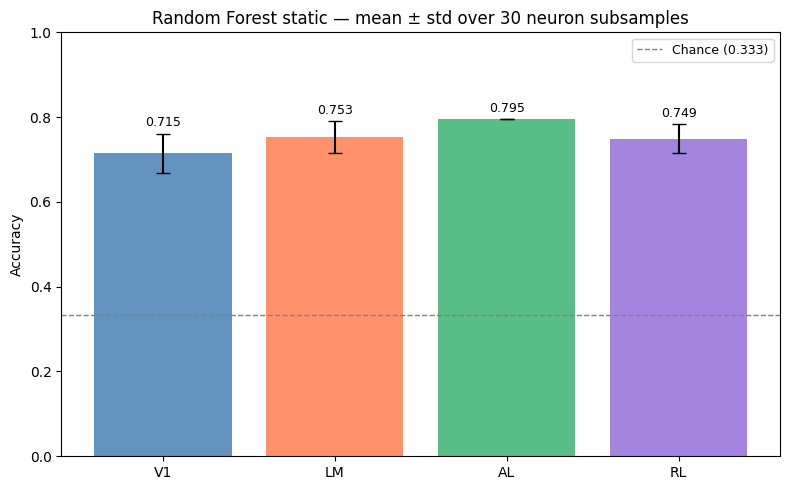

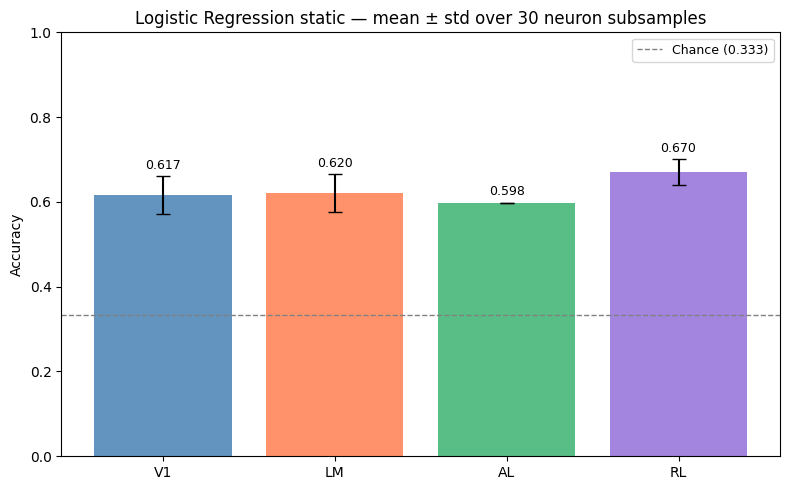

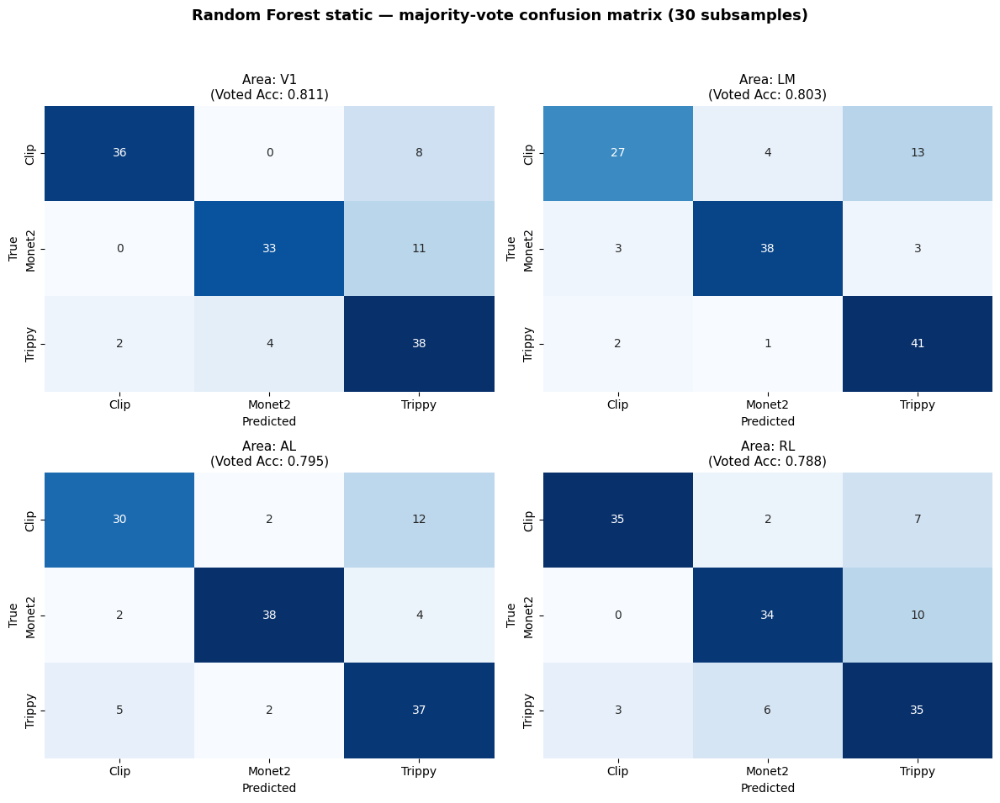

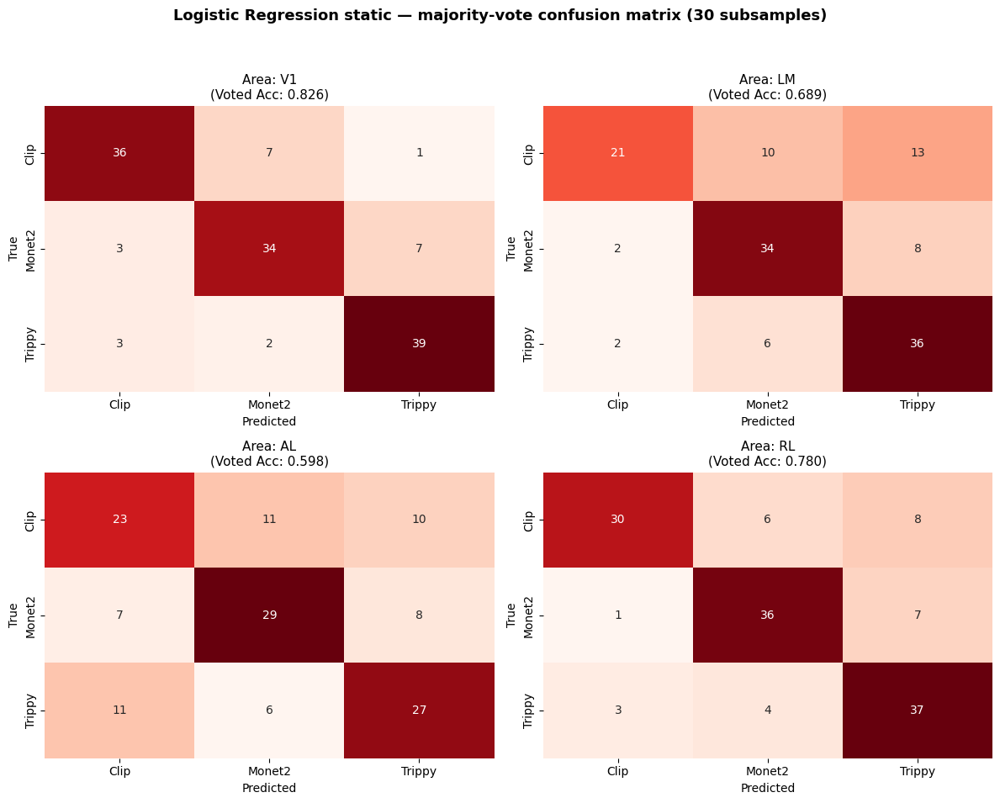


Area   Classifier       Acc (mean±std)        F1 (mean±std)  vs chance
V1     RF     0.7149 ± 0.0462   0.7155 ± 0.0461   +38.2pp
V1     LR     0.6167 ± 0.0443   0.6141 ± 0.0454   +28.3pp
LM     RF     0.7528 ± 0.0371   0.7484 ± 0.0384   +41.9pp
LM     LR     0.6205 ± 0.0454   0.6152 ± 0.0456   +28.7pp
AL     RF     0.7955 ± 0.0000   0.7958 ± 0.0000   +46.2pp
AL     LR     0.5985 ± 0.0000   0.5975 ± 0.0000   +26.5pp
RL     RF     0.7487 ± 0.0342   0.7513 ± 0.0336   +41.5pp
RL     LR     0.6705 ± 0.0304   0.6688 ± 0.0314   +33.7pp


In [249]:
AREAS      = ["V1", "LM", "AL", "RL"]
N_NEURONS  = 387
N_ITER     = 30
RANDOM_SEED = 42

print("=" * 65)
print(f"RANDOM SUBSAMPLING — {N_NEURONS} neurons × {N_ITER} iterations")
print("=" * 65)

# Added: 'preds' list to store per-iteration predictions
all_results = {area: {'RF': {'acc': [], 'f1': [], 'preds': []},
                       'LR': {'acc': [], 'f1': [], 'preds': []}}
               for area in AREAS}

type_rf_importance_accum = {}
type_lr_importance_accum = {}
type_subsample_counts    = {}

# Added: store y_test and classes per area for the confusion matrix
all_y_test = {}
classes    = None

for area in AREAS:
    data    = np.load(f"dataset_classification_{area}.npz", allow_pickle=True)
    X_train = np.nan_to_num(data['X_train'].astype(np.float64), nan=0.0)
    X_test  = np.nan_to_num(data['X_test'].astype(np.float64),  nan=0.0)
    y_train = data['y_train'].astype(np.int64)
    y_test  = data['y_test'].astype(np.int64)
    n_neurons = X_train.shape[1]

    all_y_test[area] = y_test
    if classes is None:
        classes = data['classes']

    print(f"\n{area} ({n_neurons} neurons → subsample to {N_NEURONS if area != 'AL' else 'all 387'})")

    rf_imp_sum  = np.zeros(n_neurons)
    lr_imp_sum  = np.zeros(n_neurons)
    count_seen  = np.zeros(n_neurons, dtype=int)

    for i in range(N_ITER):
        rng = np.random.default_rng(RANDOM_SEED + i)

        if area == "AL":
            idx = np.arange(n_neurons)
        else:
            idx = rng.choice(n_neurons, size=N_NEURONS, replace=False)

        X_tr = X_train[:, idx]
        X_te = X_test[:, idx]

        # Random Forest
        rf_sub = RandomForestClassifier(n_estimators=100, max_depth=20,
                                        random_state=42, n_jobs=-1)
        rf_sub.fit(X_tr, y_train)
        y_pred_rf = rf_sub.predict(X_te)
        all_results[area]['RF']['acc'].append(accuracy_score(y_test, y_pred_rf))
        all_results[area]['RF']['f1'].append(f1_score(y_test, y_pred_rf, average='weighted'))
        all_results[area]['RF']['preds'].append(y_pred_rf)
        rf_imp_sum[idx] += rf_sub.feature_importances_

        # Logistic Regression
        lr_sub = LogisticRegression(max_iter=1000, random_state=42, solver='lbfgs')
        lr_sub.fit(X_tr, y_train)
        y_pred_lr = lr_sub.predict(X_te)
        all_results[area]['LR']['acc'].append(accuracy_score(y_test, y_pred_lr))
        all_results[area]['LR']['f1'].append(f1_score(y_test, y_pred_lr, average='weighted'))
        all_results[area]['LR']['preds'].append(y_pred_lr)
        lr_imp_sum[idx] += np.linalg.norm(lr_sub.coef_, axis=0)

        count_seen[idx] += 1

    count_safe = np.where(count_seen > 0, count_seen, 1)
    type_rf_importance_accum[area] = rf_imp_sum / count_safe
    type_lr_importance_accum[area] = lr_imp_sum / count_safe
    type_subsample_counts[area]    = count_seen

    for clf in ['RF', 'LR']:
        acc_mean = np.mean(all_results[area][clf]['acc'])
        acc_std  = np.std(all_results[area][clf]['acc'])
        f1_mean  = np.mean(all_results[area][clf]['f1'])
        f1_std   = np.std(all_results[area][clf]['f1'])
        print(f"   {clf}: Acc={acc_mean:.4f} ± {acc_std:.4f}  "
              f"F1={f1_mean:.4f} ± {f1_std:.4f}")


# ============================================================
# Bar chart per classifier (RF, then LR) — colors per area like GRU
# ============================================================
colors  = ["steelblue", "coral", "mediumseagreen", "mediumpurple"]
chance  = 1/3

# --- Random Forest ---
fig, ax = plt.subplots(figsize=(8, 5))
means = [np.mean(all_results[a]['RF']['acc']) for a in AREAS]
stds  = [np.std(all_results[a]['RF']['acc'])  for a in AREAS]
bars  = ax.bar(AREAS, means, yerr=stds, capsize=5,
               color=colors, alpha=0.85,
               error_kw={"linewidth": 1.5})
ax.axhline(chance, color='gray', linestyle='--', linewidth=1, label=f'Chance ({chance:.3f})')
ax.set_ylabel("Accuracy")
ax.set_title(f"Random Forest static — mean ± std over {N_ITER} neuron subsamples")
ax.set_ylim(0, 1.0)
ax.legend(fontsize=9, loc="upper right")
for bar, m, s in zip(bars, means, stds):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + s + 0.01,
            f"{m:.3f}", ha="center", va="bottom", fontsize=9)
plt.tight_layout()
plt.savefig("classification_subsampling_RF.png", dpi=150)
plt.show()

# --- Logistic Regression ---
fig, ax = plt.subplots(figsize=(8, 5))
means = [np.mean(all_results[a]['LR']['acc']) for a in AREAS]
stds  = [np.std(all_results[a]['LR']['acc'])  for a in AREAS]
bars  = ax.bar(AREAS, means, yerr=stds, capsize=5,
               color=colors, alpha=0.85,
               error_kw={"linewidth": 1.5})
ax.axhline(chance, color='gray', linestyle='--', linewidth=1, label=f'Chance ({chance:.3f})')
ax.set_ylabel("Accuracy")
ax.set_title(f"Logistic Regression static — mean ± std over {N_ITER} neuron subsamples")
ax.set_ylim(0, 1.0)
ax.legend(fontsize=9, loc="upper right")
for bar, m, s in zip(bars, means, stds):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + s + 0.01,
            f"{m:.3f}", ha="center", va="bottom", fontsize=9)
plt.tight_layout()
plt.savefig("classification_subsampling_LR.png", dpi=150)
plt.show()


# ============================================================
# 2x2 Majority-vote confusion matrix per area — Random Forest
# ============================================================
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
fig.suptitle(f"Random Forest static — majority-vote confusion matrix "
             f"({N_ITER} subsamples)", fontsize=13, fontweight='bold')
axes_flat = axes.flatten()

for i, area in enumerate(AREAS):
    ax = axes_flat[i]
    seed_preds = np.stack(all_results[area]['RF']['preds'])
    n_classes  = len(classes)
    majority = np.apply_along_axis(
        lambda x: np.bincount(x, minlength=n_classes).argmax(),
        axis=0, arr=seed_preds
    )
    y_test    = all_y_test[area]
    cm        = confusion_matrix(y_test, majority)
    voted_acc = accuracy_score(y_test, majority)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=ax,
                xticklabels=classes, yticklabels=classes, cbar=False)
    ax.set_title(f"Area: {area}\n(Voted Acc: {voted_acc:.3f})", fontsize=11)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("True")

for j in range(len(AREAS), len(axes_flat)):
    fig.delaxes(axes_flat[j])

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.savefig("videotype_static_RF_voted_cm_2x2.png", dpi=150)
plt.show()


# ============================================================
# 2x2 Majority-vote confusion matrix per area — Logistic Regression
# ============================================================
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
fig.suptitle(f"Logistic Regression static — majority-vote confusion matrix "
             f"({N_ITER} subsamples)", fontsize=13, fontweight='bold')
axes_flat = axes.flatten()

for i, area in enumerate(AREAS):
    ax = axes_flat[i]
    seed_preds = np.stack(all_results[area]['LR']['preds'])
    n_classes  = len(classes)
    majority = np.apply_along_axis(
        lambda x: np.bincount(x, minlength=n_classes).argmax(),
        axis=0, arr=seed_preds
    )
    y_test    = all_y_test[area]
    cm        = confusion_matrix(y_test, majority)
    voted_acc = accuracy_score(y_test, majority)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Reds", ax=ax,
                xticklabels=classes, yticklabels=classes, cbar=False)
    ax.set_title(f"Area: {area}\n(Voted Acc: {voted_acc:.3f})", fontsize=11)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("True")

for j in range(len(AREAS), len(axes_flat)):
    fig.delaxes(axes_flat[j])

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.savefig("videotype_static_LR_voted_cm_2x2.png", dpi=150)
plt.show()


# ============================================================
# Summary table (matching the GRU style)
# ============================================================
print("\n" + "=" * 70)
print(f"{'Area':<6} {'Classifier':<6} {'Acc (mean±std)':>20} {'F1 (mean±std)':>20} {'vs chance':>10}")
print("=" * 70)
for area in AREAS:
    for clf in ['RF', 'LR']:
        accs = all_results[area][clf]['acc']
        f1s  = all_results[area][clf]['f1']
        print(f"{area:<6} {clf:<6} "
              f"{np.mean(accs):.4f} ± {np.std(accs):.4f}   "
              f"{np.mean(f1s):.4f} ± {np.std(f1s):.4f}   "
              f"+{(np.mean(accs) - 1/3)*100:.1f}pp")

### Results

All four visual areas decode stimulus category well above the 33.3% chance baseline, confirming that **population-level representations of stimulus category are present throughout the visual hierarchy**, not confined to primary visual cortex.

**With 387 neurons, RF consistently outperforms LR across all four areas** (gap of 7–20 pp depending on area), indicating that category boundaries in the matched-neuron neural space are not perfectly linearly separable. With the full V1 population the picture inverts: LR (0.8409) beats RF (0.7879), suggesting that once 5312 neurons are available, the linear structure of category representations becomes accessible to a linear classifier.

**The cross-area hierarchy with 387 neurons varies by classifier.** For RF, AL achieves the highest accuracy (0.7955, zero variance because the full 387-neuron AL population is used) followed by LM (0.7528 ± 0.037), RL (0.7487 ± 0.034) and V1 (0.7149 ± 0.046). For LR, RL leads (0.6705 ± 0.030), then LM (0.6205 ± 0.045), V1 (0.6167 ± 0.044) and AL (0.5985, zero variance). Interestingly, **AL is the strongest area for RF but the weakest for LR**, suggesting that AL's category representation is informative but not linearly separable in this 387-neuron regime.

**The cost of subsampling V1 quantifies the contribution of the full population.** Reducing V1 from 5312 to 387 neurons drops RF accuracy by ≈0.073 (0.7879 → 0.7149) and LR accuracy by ≈0.224 (0.8409 → 0.6167). LR is far more sensitive to neuron count than RF, consistent with the idea that LR exploits a fine linear combination of many features that becomes harder to recover from a small random subsample.

**The variance across subsampling iterations is moderate and broadly comparable across V1, LM and RL** (std ≈ 0.030–0.046 for both classifiers), indicating that category information is not perfectly homogeneous: different random draws of 387 neurons yield slightly different decoders. AL has zero variance by construction (the full population is used), making it the most stable reference point for cross-area comparison.


### What Are the Most Important Neurons Doing? (All Areas)

For each brain area and each classifier, we identify the **top 10 neurons** by their **aggregated importance score**, accumulated across all 30 subsampling iterations. Because a given neuron may not appear in every subsample, importance is averaged only over the iterations in which that neuron was actually included. This gives an unbiased estimate of each neuron's relevance regardless of sampling frequency.

For each top neuron we then plot its **mean activity ± SEM** across the 11 timepoints, separately for each stimulus category (Clip, Monet2, Trippy), using the full area dataset.


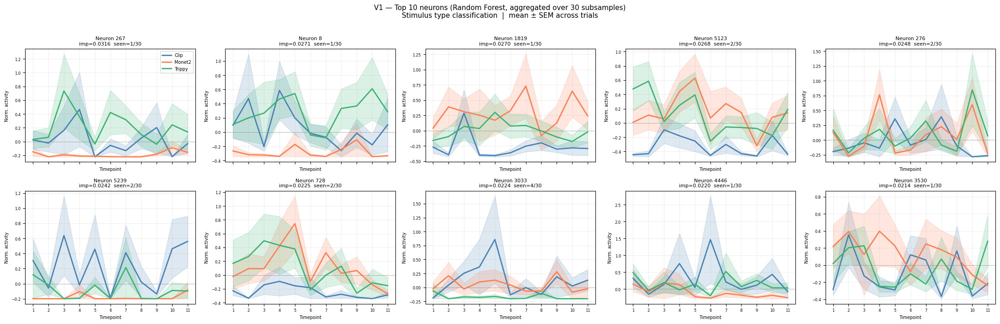

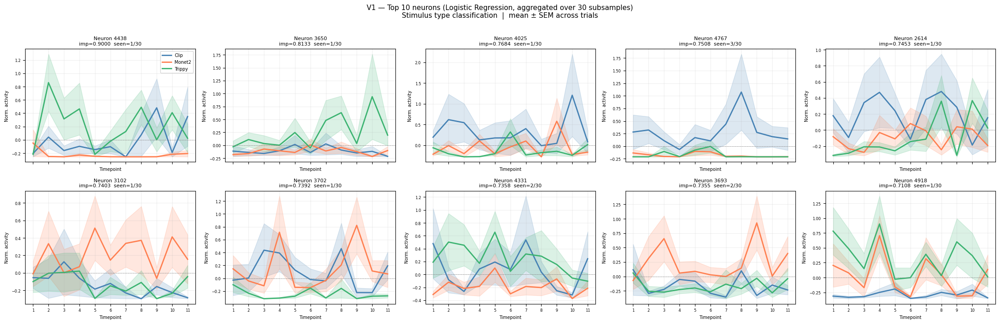

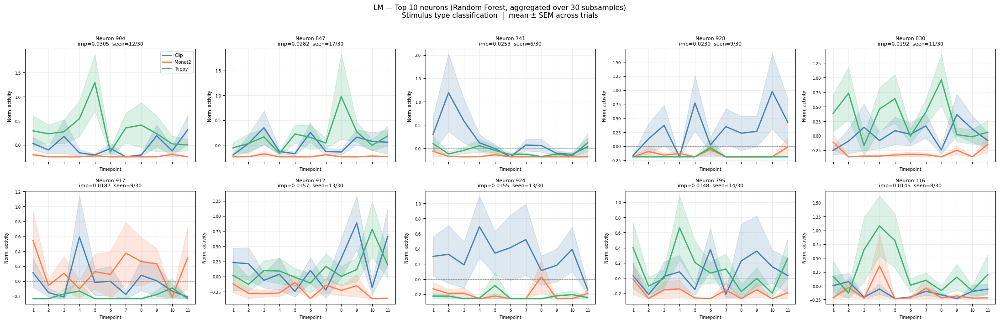

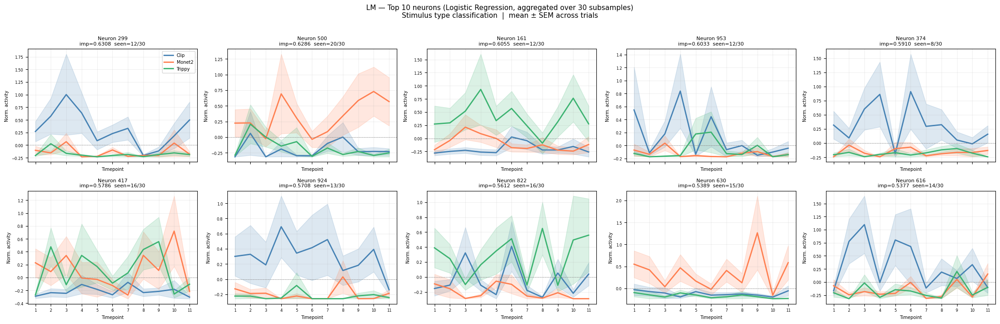

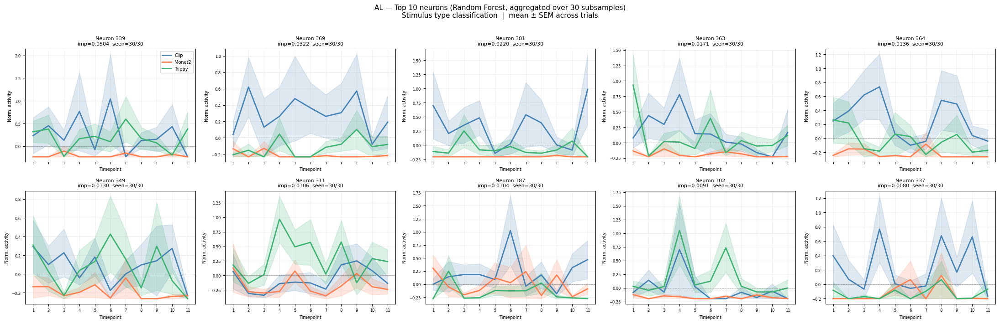

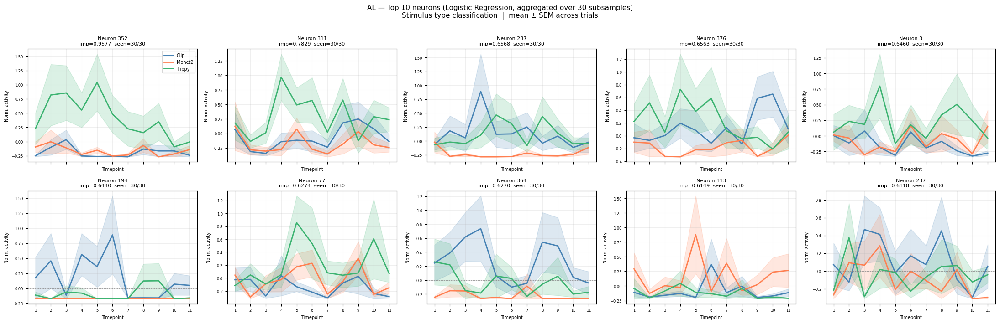

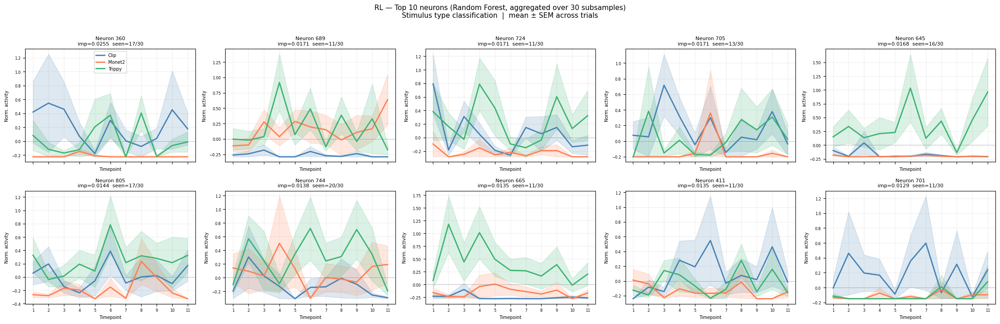

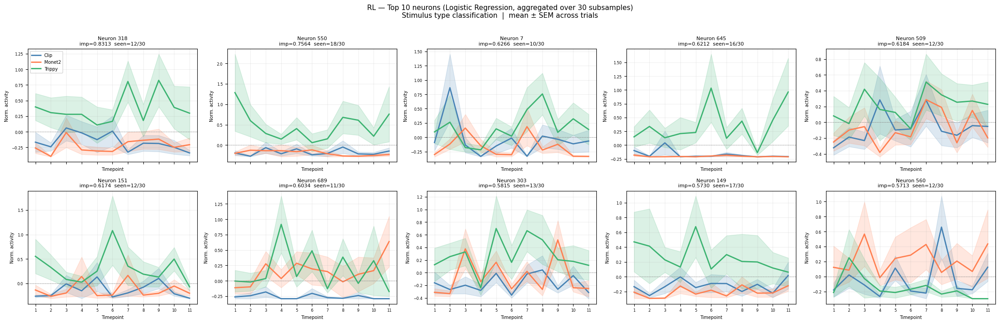

In [250]:
# ============================================================
# Top neurons per area — type classification subsampling
# What do the most important neurons do across stimulus types?
# ============================================================
N_TOP       = 10
N_TIME      = 11
stim_colors = ['steelblue', 'coral', 'mediumseagreen']
area_colors_map = {"V1": "#4878CF", "LM": "#E6693E", "AL": "#6ACC65", "RL": "#B47CC7"}

def reshape_to_trials(X, y, n_time):
    n_trials = X.shape[0] // n_time
    X_3d     = X[:n_trials * n_time].reshape(n_trials, n_time, X.shape[1])
    y_trial  = y[:n_trials * n_time:n_time]
    return X_3d, y_trial

def plot_top_neurons_area(area, imp_accum, count_seen, clf_name, filename):
    data    = np.load(f"dataset_classification_{area}.npz", allow_pickle=True)
    X_train = np.nan_to_num(data['X_train'].astype(np.float64), nan=0.0)
    X_test  = np.nan_to_num(data['X_test'].astype(np.float64),  nan=0.0)
    y_train = data['y_train'].astype(np.int64)
    y_test  = data['y_test'].astype(np.int64)
    classes = data['classes']

    X_all = np.vstack([X_train, X_test])
    y_all = np.concatenate([y_train, y_test])
    X_3d, y_trial = reshape_to_trials(X_all, y_all, N_TIME)

    # Only rank neurons that appeared in at least 1 subsample
    eligible = count_seen > 0
    imp_eligible = np.where(eligible, imp_accum, -1)
    top_idx  = np.argsort(imp_eligible)[::-1][:N_TOP]

    timepoints = np.arange(1, N_TIME + 1)
    fig, axes  = plt.subplots(2, N_TOP // 2, figsize=(22, 7), sharex=True)
    axes = axes.flatten()

    for rank, (ax, nidx) in enumerate(zip(axes, top_idx)):
        for cls_idx, (cls_name, color) in enumerate(zip(classes, stim_colors)):
            mask   = y_trial == cls_idx
            traces = X_3d[mask, :, nidx]
            mean_t = traces.mean(axis=0)
            sem_t  = traces.std(axis=0) / np.sqrt(mask.sum())
            ax.plot(timepoints, mean_t, color=color, linewidth=2, label=cls_name)
            ax.fill_between(timepoints, mean_t - sem_t, mean_t + sem_t,
                            alpha=0.18, color=color)

        n_seen = count_seen[nidx]
        ax.set_title(
            f"Neuron {nidx}\nimp={imp_accum[nidx]:.4f}  seen={n_seen}/{N_ITER}",
            fontsize=8
        )
        ax.set_xlabel("Timepoint", fontsize=7)
        ax.set_ylabel("Norm. activity", fontsize=7)
        ax.tick_params(labelsize=6)
        ax.set_xticks(timepoints)
        ax.axhline(0, color='gray', linewidth=0.5, linestyle='--')
        ax.grid(True, alpha=0.2)
        if rank == 0:
            ax.legend(fontsize=7)

    fig.suptitle(
        f"{area} — Top {N_TOP} neurons ({clf_name}, aggregated over {N_ITER} subsamples)\n"
        f"Stimulus type classification  |  mean ± SEM across trials",
        fontsize=11, y=1.01
    )
    plt.tight_layout()
    plt.savefig(filename, dpi=150, bbox_inches='tight')
    plt.show()
    

for area in AREAS:
    plot_top_neurons_area(
        area,
        type_rf_importance_accum[area],
        type_subsample_counts[area],
        "Random Forest",
        f"top_neurons_type_subsamp_RF_{area}.png"
    )
    plot_top_neurons_area(
        area,
        type_lr_importance_accum[area],
        type_subsample_counts[area],
        "Logistic Regression",
        f"top_neurons_type_subsamp_LR_{area}.png"
    )


## Part 1.2: Clip Identity Decoding (96-Class Classification)



### Task and Motivation

While Part 1 asked whether the visual system encodes **stimulus category** (Clip / Monet2 / Trippy), Part 2 addresses a fundamentally harder question: can neural population activity identify the **specific clip** that was shown, among 96 possible candidates? This is a 96-class classification problem with a chance baseline of 1.04%.

From a neuroscience perspective, this probes whether the visual cortex maintains a **unique and stable population-level fingerprint** for each individual visual stimulus. If the same clip, shown on different occasions, evokes a reliably similar pattern of population activity, a classifier can learn to distinguish it from all other clips. This is a direct test of the **reproducibility and specificity** of neural representations across independent presentations.

---

### Clip Structure and Repetition Design

The 384 clip hashes in the dataset are not all unique — each clip was presented multiple times across the recording session. Analyzing the repetition structure reveals three groups:

- **Clips shown once**: discarded, as no train/test separation is possible without at least two independent presentations.
- **90 clips shown twice (×2)**: the first presentation goes to train, the second to test.
- **6 clips shown ten times (×10)**: presentations 1–5 go to train, presentations 6–10 go to test.

This yields **96 unique classes** in total.

---

### Train/Test Split — By Repetition, Not by Timepoint

The train/test split is performed **at the repetition level**: no timepoint from a test repetition ever appears in training. This is the critical design choice that prevents data leakage.

The split is biologically motivated: the classifier is trained on the neural response to one set of independent presentations and tested on a completely separate set. If decoding succeeds, it means the population code for each clip is **stable and reproducible** across trials — not merely memorized noise from a single recording.

---

### Feature Extraction — All Timepoints

Unlike Part 1, where 11 uniformly spaced timepoints were selected per trial, here **all available timepoints** are extracted from each repetition. Moreover, the resulting class imbalance — ×10 clips contribute ~5× more training samples than ×2 clips — is preserved intentionally, reflecting the actual information available from the experiment.

---

### Analysis 1 — V1 Full Population (5312 neurons)

As a first analysis, classification is performed on **V1 using all 5312 recorded neurons**, without any dimensionality reduction or subsampling. This establishes an upper-bound reference for the information content of the full V1 population in the context of clip identity decoding.

Four metrics are reported:
- **Acc global**: overall accuracy across all 96 clips
- **F1 weighted**: F1 score weighted by class frequency, accounting for the imbalance between ×2 and ×10 clips
- **Acc x2**: accuracy on clips with only 1 repetition in train — tests generalization under minimal training data
- **Acc x10**: accuracy on clips with 5 repetitions in train — tests generalization under richer training data

---

### Analysis 2 — Cross-Area Comparison via Random Subsampling (N = 387, 30 iterations)

To enable a **fair comparison across all four visual areas** (V1, LM, AL, RL), the same random subsampling strategy used in Part 1 is applied here. For V1, LM, and RL, 387 neurons are drawn randomly without replacement from the full population; AL uses all 387 of its neurons. This is repeated **30 times** with different random seeds, and accuracy is averaged across iterations (mean ± std).

As in Part 1, the **variance across iterations** carries neuroscientific meaning:
- **Low std**: clip identity information is broadly and homogeneously distributed across the population — any random sample of 387 neurons carries similar decoding power.
- **High std**: information is concentrated in a sparse neuronal subpopulation — some random draws include the most informative neurons, others do not.

Reporting accuracy separately for **×2 clips** (1 rep in train) and **×10 clips** (5 reps in train) allows us to disentangle two sources of variation: the quality of the neural representation itself, and the amount of training data available per class.

---

### Classifiers

- **Random Forest (RF)**: 100 trees, max depth 20 — non-linear ensemble, robust to correlated and noisy features.
- **Logistic Regression (LR)**: L2 regularization, `lbfgs` solver, `C=0.1` — linear classifier, tests whether clip-specific representations are linearly separable in the sampled neural state space.

**Baseline (chance): 0.0104 (1.04%)**


In [251]:
# ============================================================
# SETUP
# ============================================================
AREAS       = ["V1", "LM", "AL", "RL"]
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

print("=" * 60)
print("CLIP STRUCTURE ANALYSIS")
print("=" * 60)

# ============================================================
# STEP 1 — Separate clips by repetition count
# ============================================================
hash_counts = Counter(clip_hashes)
clips_x2  = [h for h, c in hash_counts.items() if c == 2]
clips_x10 = [h for h, c in hash_counts.items() if c == 10]
clips_x1  = [h for h, c in hash_counts.items() if c == 1]

print(f"Clips with 1 repetition:   {len(clips_x1)}  → discarded")
print(f"Clips with 2 repetitions:  {len(clips_x2)}  → rep 1=train, rep 2=test")
print(f"Clips with 10 repetitions: {len(clips_x10)} → rep 1-5=train, rep 6-10=test")
print(f"Total clips used:          {len(clips_x2) + len(clips_x10)}")

# ============================================================
# STEP 2 — Reconstruct ordered occurrences for each hash
# ============================================================
occurrences_map = {}
for idx, h in enumerate(clip_hashes):
    if h not in occurrences_map:
        occurrences_map[h] = []
    occurrences_map[h].append(idx)  # store position, not the hash string

# ============================================================
# STEP 3 — Build train/test pairs for each unique clip
# ============================================================
all_pairs = []

for h in clips_x2:
    idxs = occurrences_map[h]
    all_pairs.append((
        [clip_hashes[idxs[0]]],   # 1st occurrence → train
        [clip_hashes[idxs[1]]],   # 2nd occurrence → test
        h, 2
    ))

for h in clips_x10:
    idxs = occurrences_map[h]
    all_pairs.append((
        [clip_hashes[i] for i in idxs[:5]],   # rep 1-5  → train
        [clip_hashes[i] for i in idxs[5:]],   # rep 6-10 → test
        h, 10
    ))

print(f"\nTrain/test pairs built:")
print(f"   From x2  clips: {sum(1 for _,_,_,n in all_pairs if n==2)}")
print(f"   From x10 clips: {sum(1 for _,_,_,n in all_pairs if n==10)}")
print(f"   Total:          {len(all_pairs)} unique clips")

# ============================================================
# STEP 4 — Assign a numeric label to each unique clip
# ============================================================
clip_to_label = {h: i for i, (_, _, h, _) in enumerate(all_pairs)}
print(f"   Total classes: {len(clip_to_label)}")

# ============================================================
# STEP 5 — Extraction function (all timepoints, correct rep index)
# ============================================================
def extract_all_timepoints(funcreader, hash_val, rep_idx, area):
    r = funcreader.get_responses_by_hash(hash_val, area)[rep_idx]
    responses = r["responses"]
    return responses.T   # (n_timepoints, n_neurons)

# ============================================================
# STEP 6 — Build and save datasets for all brain areas
# ============================================================
for AREA in AREAS:
    print(f"\nBuilding dataset — {AREA}...")

    X_train_list, y_train_list = [], []
    for train_hashes, test_hashes, orig_h, n_reps in all_pairs:
        label = clip_to_label[orig_h]
        for rep_idx, h in enumerate(train_hashes):       # rep_idx: 0 for x2, 0-4 for x10
            X_trial = extract_all_timepoints(funcreader, h, rep_idx, AREA)
            X_train_list.append(X_trial)
            y_train_list.extend([label] * X_trial.shape[0])

    X_test_list, y_test_list = [], []
    for train_hashes, test_hashes, orig_h, n_reps in all_pairs:
        label = clip_to_label[orig_h]
        n_train_reps = len(train_hashes)
        for rep_idx, h in enumerate(test_hashes):
            actual_rep_idx = n_train_reps + rep_idx      # x2: idx=1 | x10: idx=5-9
            X_trial = extract_all_timepoints(funcreader, h, actual_rep_idx, AREA)
            X_test_list.append(X_trial)
            y_test_list.extend([label] * X_trial.shape[0])

    X_train = np.nan_to_num(np.vstack(X_train_list).astype(np.float64), nan=0.0, posinf=0.0, neginf=0.0)
    X_test  = np.nan_to_num(np.vstack(X_test_list).astype(np.float64),  nan=0.0, posinf=0.0, neginf=0.0)
    y_train = np.array(y_train_list, dtype=np.int64)
    y_test  = np.array(y_test_list,  dtype=np.int64)

    # Normalize — fit on train only
    scaler = StandardScaler()
    X_train_sc = scaler.fit_transform(X_train)
    X_test_sc  = scaler.transform(X_test)

    # Sanity check
    print(f"   X_train: {X_train_sc.shape} | X_test: {X_test_sc.shape}")
    print(f"   Total classes: {len(np.unique(y_train))}")

    # Timepoint imbalance between x2 and x10 clips
    labels_x2  = [clip_to_label[h] for _, _, h, n in all_pairs if n == 2]
    labels_x10 = [clip_to_label[h] for _, _, h, n in all_pairs if n == 10]
    unique, counts = np.unique(y_train, return_counts=True)
    counts_x2  = counts[[l for l in labels_x2]]
    counts_x10 = counts[[l for l in labels_x10]]
    print(f"   Timepoints in train — x2 clips  (1 rep):  mean={counts_x2.mean():.1f}")
    print(f"   Timepoints in train — x10 clips (5 reps): mean={counts_x10.mean():.1f}")

    # Save
    fname = f"dataset_clip_optionB_{AREA}.npz"
    np.savez(fname,
             X_train=X_train_sc, X_test=X_test_sc,
             y_train=y_train,    y_test=y_test,
             clip_ids=np.array([h for _, _, h, _ in all_pairs]),
             n_reps=np.array([n for _, _, _, n in all_pairs]))
    print(f"   Saved → '{fname}'")

print("\nAll datasets saved.")


CLIP STRUCTURE ANALYSIS
Clips with 1 repetition:   144  → discarded
Clips with 2 repetitions:  90  → rep 1=train, rep 2=test
Clips with 10 repetitions: 6 → rep 1-5=train, rep 6-10=test
Total clips used:          96

Train/test pairs built:
   From x2  clips: 90
   From x10 clips: 6
   Total:          96 unique clips
   Total classes: 96

Building dataset — V1...
   X_train: (9000, 5312) | X_test: (9000, 5312)
   Total classes: 96
   Timepoints in train — x2 clips  (1 rep):  mean=75.0
   Timepoints in train — x10 clips (5 reps): mean=375.0
   Saved → 'dataset_clip_optionB_V1.npz'

Building dataset — LM...
   X_train: (9000, 983) | X_test: (9000, 983)
   Total classes: 96
   Timepoints in train — x2 clips  (1 rep):  mean=75.0
   Timepoints in train — x10 clips (5 reps): mean=375.0
   Saved → 'dataset_clip_optionB_LM.npz'

Building dataset — AL...
   X_train: (9000, 387) | X_test: (9000, 387)
   Total classes: 96
   Timepoints in train — x2 clips  (1 rep):  mean=75.0
   Timepoints in trai

X_train: (9000, 5312) | X_test: (9000, 5312)
Classes: 96 | Baseline: 0.0104 (1.04%)

RESULTS — V1 Clip Identity Decoding (all 5312 neurons)
RF: Acc=0.1511  F1=0.1100  Acc_x2=0.0387  Acc_x10=0.4884
LR: Acc=0.2364  F1=0.2304  Acc_x2=0.1302  Acc_x10=0.5551
Baseline (chance): 0.0104 (1.04%)


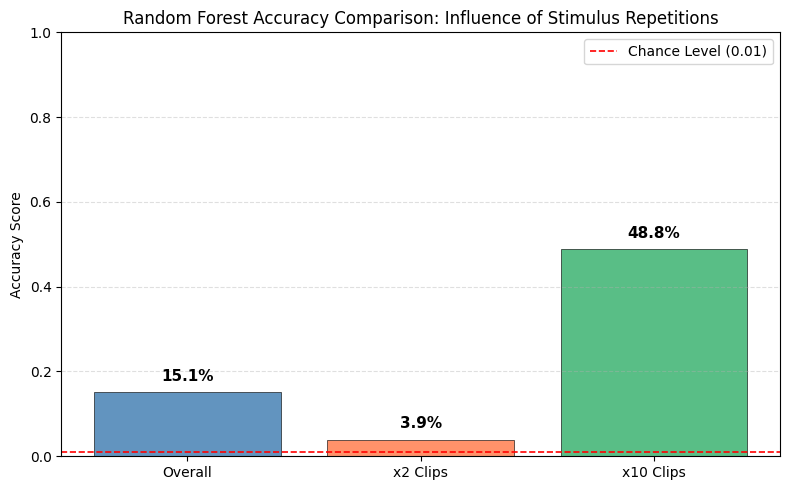

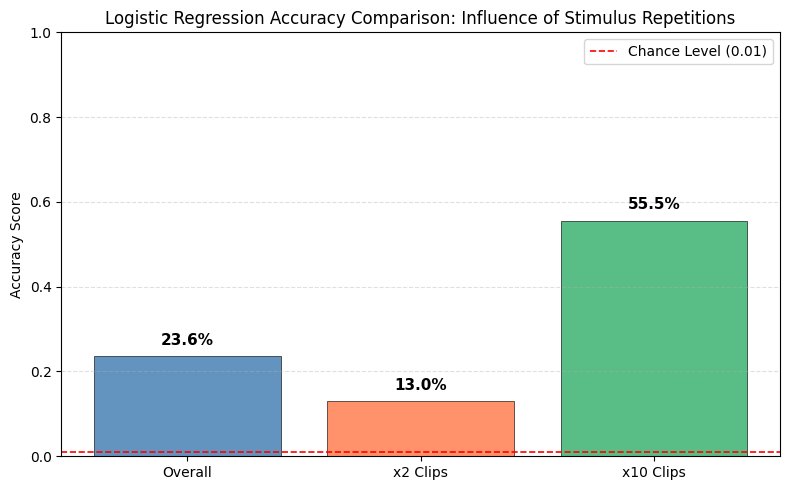

In [252]:
# ============================================================
# LOAD DATASET
# ============================================================
data = np.load("dataset_clip_optionB_V1.npz", allow_pickle=True)
X_train = np.nan_to_num(data['X_train'].astype(np.float64), nan=0.0, posinf=0.0, neginf=0.0)
X_test  = np.nan_to_num(data['X_test'].astype(np.float64),  nan=0.0, posinf=0.0, neginf=0.0)
y_train = data['y_train'].astype(np.int64)
y_test  = data['y_test'].astype(np.int64)
n_reps  = data['n_reps']

n_classes    = len(np.unique(y_train))
class_labels = [f"Clip_{i}" for i in range(n_classes)]
baseline     = 1.0 / n_classes
labels_x2    = [i for i, n in enumerate(n_reps) if n == 2]
labels_x10   = [i for i, n in enumerate(n_reps) if n == 10]
mask_x2      = np.isin(y_test, labels_x2)
mask_x10     = np.isin(y_test, labels_x10)

print(f"X_train: {X_train.shape} | X_test: {X_test.shape}")
print(f"Classes: {n_classes} | Baseline: {baseline:.4f} ({baseline*100:.2f}%)")

# ============================================================
# TRAIN CLASSIFIERS
# ============================================================
rf = RandomForestClassifier(n_estimators=200, max_depth=20, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)

lr = LogisticRegression(max_iter=2000, random_state=42, solver='lbfgs', C=0.1)
lr.fit(X_train, y_train)
y_pred_lr = lr.predict(X_test)

acc_rf    = accuracy_score(y_test, y_pred_rf)
f1_rf     = f1_score(y_test, y_pred_rf, average='weighted')
acc_rf_x2 = accuracy_score(y_test[mask_x2],  y_pred_rf[mask_x2])
acc_rf_x10= accuracy_score(y_test[mask_x10], y_pred_rf[mask_x10])

acc_lr    = accuracy_score(y_test, y_pred_lr)
f1_lr     = f1_score(y_test, y_pred_lr, average='weighted')
acc_lr_x2 = accuracy_score(y_test[mask_x2],  y_pred_lr[mask_x2])
acc_lr_x10= accuracy_score(y_test[mask_x10], y_pred_lr[mask_x10])

# ============================================================
# RESULTS
# ============================================================
print("\n" + "=" * 70)
print("RESULTS — V1 Clip Identity Decoding (all 5312 neurons)")
print("=" * 70)
print(f"RF: Acc={acc_rf:.4f}  F1={f1_rf:.4f}  Acc_x2={acc_rf_x2:.4f}  Acc_x10={acc_rf_x10:.4f}")
print(f"LR: Acc={acc_lr:.4f}  F1={f1_lr:.4f}  Acc_x2={acc_lr_x2:.4f}  Acc_x10={acc_lr_x10:.4f}")
print(f"Baseline (chance): {baseline:.4f} ({baseline*100:.2f}%)")

# ============================================================
# BAR CHART — RF: Overall / x2 / x10
# ============================================================
metrics_rf = ['Overall', 'x2 Clips', 'x10 Clips']
vals_rf    = [acc_rf, acc_rf_x2, acc_rf_x10]
colors     = ['steelblue', 'coral', 'mediumseagreen']

fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(metrics_rf, vals_rf, color=colors, alpha=0.85,
              edgecolor='black', linewidth=0.5)

ax.axhline(y=baseline, color='red', linestyle='--', linewidth=1.2,
           label=f'Chance Level ({baseline:.2f})')
ax.set_ylabel('Accuracy Score')
ax.set_title('Random Forest Accuracy Comparison: Influence of Stimulus Repetitions',
             fontsize=12)
ax.set_ylim(0, 1.0)
ax.legend()
ax.grid(axis='y', linestyle='--', alpha=0.4)

for bar, v in zip(bars, vals_rf):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.02,
            f'{v*100:.1f}%', ha='center', va='bottom',
            fontsize=11, fontweight='bold')

plt.tight_layout()
plt.savefig('comparison_V1_RF.png', dpi=150)
plt.show()


# ============================================================
# BAR CHART — LR: Overall / x2 / x10
# ============================================================
metrics_lr = ['Overall', 'x2 Clips', 'x10 Clips']
vals_lr    = [acc_lr, acc_lr_x2, acc_lr_x10]

fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(metrics_lr, vals_lr, color=colors, alpha=0.85,
              edgecolor='black', linewidth=0.5)

ax.axhline(y=baseline, color='red', linestyle='--', linewidth=1.2,
           label=f'Chance Level ({baseline:.2f})')
ax.set_ylabel('Accuracy Score')
ax.set_title('Logistic Regression Accuracy Comparison: Influence of Stimulus Repetitions',
             fontsize=12)
ax.set_ylim(0, 1.0)
ax.legend()
ax.grid(axis='y', linestyle='--', alpha=0.4)

for bar, v in zip(bars, vals_lr):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.02,
            f'{v*100:.1f}%', ha='center', va='bottom',
            fontsize=11, fontweight='bold')

plt.tight_layout()
plt.savefig('comparison_V1_LR.png', dpi=150)
plt.show()


The full V1 population decodes clip identity clearly above the **1.04% chance level**: **Logistic Regression reaches 0.2364 (F1 0.2304)** while **Random Forest reaches 0.1511 (F1 0.1100)**. Individual natural movie clips therefore evoke reproducible population activity patterns in V1. LR's roughly 1.5× advantage over RF suggests that clip-specific information is distributed across many neurons and is partly linearly separable. The much higher performance for ×10 clips (LR 0.5551, RF 0.4884) compared with ×2 clips (LR 0.1302, RF 0.0387) shows that repeated presentations provide a more stable estimate of the stimulus-evoked response, while ×2 clips are dominated by trial-to-trial variability.

**The confusion matrices** show that Logistic Regression produces a clearer diagonal than Random Forest, matching its higher accuracy and F1 score. This indicates that it identifies more clips correctly across the 96-class task. Off-diagonal errors suggest that some clips evoke similar population responses and are therefore confused by the decoder.



RANDOM SUBSAMPLING — 387 neurons × 30 iterations

V1 (5312 neurons → subsample to 387)
   RF: Acc=0.1276 ± 0.0096  F1=0.0949 ± 0.0079  Acc_x2=0.0312 ± 0.0066  Acc_x10=0.4168 ± 0.0257
   LR: Acc=0.1313 ± 0.0043  F1=0.1245 ± 0.0045  Acc_x2=0.0540 ± 0.0042  Acc_x10=0.3631 ± 0.0127

LM (983 neurons → subsample to 387)
   RF: Acc=0.1616 ± 0.0052  F1=0.1179 ± 0.0056  Acc_x2=0.0457 ± 0.0056  Acc_x10=0.5094 ± 0.0157
   LR: Acc=0.1445 ± 0.0035  F1=0.1377 ± 0.0033  Acc_x2=0.0648 ± 0.0035  Acc_x10=0.3836 ± 0.0097

AL (387 neurons → subsample to all 387)
   RF: Acc=0.1101 ± 0.0000  F1=0.0866 ± 0.0000  Acc_x2=0.0326 ± 0.0000  Acc_x10=0.3427 ± 0.0000
   LR: Acc=0.1232 ± 0.0000  F1=0.1155 ± 0.0000  Acc_x2=0.0553 ± 0.0000  Acc_x10=0.3271 ± 0.0000

RL (811 neurons → subsample to 387)
   RF: Acc=0.1184 ± 0.0050  F1=0.0913 ± 0.0053  Acc_x2=0.0368 ± 0.0055  Acc_x10=0.3631 ± 0.0177
   LR: Acc=0.1174 ± 0.0045  F1=0.1130 ± 0.0042  Acc_x2=0.0534 ± 0.0037  Acc_x10=0.3094 ± 0.0122

Baseline (chance): 0.0104 (1

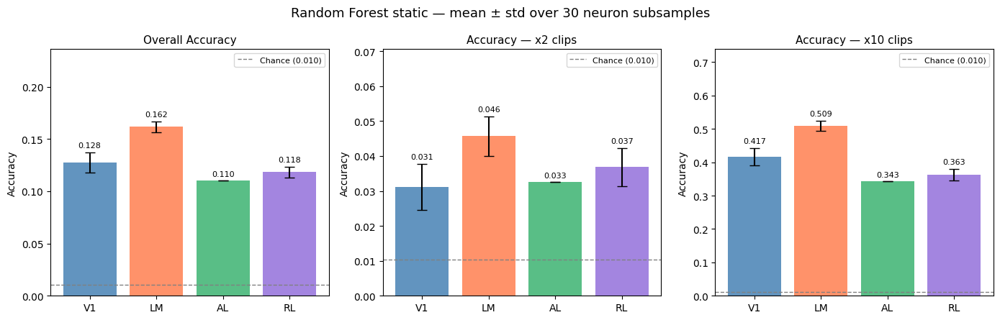

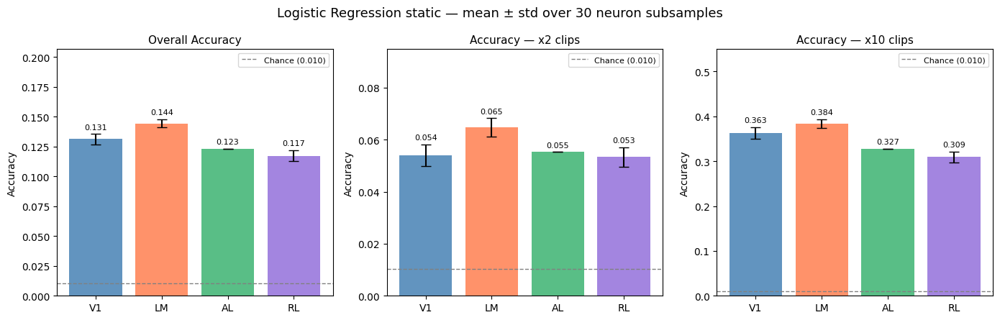

In [253]:
AREAS     = ["V1", "LM", "AL", "RL"]
N_NEURONS = 387
N_ITER    = 30
SEED_BASE = 42

all_results = {area: {'RF': {'acc': [], 'f1': [], 'acc_x2': [], 'acc_x10': []},
                       'LR': {'acc': [], 'f1': [], 'acc_x2': [], 'acc_x10': []},
                       'n_neurons': None}
               for area in AREAS}

# Accumulate importance per original neuron across all 30 iterations
clip_rf_importance_accum = {}
clip_lr_importance_accum = {}
clip_subsample_counts    = {}

for area in AREAS:
    data      = np.load(f"dataset_clip_optionB_{area}.npz", allow_pickle=True)
    X_train   = np.nan_to_num(data['X_train'].astype(np.float64), nan=0.0, posinf=0.0, neginf=0.0)
    X_test    = np.nan_to_num(data['X_test'].astype(np.float64),  nan=0.0, posinf=0.0, neginf=0.0)
    y_train   = data['y_train'].astype(np.int64)
    y_test    = data['y_test'].astype(np.int64)
    n_reps    = data['n_reps']
    n_neurons = X_train.shape[1]
    all_results[area]['n_neurons'] = n_neurons

    labels_x2  = [i for i, n in enumerate(n_reps) if n == 2]
    labels_x10 = [i for i, n in enumerate(n_reps) if n == 10]
    mask_x2    = np.isin(y_test, labels_x2)
    mask_x10   = np.isin(y_test, labels_x10)

    rf_imp_sum = np.zeros(n_neurons)
    lr_imp_sum = np.zeros(n_neurons)
    count_seen = np.zeros(n_neurons, dtype=int)

    for i in range(N_ITER):
        rng = np.random.default_rng(SEED_BASE + i)
        idx = np.arange(n_neurons) if area == "AL" else rng.choice(n_neurons, size=N_NEURONS, replace=False)
        X_tr, X_te = X_train[:, idx], X_test[:, idx]

        # ── Random Forest ──────────────────────────────────────
        rf_sub = RandomForestClassifier(n_estimators=100, max_depth=20, random_state=42, n_jobs=-1)
        rf_sub.fit(X_tr, y_train)
        y_pred_rf = rf_sub.predict(X_te)
        all_results[area]['RF']['acc'].append(accuracy_score(y_test, y_pred_rf))
        all_results[area]['RF']['f1'].append(f1_score(y_test, y_pred_rf, average='weighted'))
        all_results[area]['RF']['acc_x2'].append(accuracy_score(y_test[mask_x2],  y_pred_rf[mask_x2]))
        all_results[area]['RF']['acc_x10'].append(accuracy_score(y_test[mask_x10], y_pred_rf[mask_x10]))
        rf_imp_sum[idx] += rf_sub.feature_importances_

        # ── Logistic Regression ────────────────────────────────
        lr_sub = LogisticRegression(max_iter=1000, random_state=42, solver='lbfgs', C=0.1)
        lr_sub.fit(X_tr, y_train)
        y_pred_lr = lr_sub.predict(X_te)
        all_results[area]['LR']['acc'].append(accuracy_score(y_test, y_pred_lr))
        all_results[area]['LR']['f1'].append(f1_score(y_test, y_pred_lr, average='weighted'))
        all_results[area]['LR']['acc_x2'].append(accuracy_score(y_test[mask_x2],  y_pred_lr[mask_x2]))
        all_results[area]['LR']['acc_x10'].append(accuracy_score(y_test[mask_x10], y_pred_lr[mask_x10]))
        lr_imp_sum[idx] += np.linalg.norm(lr_sub.coef_, axis=0)

        count_seen[idx] += 1

    count_safe = np.where(count_seen > 0, count_seen, 1)
    clip_rf_importance_accum[area] = rf_imp_sum / count_safe
    clip_lr_importance_accum[area] = lr_imp_sum / count_safe
    clip_subsample_counts[area]    = count_seen

# ============================================================
# RESULTS
# ============================================================
baseline = 1 / 96
print("\n" + "=" * 65)
print(f"RANDOM SUBSAMPLING — {N_NEURONS} neurons × {N_ITER} iterations")
print("=" * 65)
for area in AREAS:
    n     = all_results[area]['n_neurons']
    label = f"all {N_NEURONS}" if area == "AL" else str(N_NEURONS)
    print(f"\n{area} ({n} neurons → subsample to {label})")
    for clf in ['RF', 'LR']:
        r = all_results[area][clf]
        print(f"   {clf}: Acc={np.mean(r['acc']):.4f} ± {np.std(r['acc']):.4f}  "
              f"F1={np.mean(r['f1']):.4f} ± {np.std(r['f1']):.4f}  "
              f"Acc_x2={np.mean(r['acc_x2']):.4f} ± {np.std(r['acc_x2']):.4f}  "
              f"Acc_x10={np.mean(r['acc_x10']):.4f} ± {np.std(r['acc_x10']):.4f}")
print(f"\nBaseline (chance): {baseline:.4f} ({baseline*100:.2f}%)")

# ============================================================
# BAR CHART — RF (1x3: Overall / x2 / x10)
# ============================================================
metrics_to_plot = [
    ('acc',     'Overall Accuracy'),
    ('acc_x2',  'Accuracy — x2 clips'),
    ('acc_x10', 'Accuracy — x10 clips'),
]
colors = ["steelblue", "coral", "mediumseagreen", "mediumpurple"]

fig, axes = plt.subplots(1, 3, figsize=(14, 4.5))
fig.suptitle("Random Forest static — mean ± std over 30 neuron subsamples", fontsize=13)

for ax, (key, title) in zip(axes, metrics_to_plot):
    means = [np.mean(all_results[a]['RF'][key]) for a in AREAS]
    stds  = [np.std(all_results[a]['RF'][key])  for a in AREAS]
    bars  = ax.bar(AREAS, means, yerr=stds, capsize=5,
                   color=colors, alpha=0.85,
                   error_kw={"linewidth": 1.5})
    ax.axhline(baseline, color="gray", linestyle="--", linewidth=1, label=f"Chance ({baseline:.3f})")
    ax.set_title(title, fontsize=11)
    ax.set_ylabel("Accuracy")
    ax.set_ylim(0, max(means) * 1.4 + max(stds))
    ax.legend(fontsize=8, loc="upper right")
    for bar, m, s in zip(bars, means, stds):
        ax.text(bar.get_x() + bar.get_width() / 2,
                bar.get_height() + s + (max(means) * 0.02),
                f"{m:.3f}", ha="center", va="bottom", fontsize=8)

plt.tight_layout()
plt.savefig("subsampling_clip_RF.png", dpi=150, bbox_inches="tight")
plt.show()

# ============================================================
# BAR CHART — LR (1x3: Overall / x2 / x10)
# ============================================================
fig, axes = plt.subplots(1, 3, figsize=(14, 4.5))
fig.suptitle("Logistic Regression static — mean ± std over 30 neuron subsamples", fontsize=13)

for ax, (key, title) in zip(axes, metrics_to_plot):
    means = [np.mean(all_results[a]['LR'][key]) for a in AREAS]
    stds  = [np.std(all_results[a]['LR'][key])  for a in AREAS]
    bars  = ax.bar(AREAS, means, yerr=stds, capsize=5,
                   color=colors, alpha=0.85,
                   error_kw={"linewidth": 1.5})
    ax.axhline(baseline, color="gray", linestyle="--", linewidth=1, label=f"Chance ({baseline:.3f})")
    ax.set_title(title, fontsize=11)
    ax.set_ylabel("Accuracy")
    ax.set_ylim(0, max(means) * 1.4 + max(stds))
    ax.legend(fontsize=8, loc="upper right")
    for bar, m, s in zip(bars, means, stds):
        ax.text(bar.get_x() + bar.get_width() / 2,
                bar.get_height() + s + (max(means) * 0.02),
                f"{m:.3f}", ha="center", va="bottom", fontsize=8)

plt.tight_layout()
plt.savefig("subsampling_clip_LR.png", dpi=150, bbox_inches="tight")
plt.show()

### Results

**All areas decode clip identity well above chance**, confirming that individual clip representations are stable and reproducible across independent presentations throughout the visual hierarchy. Even the weakest area-classifier combination — AL with RF (0.1101) — sits at ≈10× the 1.04% baseline. This demonstrates that the population code for each specific clip is a reliable, repeatable neural signature rather than a transient or noisy event.

**For the full V1 population, LR substantially outperforms RF** (0.2364 vs 0.1511), a reversal relative to the matched-neuron setting where the gap between the two classifiers is much smaller. Two factors explain this: (i) Part 1.2 uses all timepoints from multiple repetitions, producing many more training samples per class than Part 1.1, and (ii) the full-V1 dimensionality (5312 neurons) gives LR enough features to recover a linear decision boundary, which RF cannot exploit as efficiently.

**With 387 neurons, the cross-area ranking is led by LM** for both classifiers. For RF: LM (0.1616) > V1 (0.1276) > RL (0.1184) > AL (0.1101). For LR: LM (0.1445) > V1 (0.1313) > AL (0.1232) > RL (0.1174). LM consistently outperforms V1 when neuron counts are equalized — a pattern consistent with the idea that LM encodes more complex, intermediate-level features (texture composition, motion patterns, global structure) that are more uniquely tied to the identity of a specific clip, whereas V1 encodes low-level spatiotemporal features that may be shared across many clips.

**The gap between Acc_x2 and Acc_x10 is the most neuroscientifically informative finding.** Across all areas and classifiers, clips with 5 training repetitions are decoded 5–13× more accurately than clips with just 1 repetition (e.g. V1 RF: x10 = 0.4168 vs x2 = 0.0312). This enormous difference directly quantifies the **trial-to-trial variability of neural population responses**: a single presentation of a clip does not produce a sufficiently stable population template for the classifier to generalize from. Multiple independent presentations are required to average out neural noise and isolate the reliable, clip-specific component of the response. This result is consistent with the known high variability of single-trial responses in visual cortex and underscores the importance of repetition for building stable representations — both for a classifier and, potentially, for the brain itself.

**The variance across subsampling iterations is low and consistent across areas** (std ≈ 0.005–0.010 for overall accuracy), indicating that clip identity information is broadly distributed across the neural population rather than concentrated in a small informative subpopulation. The slightly higher variance in V1 under RF compared to LM may reflect a modestly sparser organization of clip-discriminating responses in primary cortex.


# Part 2: Temporal Analysis

The temporal analysis pipeline asks a single question: can the **spatiotemporal pattern** of population activity in mouse visual cortex be used to decode what the animal is watching, and does this capacity differ across visual areas?

---

### Rationale

Neural responses are arranged into **non-overlapping sliding windows of 10 consecutive timepoints** (≈ 1 s of population activity). Each window is treated as one sample of shape *(timepoints × neurons)*, and the task is to predict either the stimulus category or the exact clip from this short snapshot of population dynamics. A trial of 70 frames therefore produces 7 windows, each carrying the dynamics of a 10-frame sub-segment.

---

### Two Tasks, Mirrored on Part 1

- **Section 2.1 — Stimulus Type Classification** (3 classes; chance 33.3%) — temporal counterpart of Part 1.1.
- **Section 2.2 — Specific Clip Identification** (96 classes; chance 1.04%) — temporal counterpart of Part 1.2.

---

### Train/Test Split — By Repetition

Identical to Part 1.2: clips shown twice contribute repetition 1 to train and repetition 2 to test; clips shown ten times contribute repetitions 1–5 to train and 6–10 to test. No timepoint from a test repetition ever appears in training.

---

### Two-Step Structure for Each Task

- **Subsections 2.1.1 / 2.2.1 — Full V1 population.** A GRU is trained on **all 5312 V1 neurons** to establish an upper-bound reference, mirroring the *V1 — Full Population* analyses of Part 1.
- **Subsections 2.1.2 / 2.2.2 — Cross-area comparison.** The four areas (V1, LM, AL, RL) are compared on a fair footing by subsampling each to **N = 387 neurons** (matching AL, the smallest area) and **repeating the procedure 30 times** with independent neuron seeds, exactly as in Part 1's random subsampling design. Each area therefore produces 30 trained models — 120 in total per task. AL has only 387 neurons, so its 30 "subsamples" are identical and the seed-to-seed variability for AL comes entirely from training stochasticity (random weight initialization and batch shuffling).

---

### Model

A **GRU-based recurrent network** with a linear projection layer that compresses the population vector at each timepoint into a lower-dimensional space before the GRU processes the temporal sequence. The final hidden state feeds a linear classifier.

---

### Interpretability

After training, **gradient-based saliency** identifies which neurons and which timepoints inside the window are most informative:
- The **cumulative saliency curve** indicates whether information is concentrated in a small number of neurons or spread across the population.
- The **temporal importance profile** indicates whether discrimination happens early in the window — consistent with a fast feedforward response — or late, consistent with recurrent or feedback processing.

These analyses are run per area and averaged across seeds.

## Part 2.1: Stimulus Type Classification with Temporal Windows

### 2.1.1: Model Trained on all V1 neurons

### Rationale and Experimental Design

This subsection trains a **GRU on all 5312 V1 neurons** to decode broad stimulus type (Clip / Monet2 / Trippy) from short temporal windows of population activity. The structure of the analysis mirrors Part 1.1 (full V1 population, 3-class task, chance 33.3%) and establishes an upper-bound reference for how much category information is carried by V1 dynamics, before the cross-area comparison of 2.1.2.

The pipeline runs in three steps:
1. **Dataset construction** — sliding-window extraction with clip-level train/test split.
2. **GRU training** — temporal classifier with early stopping.
3. **Interpretability** — gradient-based saliency for neuron and timepoint importance.

#### Temporal dataset construction — V1 stimulus-type GRU

### Stimulus Selection — Clips with at Least 2 Repetitions

Only stimuli with at least 2 repetitions are kept, so that train and test windows can come from **different presentations of the same clip**. From the deduplication of Part 1.1: Monet2 has 20 unique clips, Trippy 20, Clip 240; we randomly sample 20 unique Clip stimuli to match the other two categories.

---

### Train/Test Split — At the Clip Level

Split ratio: **80/20** at the unique-clip level (16 train / 4 test per category, separately per class). The split is performed before window extraction so that no clip appears in both sets.

---

### Sliding-Window Extraction

Each repetition is sliced into **non-overlapping windows**:
- **window size = 10 timepoints**
- **step size = 10 timepoints**

Training windows come from **repetition 0**, test windows from **repetition 1**, so the model must generalize across independent presentations.

---

### Final Dataset

After NaN cleaning and train-only standardization:
- **X_train:** `(464, 10, 5312)`
- **X_test:** `(116, 10, 5312)`

The training set is mildly imbalanced toward Monet2 / Trippy:
- **Clip:** 112 windows (24.1%)
- **Monet2:** 176 windows (37.9%)
- **Trippy:** 176 windows (37.9%)

The processed dataset is saved as `dataset_temporal.npz`.

In [254]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler

# ============================================================
# SETUP
# ============================================================
N_TRIALS    = 20
WINDOW_SIZE = 10      
STEP_SIZE   = 10       
TEST_SIZE   = 0.2
AREA        = "V1"
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

# ============================================================
# STEP 1 — Select unique clips with at least 2 repetitions
# ============================================================
from collections import Counter

# Count repetitions for each category
monet_counts  = Counter(monet_hashes)
trippy_counts = Counter(trippy_hashes)
clip_counts   = Counter(clip_hashes)

# Keep only clips that appear at least twice
unique_monet  = [h for h, c in monet_counts.items()  if c >= 2]
unique_trippy = [h for h, c in trippy_counts.items() if c >= 2]
unique_clip   = [h for h, c in clip_counts.items()   if c >= 2]

# Sample N_TRIALS from valid clips only
unique_clip = list(np.random.choice(unique_clip, 
                   min(N_TRIALS, len(unique_clip)), 
                   replace=False))

print(f"Valid unique clips (>=2 reps):")
print(f"   Monet2: {len(unique_monet)}")
print(f"   Clip:   {len(unique_clip)}")
print(f"   Trippy: {len(unique_trippy)}")

# ============================================================
# STEP 2 — Split at the unique clip level
# ============================================================
monet_train,  monet_test  = train_test_split(unique_monet,  test_size=TEST_SIZE, random_state=RANDOM_SEED)
clip_train,   clip_test   = train_test_split(unique_clip,   test_size=TEST_SIZE, random_state=RANDOM_SEED)
trippy_train, trippy_test = train_test_split(unique_trippy, test_size=TEST_SIZE, random_state=RANDOM_SEED)

# ============================================================
# STEP 3 — Extraction with explicit repetition index
# ============================================================
def extract_windows(funcreader, hash_val, rep_idx, area, window_size, step_size):
    r = funcreader.get_responses_by_hash(hash_val, area)[rep_idx]  # ← rep_idx
    responses = r["responses"].T  # (n_timepoints, n_neurons)

    windows = []
    for start in range(0, responses.shape[0] - window_size + 1, step_size):
        windows.append(responses[start:start + window_size, :])
    return np.stack(windows)


def build_windowed_split(funcreader, hash_dict, rep_idx, area, window_size, step_size):
    X_list, y_list = [], []
    for label, hashes in hash_dict.items():
        for h in hashes:
            windows = extract_windows(funcreader, h, rep_idx, area, window_size, step_size)
            X_list.append(windows)
            y_list.extend([label] * windows.shape[0])
    return np.vstack(X_list), np.array(y_list)

# ============================================================
# STEP 4 — Build X_train (rep 0) and X_test (rep 1)
# ============================================================
X_train_raw, y_train_raw = build_windowed_split(funcreader, {
    "Monet2": monet_train,
    "Clip":   clip_train,
    "Trippy": trippy_train
}, rep_idx=0, area=AREA, window_size=WINDOW_SIZE, step_size=STEP_SIZE)  # ← rep 0

X_test_raw, y_test_raw = build_windowed_split(funcreader, {
    "Monet2": monet_test,
    "Clip":   clip_test,
    "Trippy": trippy_test
}, rep_idx=1, area=AREA, window_size=WINDOW_SIZE, step_size=STEP_SIZE)  # ← rep 1

# ============================================================
# STEP 5 — Label encoding
# ============================================================
le = LabelEncoder()
le.fit(y_train_raw)
y_train = le.transform(y_train_raw).astype(np.int64)
y_test  = le.transform(y_test_raw).astype(np.int64)

# ============================================================
# STEP 6 — Data cleaning
# ============================================================
X_train_raw = X_train_raw.astype(np.float64)
X_test_raw  = X_test_raw.astype(np.float64)
X_train_raw = np.nan_to_num(X_train_raw, nan=0.0, posinf=0.0, neginf=0.0)
X_test_raw  = np.nan_to_num(X_test_raw,  nan=0.0, posinf=0.0, neginf=0.0)

# ============================================================
# STEP 7 — Normalization
# Flatten to 2D to fit scaler, then reshape back to 3D
# ============================================================
n_train, T, n_neurons = X_train_raw.shape
n_test                = X_test_raw.shape[0]

scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train_raw.reshape(-1, n_neurons)).reshape(n_train, T, n_neurons)
X_test_sc  = scaler.transform(X_test_raw.reshape(-1, n_neurons)).reshape(n_test,  T, n_neurons)

# ============================================================
# STEP 8 — Sanity check
# ============================================================
print("\n" + "=" * 60)
print("WINDOWED DATASET")
print("=" * 60)
print(f"X_train: {X_train_sc.shape}   → (n_windows, window_size, n_neurons)")
print(f"X_test:  {X_test_sc.shape}")
print(f"Classes: {le.classes_}")

unique, counts = np.unique(y_train, return_counts=True)
print("\nTrain distribution:")
for cls_int, count in zip(unique, counts):
    print(f"   {le.classes_[cls_int]}: {count} windows ({count/len(y_train)*100:.1f}%)")

# ============================================================
# STEP 9 — Save
# ============================================================
np.savez("dataset_temporal.npz",
         X_train=X_train_sc, X_test=X_test_sc,
         y_train=y_train,    y_test=y_test,
         classes=le.classes_)

print("\nDataset saved in 'dataset_temporal.npz'")
print(f"   Window size: {WINDOW_SIZE} timepoints")
print(f"   Step size:   {STEP_SIZE} timepoints")

Valid unique clips (>=2 reps):
   Monet2: 20
   Clip:   20
   Trippy: 20

WINDOWED DATASET
X_train: (464, 10, 5312)   → (n_windows, window_size, n_neurons)
X_test:  (116, 10, 5312)
Classes: ['Clip' 'Monet2' 'Trippy']

Train distribution:
   Clip: 112 windows (24.1%)
   Monet2: 176 windows (37.9%)
   Trippy: 176 windows (37.9%)

Dataset saved in 'dataset_temporal.npz'
   Window size: 10 timepoints
   Step size:   10 timepoints


#### GRU training — V1 stimulus-type classifier

### Model

- **Linear projection** 5312 → 64 (compresses the population vector at each timepoint).
- **GRU** with hidden dim 64, 1 layer, dropout 0.3.
- **Linear classifier** on the final hidden state → 3 classes.
- **Total parameters:** 365,187.
- Training on **MPS** with Adam, learning-rate scheduler and early stopping (patience 15).

The **chance-level baseline** for the balanced 3-class problem is **33.3%**.

DATASET
X_train: (464, 10, 5312)   (n_windows, window_size, n_neurons)
X_test:  (116, 10, 5312)
Classes: ['Clip' 'Monet2' 'Trippy']

Using device: mps

Model parameters: 365,187

TRAINING
Epoch  10/100 | Train Loss: 0.0042  Acc: 1.0000 | Val Loss: 0.3336  Acc: 0.8966
Epoch  20/100 | Train Loss: 0.0027  Acc: 1.0000 | Val Loss: 0.3448  Acc: 0.9052

Early stopping at epoch 20 (no improvement for 15 epochs)

Best model restored (val loss: 0.3011)

FINAL RESULTS — GRU
Accuracy:             0.9052 (90.52%)
F1-Score (weighted):  0.9051
Random baseline:      0.3333 (33.33%)

Classification Report:
              precision    recall  f1-score   support

        Clip       0.78      0.89      0.83        28
      Monet2       0.96      1.00      0.98        44
      Trippy       0.95      0.82      0.88        44

    accuracy                           0.91       116
   macro avg       0.90      0.90      0.90       116
weighted avg       0.91      0.91      0.91       116



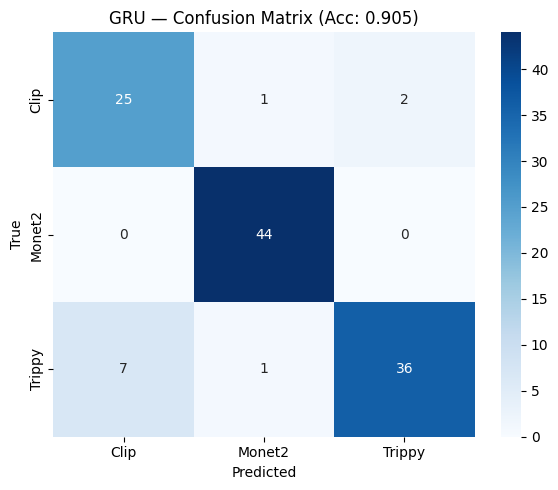

In [255]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# ============================================================
# Reproducibility seeding (PyTorch + NumPy)
# ============================================================
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)
if torch.backends.mps.is_available():
    torch.mps.manual_seed(RANDOM_SEED)


# ============================================================
# STEP 1 — Load dataset
# ============================================================
data    = np.load("dataset_temporal.npz", allow_pickle=True)
X_train = data['X_train'].astype(np.float32)
X_test  = data['X_test'].astype(np.float32)
y_train = data['y_train'].astype(np.int64)
y_test  = data['y_test'].astype(np.int64)
classes = data['classes']

n_classes = len(classes)
n_neurons = X_train.shape[2]

print("=" * 60)
print("DATASET")
print("=" * 60)
print(f"X_train: {X_train.shape}   (n_windows, window_size, n_neurons)")
print(f"X_test:  {X_test.shape}")
print(f"Classes: {classes}")

# ============================================================
# STEP 2 — Convert to PyTorch tensors and DataLoaders
# ============================================================
X_train_t = torch.tensor(X_train)
y_train_t = torch.tensor(y_train)
X_test_t  = torch.tensor(X_test)
y_test_t  = torch.tensor(y_test)

train_dataset = TensorDataset(X_train_t, y_train_t)
test_dataset  = TensorDataset(X_test_t,  y_test_t)

train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
test_loader  = DataLoader(test_dataset,  batch_size=64, shuffle=False)

# ============================================================
# STEP 3 — GRU Model definition
# ============================================================
class NeuralGRU(nn.Module):
    """
    Architecture:
        Linear projection: n_neurons (5000) → proj_dim (256)
            ↓
        GRU: proj_dim → hidden_dim, n_layers
            ↓
        Take last hidden state
            ↓
        Dropout
            ↓
        Linear classifier → n_classes (3)

    The projection layer is critical: feeding 5000 raw features
    directly into the GRU would be extremely slow and overfit badly
    given the small number of trials. The projection compresses the
    population vector into a dense, lower-dimensional representation
    before the GRU processes the temporal sequence.
    """
    def __init__(self, n_neurons, proj_dim, hidden_dim, n_layers, n_classes, dropout=0.3):
        super().__init__()

        self.projection = nn.Linear(n_neurons, proj_dim)

        self.gru = nn.GRU(
            input_size=proj_dim,
            hidden_size=hidden_dim,
            num_layers=n_layers,
            batch_first=True,       # input shape: (batch, time, features)
            dropout=dropout if n_layers > 1 else 0.0
        )

        self.dropout    = nn.Dropout(dropout)
        self.classifier = nn.Linear(hidden_dim, n_classes)

    def forward(self, x):
        # x shape: (batch, window_size, n_neurons)

        # Project each timepoint independently
        x = self.projection(x)          # (batch, window_size, proj_dim)

        # GRU processes the full sequence
        _, h_n = self.gru(x)            # h_n: (n_layers, batch, hidden_dim)

        # Take the last layer's hidden state as the sequence summary
        out = h_n[-1]                   # (batch, hidden_dim)

        out = self.dropout(out)
        out = self.classifier(out)      # (batch, n_classes)
        return out

# ============================================================
# STEP 4 — Instantiate model, loss, optimizer
# ============================================================
device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")
print(f"\nUsing device: {device}")

model = NeuralGRU(
    n_neurons  = n_neurons,
    proj_dim   = 64,
    hidden_dim = 64,
    n_layers   = 1,
    n_classes  = n_classes,
    dropout    = 0.3
).to(device)

print(f"\nModel parameters: {sum(p.numel() for p in model.parameters()):,}")

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-4)

# Learning rate scheduler — reduces LR if validation loss plateaus
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode='min', patience=5, factor=0.5
)

# ============================================================
# STEP 5 — Training loop with early stopping
# ============================================================
N_EPOCHS       = 100
PATIENCE       = 15     # stop if val loss doesn't improve for 15 epochs

train_losses, val_losses     = [], []
train_accs,   val_accs       = [], []
best_val_loss                = float('inf')
epochs_without_improvement   = 0
best_model_state             = None

print("\n" + "=" * 60)
print("TRAINING")
print("=" * 60)

for epoch in range(N_EPOCHS):

    # --- Training phase ---
    model.train()
    epoch_loss, correct, total = 0.0, 0, 0

    for X_batch, y_batch in train_loader:
        X_batch, y_batch = X_batch.to(device), y_batch.to(device)

        optimizer.zero_grad()
        logits = model(X_batch)
        loss   = criterion(logits, y_batch)
        loss.backward()
        optimizer.step()

        epoch_loss += loss.item() * X_batch.size(0)
        preds       = logits.argmax(dim=1)
        correct    += (preds == y_batch).sum().item()
        total      += X_batch.size(0)

    train_loss = epoch_loss / total
    train_acc  = correct / total

    # --- Validation phase ---
    model.eval()
    val_loss, val_correct, val_total = 0.0, 0, 0

    with torch.no_grad():
        for X_batch, y_batch in test_loader:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)
            logits    = model(X_batch)
            loss      = criterion(logits, y_batch)
            val_loss += loss.item() * X_batch.size(0)
            preds     = logits.argmax(dim=1)
            val_correct += (preds == y_batch).sum().item()
            val_total   += X_batch.size(0)

    val_loss = val_loss / val_total
    val_acc  = val_correct / val_total

    train_losses.append(train_loss)
    val_losses.append(val_loss)
    train_accs.append(train_acc)
    val_accs.append(val_acc)

    scheduler.step(val_loss)

    # --- Early stopping ---
    if val_loss < best_val_loss:
        best_val_loss      = val_loss
        best_model_state   = model.state_dict().copy()
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1

    if (epoch + 1) % 10 == 0:
        print(f"Epoch {epoch+1:3d}/{N_EPOCHS} | "
              f"Train Loss: {train_loss:.4f}  Acc: {train_acc:.4f} | "
              f"Val Loss: {val_loss:.4f}  Acc: {val_acc:.4f}")

    if epochs_without_improvement >= PATIENCE:
        print(f"\nEarly stopping at epoch {epoch+1} "
              f"(no improvement for {PATIENCE} epochs)")
        break

# Restore best model weights
model.load_state_dict(best_model_state)
print(f"\nBest model restored (val loss: {best_val_loss:.4f})")

# ============================================================
# STEP 6 — Final evaluation
# ============================================================
model.eval()
all_preds, all_labels = [], []

with torch.no_grad():
    for X_batch, y_batch in test_loader:
        X_batch = X_batch.to(device)
        preds   = model(X_batch).argmax(dim=1).cpu().numpy()
        all_preds.extend(preds)
        all_labels.extend(y_batch.numpy())

all_preds  = np.array(all_preds)
all_labels = np.array(all_labels)

acc_gru = accuracy_score(all_labels, all_preds)
f1_gru  = f1_score(all_labels, all_preds, average='weighted')

print("\n" + "=" * 60)
print("FINAL RESULTS — GRU")
print("=" * 60)
print(f"Accuracy:             {acc_gru:.4f} ({acc_gru*100:.2f}%)")
print(f"F1-Score (weighted):  {f1_gru:.4f}")
print(f"Random baseline:      {1/n_classes:.4f} ({100/n_classes:.2f}%)")
print(f"\nClassification Report:")
print(classification_report(all_labels, all_preds, target_names=classes))

# ============================================================
# STEP 7 — Plots
# ============================================================
# Confusion matrix
cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=classes, yticklabels=classes)
plt.title(f'GRU — Confusion Matrix (Acc: {acc_gru:.3f})')
plt.xlabel('Predicted')
plt.ylabel('True')
plt.tight_layout()
plt.savefig('gru_confusion_matrix.png', dpi=150)
plt.show()

# ============================================================
# STEP 8 — Save model and results
# ============================================================
torch.save(best_model_state, 'gru_best_model.pt')

   Gradient shape: (116, 10, 5312)


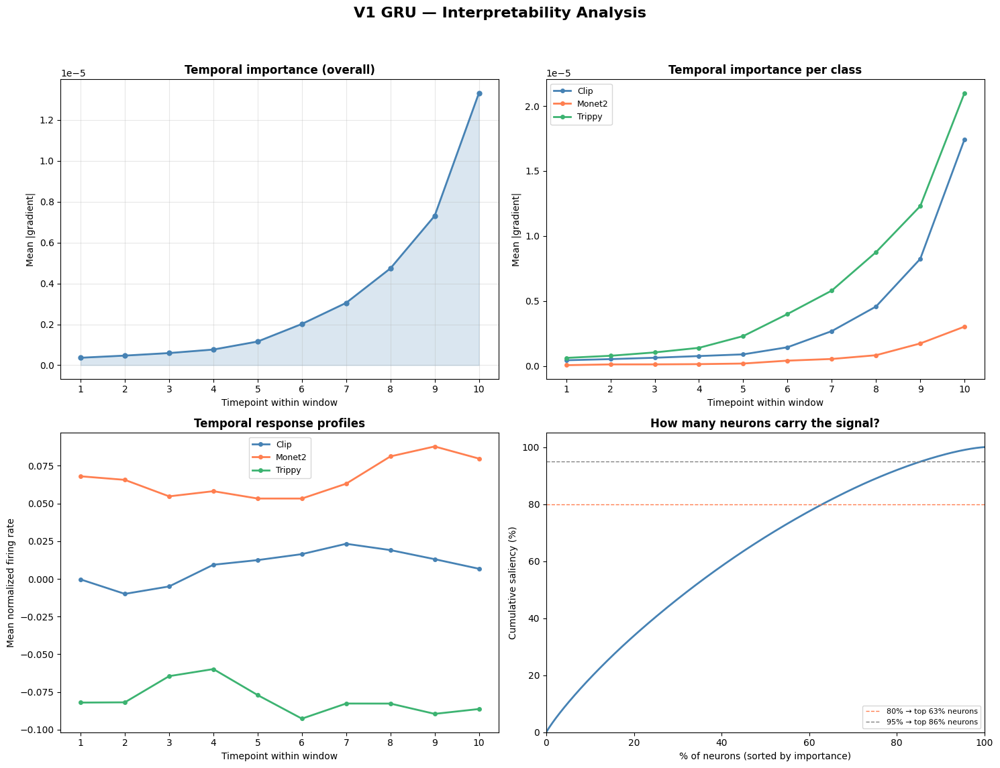


NEUROSCIENCE SUMMARY

Neuron saliency concentration:
   80% of signal in top 63.0% of neurons
   95% of signal in top 85.6% of neurons
   → DISTRIBUTED — information spread across population

Temporal coding:
   Peak discriminative timepoint: t=10/10
   → Late window — consistent with feedback/recurrent processing

Per-class recall:
   Clip: 0.893
   Monet2: 1.000
   Trippy: 0.818


In [256]:
import torch
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.metrics import confusion_matrix

# ============================================================
# SETUP
# ============================================================
classes_list = list(classes)
n_classes    = len(classes_list)
colors       = ["steelblue", "coral", "mediumseagreen"]

# ============================================================
# ANALYSIS 1 & 2 — Neuron + temporal saliency
# ============================================================

model.train()

X_sal = torch.tensor(X_test_sc.astype(np.float32)).to(device)
X_sal.requires_grad_(True)
y_sal = torch.tensor(y_test).to(device)

logits = model(X_sal)
loss   = torch.nn.CrossEntropyLoss()(logits, y_sal)
loss.backward()

assert X_sal.grad is not None, "Gradient is None — check model architecture"
grads = X_sal.grad.detach().cpu().numpy()

model.eval()

# (n_samples, n_neurons) — averaged over time
neuron_saliency_per_sample = np.abs(grads).mean(axis=1)
neuron_importance           = neuron_saliency_per_sample.mean(axis=0)

neuron_importance_per_class = {}
for cls_idx, cls_name in enumerate(classes_list):
    mask = y_test == cls_idx
    neuron_importance_per_class[cls_name] = \
        neuron_saliency_per_sample[mask].mean(axis=0)

# (n_samples, window_size) — averaged over neurons
temporal_saliency_per_sample  = np.abs(grads).mean(axis=2)
temporal_importance            = temporal_saliency_per_sample.mean(axis=0)

temporal_importance_per_class = {}
for cls_idx, cls_name in enumerate(classes_list):
    mask = y_test == cls_idx
    temporal_importance_per_class[cls_name] = \
        temporal_saliency_per_sample[mask].mean(axis=0)

print(f"   Gradient shape: {grads.shape}")


# ============================================================
# ANALYSIS 4 — Temporal response profiles
# ============================================================

timepoints = np.arange(1, X_test_sc.shape[1] + 1)

temporal_profiles = {}
for cls_idx, cls_name in enumerate(classes_list):
    mask = y_test == cls_idx
    temporal_profiles[cls_name] = X_test_sc[mask].mean(axis=0).mean(axis=1)

# ============================================================
# ANALYSIS 5 — Predictions for confusion matrix
# ============================================================
all_preds, all_labels = [], []
X_test_t = torch.tensor(X_test_sc.astype(np.float32))
y_test_t = torch.tensor(y_test)
loader   = torch.utils.data.DataLoader(
    torch.utils.data.TensorDataset(X_test_t, y_test_t),
    batch_size=64, shuffle=False
)
with torch.no_grad():
    for Xb, yb in loader:
        all_preds.extend(model(Xb.to(device)).argmax(1).cpu().numpy())
        all_labels.extend(yb.numpy())

# ============================================================
# PLOTS
# ============================================================

fig, axes = plt.subplots(2, 2, figsize=(15, 12))
fig.suptitle("V1 GRU — Interpretability Analysis", 
             fontsize=16, fontweight="bold", y=0.98)

ax_flat = axes.flatten()

# --- 1 — Overall temporal importance  ---
ax = ax_flat[0]
ax.plot(timepoints, temporal_importance,
         color="steelblue", linewidth=2, marker="o", markersize=5)
ax.fill_between(timepoints, temporal_importance, alpha=0.2, color="steelblue")
ax.set_xlabel("Timepoint within window")
ax.set_ylabel("Mean |gradient|")
ax.set_title("Temporal importance (overall)", fontweight="bold")
ax.set_xticks(timepoints)
ax.grid(True, alpha=0.3)

# --- 2 — Per-class temporal importance  ---
ax = ax_flat[1]
for cls_name, color in zip(classes_list, colors):
    ax.plot(timepoints, temporal_importance_per_class[cls_name],
             label=cls_name, color=color, linewidth=2, marker="o", markersize=4)
ax.set_xlabel("Timepoint within window")
ax.set_ylabel("Mean |gradient|")
ax.set_title("Temporal importance per class", fontweight="bold")
ax.set_xticks(timepoints)
ax.legend(fontsize=9, frameon=True)



# --- 3 — Temporal response profiles  ---
ax = ax_flat[2]
for cls_name, color in zip(classes_list, colors):
    ax.plot(timepoints, temporal_profiles[cls_name],
             label=cls_name, color=color, linewidth=2, marker="o", markersize=4)
ax.set_xlabel("Timepoint within window")
ax.set_ylabel("Mean normalized firing rate")
ax.set_title("Temporal response profiles", fontweight="bold")
ax.set_xticks(timepoints)
ax.legend(fontsize=9, frameon=True)


# --- 4 — Cumulative saliency---
ax = ax_flat[3]
sorted_importance = np.sort(neuron_importance)[::-1]
cumulative        = np.cumsum(sorted_importance) / np.sum(sorted_importance)
n_neurons_total   = len(neuron_importance)
ax.plot(np.arange(1, n_neurons_total + 1) / n_neurons_total * 100,
         cumulative * 100, color="steelblue", linewidth=2)

for thresh, color in [(80, "coral"), (95, "gray")]:
    n_needed = np.searchsorted(cumulative, thresh / 100) + 1
    ax.axhline(thresh, color=color, linestyle="--", linewidth=1,
                label=f"{thresh}% → top {n_needed/n_neurons_total*100:.0f}% neurons")
ax.set_xlabel("% of neurons (sorted by importance)")
ax.set_ylabel("Cumulative saliency (%)")
ax.set_title("How many neurons carry the signal?", fontweight="bold")
ax.legend(fontsize=8, loc="lower right")
ax.set_xlim(0, 100)
ax.set_ylim(0, 105) 
plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.savefig("v1_gru_interpretability_2x2.png", dpi=150, bbox_inches="tight")
plt.show()

# ============================================================
# Summary
# ============================================================
print("\n" + "=" * 60)
print("NEUROSCIENCE SUMMARY")
print("=" * 60)

p80 = (np.searchsorted(cumulative, 0.80) + 1) / n_neurons_total * 100
p95 = (np.searchsorted(cumulative, 0.95) + 1) / n_neurons_total * 100
print(f"\nNeuron saliency concentration:")
print(f"   80% of signal in top {p80:.1f}% of neurons")
print(f"   95% of signal in top {p95:.1f}% of neurons")
if p80 < 20:
    print("   → CONCENTRATED — few neurons dominate")
else:
    print("   → DISTRIBUTED — information spread across population")

peak_t = np.argmax(temporal_importance) + 1
print(f"\nTemporal coding:")
print(f"   Peak discriminative timepoint: t={peak_t}/{len(timepoints)}")
if peak_t <= 3:
    print("   → Early window — consistent with feedforward processing")
elif peak_t >= 8:
    print("   → Late window — consistent with feedback/recurrent processing")
else:
    print("   → Mid-window peak — mix of feedforward + recurrent")


print(f"\nPer-class recall:")
for i, cls_name in enumerate(classes_list):
    print(f"   {cls_name}: {cm_norm[i, i]:.3f}")


### Results

**The full V1 population decodes stimulus type at 0.9052 accuracy (F1 = 0.9051) — well above the 33.3% chance baseline.** Training accuracy reaches 1.0000 by epoch 10 (val 0.8966) and 1.0000 by epoch 20 (val 0.9052); early stopping fires at epoch 20 with the best model restored at validation loss 0.3011. Class-wise the GRU is essentially perfect on Monet2 (precision 0.96, recall 1.00, F1 0.98), strong on Trippy (0.95 / 0.82 / 0.88) and slightly weaker on Clip (0.78 / 0.89 / 0.83), reflecting the higher within-class variability of natural movie stimuli.

**The temporal GRU outperforms the best static V1 classifier from Part 1.1** (LR at 0.8409): a **+6.4 pp gain** that quantifies the additional information carried by the time-evolution of the response over the 10-frame window, beyond any single instantaneous snapshot.

**Saliency analysis indicates a distributed code, not a sparse one.** 80% of the saliency is carried by the top **63.0%** of neurons, and 95% by the top **85.6%**. Temporal saliency peaks at the **last timepoint of the window (t = 10/10)**, consistent with feedback / recurrent processing. 

Together with the classification performance above, this shows that V1 carries strong temporal information about broad stimulus category, encoded in a **broad, distributed, time-evolving population response** rather than in a few dominant neurons or a single early snapshot.

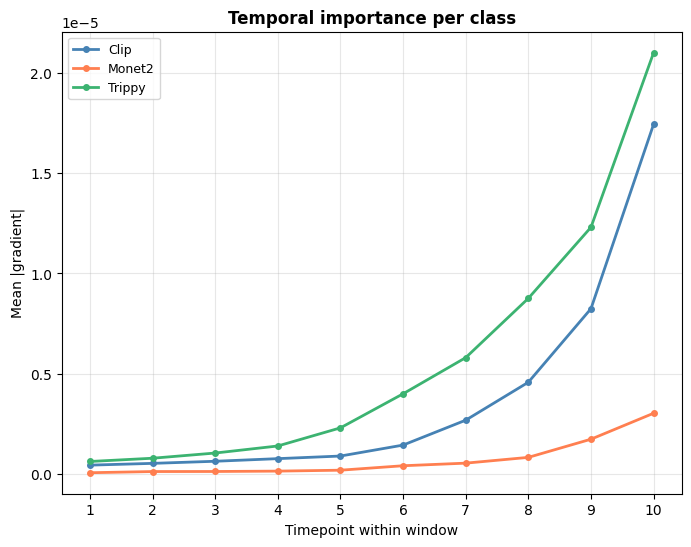

In [257]:
fig_single, ax_single = plt.subplots(figsize=(8, 6))

for cls_name, color in zip(classes_list, colors):
    ax_single.plot(timepoints, temporal_importance_per_class[cls_name],
                   label=cls_name, color=color, linewidth=2, 
                   marker="o", markersize=4)

ax_single.set_xlabel("Timepoint within window")
ax_single.set_ylabel("Mean |gradient|")
ax_single.set_title("Temporal importance per class", fontweight="bold")
ax_single.set_xticks(timepoints)
ax_single.legend(fontsize=9, frameon=True)
ax_single.grid(True, alpha=0.3)


plt.savefig("v1_temporal_importance_per_class.png", dpi=150, bbox_inches="tight")
plt.show() 

### What Are the Most Important Neurons Doing? (V1)

Using the gradient-based saliency computed above, we identify the **top 10 V1 neurons** by mean |gradient| and plot their activity traces across the 10-timepoint window, separately for each stimulus category (Clip, Monet2, Trippy). Each trace is averaged across all test windows belonging to the corresponding class (mean ± SEM). This is the temporal analogue of the *top-neuron analysis* reported for the static models in Part 1.1.

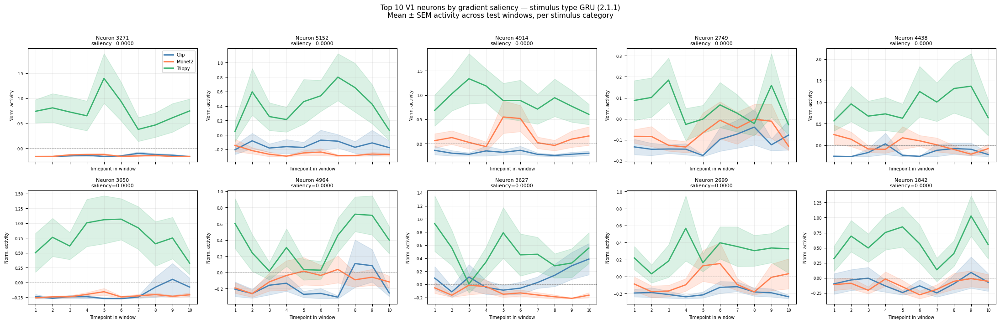

In [258]:
# ============================================================
# Top-10 V1 neurons by saliency — type GRU (2.1.1)
# Activity traces across the 10-timepoint window per class
# ============================================================
N_TOP        = 10
stim_colors  = ["steelblue", "coral", "mediumseagreen"]
top_sal_idx  = np.argsort(neuron_importance)[::-1][:N_TOP]
win_tp       = np.arange(1, X_test_sc.shape[1] + 1)

fig, axes = plt.subplots(2, N_TOP // 2, figsize=(22, 7), sharex=True)
axes = axes.flatten()

for rank, (ax, nidx) in enumerate(zip(axes, top_sal_idx)):
    for cls_idx, (cls_name, color) in enumerate(zip(classes_list, stim_colors)):
        mask   = y_test == cls_idx
        traces = X_test_sc[mask, :, nidx]        # (n_windows, 10)
        mean_t = traces.mean(axis=0)
        sem_t  = traces.std(axis=0) / np.sqrt(mask.sum())
        ax.plot(win_tp, mean_t, color=color, linewidth=2, label=cls_name)
        ax.fill_between(win_tp, mean_t - sem_t, mean_t + sem_t,
                        alpha=0.18, color=color)
    ax.set_title(f"Neuron {nidx}\nsaliency={neuron_importance[nidx]:.4f}", fontsize=8)
    ax.set_xlabel("Timepoint in window", fontsize=7)
    ax.set_ylabel("Norm. activity", fontsize=7)
    ax.tick_params(labelsize=6)
    ax.set_xticks(win_tp)
    ax.axhline(0, color='gray', linewidth=0.5, linestyle='--')
    ax.grid(True, alpha=0.2)
    if rank == 0:
        ax.legend(fontsize=7)

fig.suptitle(
    f"Top {N_TOP} V1 neurons by gradient saliency — stimulus type GRU (2.1.1)\n"
    "Mean ± SEM activity across test windows, per stimulus category",
    fontsize=11, y=1.01
)
plt.tight_layout()
plt.savefig("top_neurons_gru_type_V1.png", dpi=150, bbox_inches='tight')
plt.show()


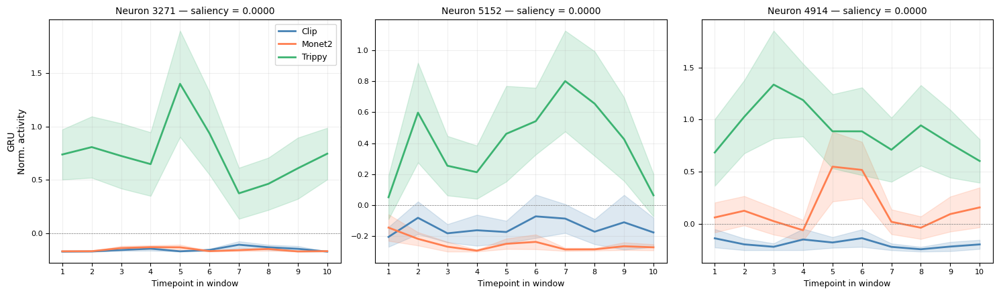

In [259]:
# ============================================================
# Top-3 V1 neurons by saliency — type GRU (2.1.1)
# Activity traces across the 10-timepoint window per class
# ============================================================
N_TOP       = 3
stim_colors = ["steelblue", "coral", "mediumseagreen"]
top_sal_idx = np.argsort(neuron_importance)[::-1][:N_TOP]
win_tp      = np.arange(1, X_test_sc.shape[1] + 1)

fig, axes = plt.subplots(1, N_TOP, figsize=(15, 4.5), sharex=True, sharey=False)

for rank, (ax, nidx) in enumerate(zip(axes, top_sal_idx)):
    for cls_idx, (cls_name, color) in enumerate(zip(classes_list, stim_colors)):
        mask   = y_test == cls_idx
        traces = X_test_sc[mask, :, nidx]                      # (n_windows, 10)
        mean_t = traces.mean(axis=0)
        sem_t  = traces.std(axis=0) / np.sqrt(mask.sum())
        ax.plot(win_tp, mean_t, color=color, linewidth=2, label=cls_name)
        ax.fill_between(win_tp, mean_t - sem_t, mean_t + sem_t,
                        alpha=0.18, color=color)

    ax.set_title(f"Neuron {nidx} — saliency = {neuron_importance[nidx]:.4f}",
                 fontsize=10)
    ax.set_xlabel("Timepoint in window", fontsize=9)
    if rank == 0:
        ax.set_ylabel("GRU\nNorm. activity", fontsize=10)
        ax.legend(fontsize=9, loc='upper right')
    ax.tick_params(labelsize=8)
    ax.set_xticks(win_tp)
    ax.axhline(0, color='gray', linewidth=0.5, linestyle='--')
    ax.grid(True, alpha=0.2)

plt.tight_layout()
plt.savefig("top_neurons_gru_type_V1.png", dpi=150, bbox_inches='tight')
plt.show()

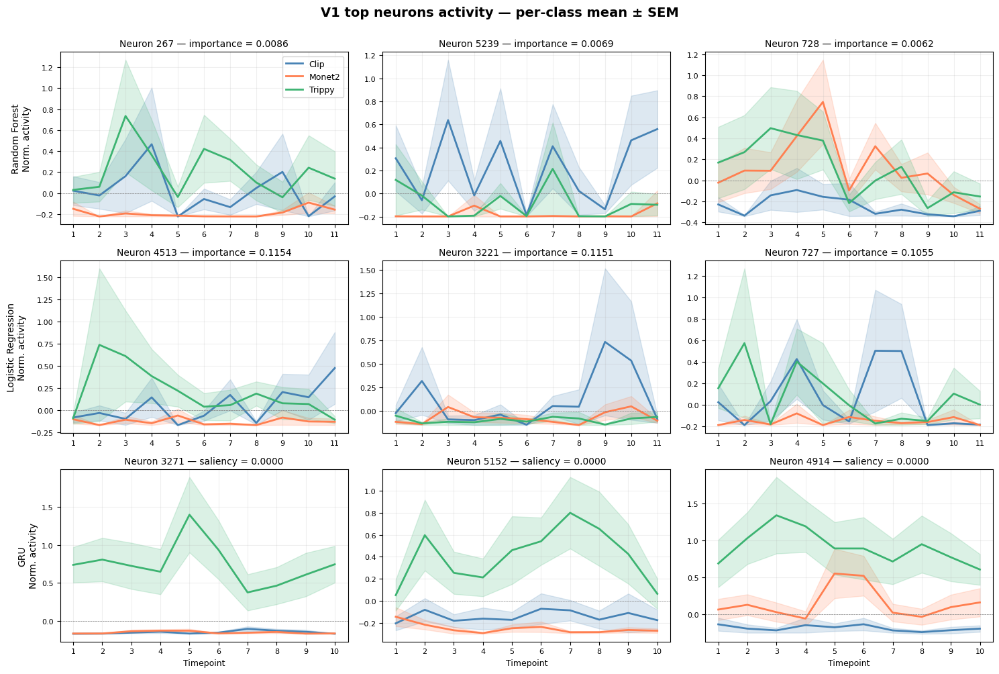

In [260]:
# ============================================================
# V1 top neurons activity — Static (RF, LR) + Temporal GRU
# 3x3 grid: classifiers (rows) × top-3 neurons (columns)
# ============================================================
import numpy as np
import matplotlib.pyplot as plt

N_TOP       = 3
stim_colors = ["steelblue", "coral", "mediumseagreen"]

# Static: 11 timepoints per trial
timepoints_static = np.arange(1, 11 + 1)
# GRU: 10 timepoints per window
win_tp = np.arange(1, X_test_sc.shape[1] + 1)

fig, axes = plt.subplots(3, N_TOP, figsize=(15, 10),
                         sharex=False, sharey=False)

rows = [
    ("Random Forest",       top_rf_idx,  rf_importance,     "importance",
     X_3d,      y_trial,    classes_v1,    timepoints_static),
    ("Logistic Regression", top_lr_idx,  lr_importance,     "importance",
     X_3d,      y_trial,    classes_v1,    timepoints_static),
    ("GRU",                 top_sal_idx, neuron_importance, "saliency",
     X_test_sc, y_test,     classes_list,  win_tp),
]

for row_idx, (clf_name, top_idx, imp_vals, imp_label,
              X_data, y_data, classes, t_axis) in enumerate(rows):
    for col_idx, neuron_idx in enumerate(top_idx):
        ax = axes[row_idx, col_idx]

        for cls_idx, (cls_name, color) in enumerate(zip(classes, stim_colors)):
            mask   = y_data == cls_idx
            traces = X_data[mask, :, neuron_idx]
            mean_t = traces.mean(axis=0)
            sem_t  = traces.std(axis=0) / np.sqrt(mask.sum())
            ax.plot(t_axis, mean_t, color=color, linewidth=2, label=cls_name)
            ax.fill_between(t_axis, mean_t - sem_t, mean_t + sem_t,
                            alpha=0.18, color=color)

        ax.set_title(f"Neuron {neuron_idx} — {imp_label} = {imp_vals[neuron_idx]:.4f}",
                     fontsize=10)
        ax.set_xticks(t_axis)
        ax.axhline(0, color='gray', linewidth=0.5, linestyle='--')
        ax.grid(True, alpha=0.2)
        ax.tick_params(labelsize=8)

        if col_idx == 0:
            ax.set_ylabel(f"{clf_name}\nNorm. activity", fontsize=10)
            if row_idx == 0:
                ax.legend(fontsize=9, loc='upper right')
        if row_idx == 2:
            ax.set_xlabel("Timepoint", fontsize=9)

fig.suptitle("V1 top neurons activity — per-class mean ± SEM",
             fontsize=14, fontweight='bold', y=1.00)
plt.tight_layout()
plt.savefig("top_neurons_activity.png", dpi=150, bbox_inches='tight')
plt.show()

### 2.1.2: Cross-area GRU on 387 neurons (30 random subsamples per area)


### Rationale and Experimental Design

This subsection moves from the V1-only analysis of 2.1.1 to a **fair cross-area comparison** of stimulus-type decoding across **V1, LM, AL, RL**, mirroring exactly the *Cross-Area Equalization via Random Subsampling* design of Part 1.1.

---

### Cross-Area Equalization via Random Subsampling

Each area is matched to the smallest population (**AL, 387 neurons**): for V1, LM and RL we randomly draw N = 387 neurons without replacement; for AL the full 387 neurons are used. The procedure is repeated **30 times** with independent neuron seeds. AL therefore has zero neuron-subsampling variance by construction, and its seed-to-seed variability comes entirely from training stochasticity (random weight initialization and batch shuffling).

This produces **30 GRUs per area × 4 areas = 120 trained models**, all sharing identical clip-level train/test split, identical hyperparameters and identical interpretability pipeline.

---

### Pipeline

The same three-step structure as 2.1.1:
1. **Dataset construction** — multi-area, multi-seed.
2. **GRU training** — 30 seeds per area.
3. **Interpretability** — saliency averaged across seeds.

#### Multi-area temporal dataset construction

### Dataset Construction — Matched 387-Neuron Subsamples

The same clip-level train/test split is used for every area and every seed, so cross-area differences are not driven by different stimuli being assigned to training or testing. Full-neuron windows are loaded **once per area**, and each seed then applies its own neuron subsample and its own train-only standardization in memory — avoiding 30× redundant disk reads.

Sliding-window parameters are identical to 2.1.1:
- **window size = 10 timepoints**
- **step size = 10 timepoints**
- **rep 0 → train, rep 1 → test**

This produces 30 matched temporal datasets per area, all trained under identical conditions and saved to:

- `dataset_temporal_V1_multiSeed.npz`
- `dataset_temporal_LM_multiSeed.npz`
- `dataset_temporal_AL_multiSeed.npz`
- `dataset_temporal_RL_multiSeed.npz`

In [261]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from collections import Counter
import numpy as np

# ============================================================
# SETUP
# ============================================================
N_TRIALS    = 40
WINDOW_SIZE = 10
STEP_SIZE   = 10
TEST_SIZE   = 0.2
AREAS       = ["V1", "LM", "AL", "RL"]
RANDOM_SEED = 42
N_SEEDS     = 30
np.random.seed(RANDOM_SEED)

print("=" * 70)
print(f"VIDEO TYPE DATASET — ALL AREAS ({N_SEEDS} NEURON SEEDS)")
print("=" * 70)

# ============================================================
# STEP 1 — Select unique clips with at least 2 repetitions
# ============================================================
monet_counts  = Counter(monet_hashes)
trippy_counts = Counter(trippy_hashes)
clip_counts   = Counter(clip_hashes)

unique_monet  = [h for h, c in monet_counts.items()  if c >= 2]
unique_trippy = [h for h, c in trippy_counts.items() if c >= 2]
unique_clip   = [h for h, c in clip_counts.items()   if c >= 2]

unique_clip = list(np.random.choice(unique_clip,
                   min(N_TRIALS, len(unique_clip)),
                   replace=False))

print(f"Valid unique clips (>=2 reps):")
print(f"   Monet2: {len(unique_monet)}")
print(f"   Clip:   {len(unique_clip)}")
print(f"   Trippy: {len(unique_trippy)}")

# ============================================================
# STEP 2 — Split at clip level (same split for all areas/seeds)
# ============================================================
monet_train,  monet_test  = train_test_split(unique_monet,  test_size=TEST_SIZE, random_state=RANDOM_SEED)
clip_train,   clip_test   = train_test_split(unique_clip,   test_size=TEST_SIZE, random_state=RANDOM_SEED)
trippy_train, trippy_test = train_test_split(unique_trippy, test_size=TEST_SIZE, random_state=RANDOM_SEED)

hash_split = {
    "Monet2": (monet_train, monet_test),
    "Clip":   (clip_train,  clip_test),
    "Trippy": (trippy_train, trippy_test),
}

# ============================================================
# STEP 3 — Probe neuron counts per area
# ============================================================
def get_n_neurons(funcreader, area):
    r = funcreader.get_responses_by_hash(unique_monet[0], area)[0]
    return r["responses"].shape[0]

neuron_counts = {}
for area in AREAS:
    try:
        neuron_counts[area] = get_n_neurons(funcreader, area)
        print(f"   {area}: {neuron_counts[area]} neurons")
    except Exception as e:
        print(f"   {area}: probe failed — {e}")

N_NEURONS_SUBSAMPLE = min(neuron_counts.values())
print(f"\n→ Subsampling all areas to {N_NEURONS_SUBSAMPLE} neurons (smallest area)")
print(f"→ Generating {N_SEEDS} independent neuron samples per area")

# ============================================================
# STEP 4 — Generate N_SEEDS neuron index sets per area
# ============================================================
neuron_index_sets = {}
for area in AREAS:
    seeds_for_area = []
    for seed_idx in range(N_SEEDS):
        rng = np.random.default_rng(seed=RANDOM_SEED * 100 + seed_idx)
        idx = np.sort(rng.choice(neuron_counts[area],
                                 size=N_NEURONS_SUBSAMPLE,
                                 replace=False))
        seeds_for_area.append(idx)
    neuron_index_sets[area] = seeds_for_area
    print(f"   {area}: {N_SEEDS} neuron subsets ready")

# ============================================================
# STEP 5 — Windowed extraction helpers
# ============================================================
def extract_windows(funcreader, hash_val, rep_idx, area,
                    window_size, step_size, neuron_idx=None):
    r         = funcreader.get_responses_by_hash(hash_val, area)[rep_idx]
    responses = r["responses"].T                        # (n_timepoints, n_neurons)
    if neuron_idx is not None:
        responses = responses[:, neuron_idx]
    windows = []
    for start in range(0, responses.shape[0] - window_size + 1, step_size):
        windows.append(responses[start:start + window_size, :])
    return np.stack(windows)                            # (n_windows, T, n_neurons)


def build_windowed_split(funcreader, hash_dict, rep_idx, area,
                         window_size, step_size, neuron_idx=None):
    X_list, y_list = [], []
    for label, hashes in hash_dict.items():
        for h in hashes:
            windows = extract_windows(funcreader, h, rep_idx, area,
                                      window_size, step_size, neuron_idx)
            X_list.append(windows)
            y_list.extend([label] * windows.shape[0])
    return np.vstack(X_list), np.array(y_list)

# ============================================================
# STEP 6 — Build full-neuron windows once per area,
#           then subsample + scale per seed in memory
# ============================================================
def build_full_neuron_split(area):
    """Load all windows with every neuron — no subsampling yet."""
    train_hashes = {lbl: splits[0] for lbl, splits in hash_split.items()}
    test_hashes  = {lbl: splits[1] for lbl, splits in hash_split.items()}

    X_train_raw, y_train_raw = build_windowed_split(
        funcreader, train_hashes, rep_idx=0,
        area=area, window_size=WINDOW_SIZE, step_size=STEP_SIZE,
        neuron_idx=None                                 # ← all neurons
    )
    X_test_raw, y_test_raw = build_windowed_split(
        funcreader, test_hashes, rep_idx=1,
        area=area, window_size=WINDOW_SIZE, step_size=STEP_SIZE,
        neuron_idx=None
    )

    # Label encoding — fit once, shared across all seeds
    le = LabelEncoder()
    le.fit(y_train_raw)
    y_train = le.transform(y_train_raw).astype(np.int64)
    y_test  = le.transform(y_test_raw).astype(np.int64)

    X_train = np.nan_to_num(X_train_raw.astype(np.float64),
                            nan=0.0, posinf=0.0, neginf=0.0)
    X_test  = np.nan_to_num(X_test_raw.astype(np.float64),
                            nan=0.0, posinf=0.0, neginf=0.0)
    return X_train, X_test, y_train, y_test, le


# area_datasets[area] = list of N_SEEDS dicts, each ready to train on
area_datasets = {area: [] for area in AREAS}

for area in AREAS:
    print(f"\n{'='*60}")
    print(f"Building datasets — {area}  ({N_SEEDS} seeds)")
    print(f"{'='*60}")

    print("   Loading full-neuron windows...", end=" ", flush=True)
    X_train_full, X_test_full, y_train, y_test, le = build_full_neuron_split(area)
    print(f"done  {X_train_full.shape}")

    n_train, T, N_full = X_train_full.shape
    n_test             = X_test_full.shape[0]

    for seed_idx, neuron_idx in enumerate(neuron_index_sets[area]):

        # Subsample neurons
        X_tr = X_train_full[:, :, neuron_idx]       # (n_windows, T, N_sub)
        X_te = X_test_full[:,  :, neuron_idx]

        # Normalize — fit on train only
        scaler = StandardScaler()
        X_tr_sc = scaler.fit_transform(
            X_tr.reshape(-1, N_NEURONS_SUBSAMPLE)
        ).reshape(n_train, T, N_NEURONS_SUBSAMPLE)
        X_te_sc = scaler.transform(
            X_te.reshape(-1, N_NEURONS_SUBSAMPLE)
        ).reshape(n_test, T, N_NEURONS_SUBSAMPLE)

        area_datasets[area].append({
            "X_train":        X_tr_sc,
            "X_test":         X_te_sc,
            "y_train":        y_train,
            "y_test":         y_test,
            "classes":        le.classes_,
            "le":             le,
            "n_neurons_used": N_NEURONS_SUBSAMPLE,
            "seed_idx":       seed_idx,
            "neuron_indices": neuron_idx,
        })

    # Sanity check on seed 0
    d = area_datasets[area][0]
    print(f"   X_train: {d['X_train'].shape}   X_test: {d['X_test'].shape}")
    print(f"   Classes: {le.classes_}")
    unique, counts = np.unique(y_train, return_counts=True)
    for cls_int, count in zip(unique, counts):
        print(f"      {le.classes_[cls_int]}: {count} windows ({count/len(y_train)*100:.1f}%)")

    # Save all seeds for this area in one file
    save_dict = {
        "y_train":            y_train,
        "y_test":             y_test,
        "classes":            le.classes_,
        "n_neurons_subsample": N_NEURONS_SUBSAMPLE,
    }
    for seed_idx, d in enumerate(area_datasets[area]):
        save_dict[f"X_train_seed{seed_idx}"]   = d["X_train"]
        save_dict[f"X_test_seed{seed_idx}"]    = d["X_test"]
        save_dict[f"neuron_idx_seed{seed_idx}"] = d["neuron_indices"]

    fname = f"dataset_temporal_{area}_multiSeed.npz"
    np.savez(fname, **save_dict)
    print(f"    Saved → {fname}")

print(f"\n{'='*60}")
print(f"All areas · {N_NEURONS_SUBSAMPLE} neurons · {N_SEEDS} seeds — ready ")
print(f"{'='*60}")

VIDEO TYPE DATASET — ALL AREAS (30 NEURON SEEDS)
Valid unique clips (>=2 reps):
   Monet2: 20
   Clip:   40
   Trippy: 20
   V1: 5312 neurons
   LM: 983 neurons
   AL: 387 neurons
   RL: 811 neurons

→ Subsampling all areas to 387 neurons (smallest area)
→ Generating 30 independent neuron samples per area
   V1: 30 neuron subsets ready
   LM: 30 neuron subsets ready
   AL: 30 neuron subsets ready
   RL: 30 neuron subsets ready

Building datasets — V1  (30 seeds)
   Loading full-neuron windows... done  (576, 10, 5312)
   X_train: (576, 10, 387)   X_test: (144, 10, 387)
   Classes: ['Clip' 'Monet2' 'Trippy']
      Clip: 224 windows (38.9%)
      Monet2: 176 windows (30.6%)
      Trippy: 176 windows (30.6%)
    Saved → dataset_temporal_V1_multiSeed.npz

Building datasets — LM  (30 seeds)
   Loading full-neuron windows... done  (576, 10, 983)
   X_train: (576, 10, 387)   X_test: (144, 10, 387)
   Classes: ['Clip' 'Monet2' 'Trippy']
      Clip: 224 windows (38.9%)
      Monet2: 176 windows 

Using device: mps


   ── V1 summary ──
   Acc:    0.8100 ± 0.0320
   F1:     0.8066 ± 0.0333
   Chance: 0.3333

   ── LM summary ──
   Acc:    0.7840 ± 0.0242
   F1:     0.7728 ± 0.0263
   Chance: 0.3333

   ── AL summary ──
   Acc:    0.7903 ± 0.0202
   F1:     0.7849 ± 0.0205
   Chance: 0.3333

   ── RL summary ──
   Acc:    0.7988 ± 0.0297
   F1:     0.7917 ± 0.0312
   Chance: 0.3333


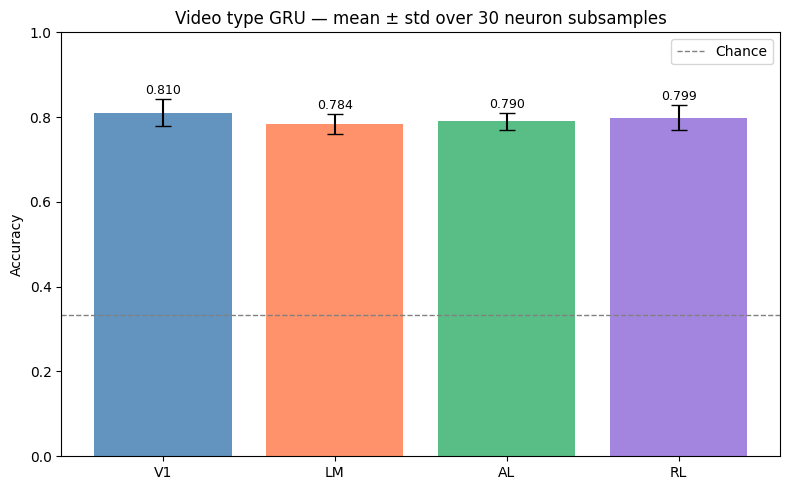

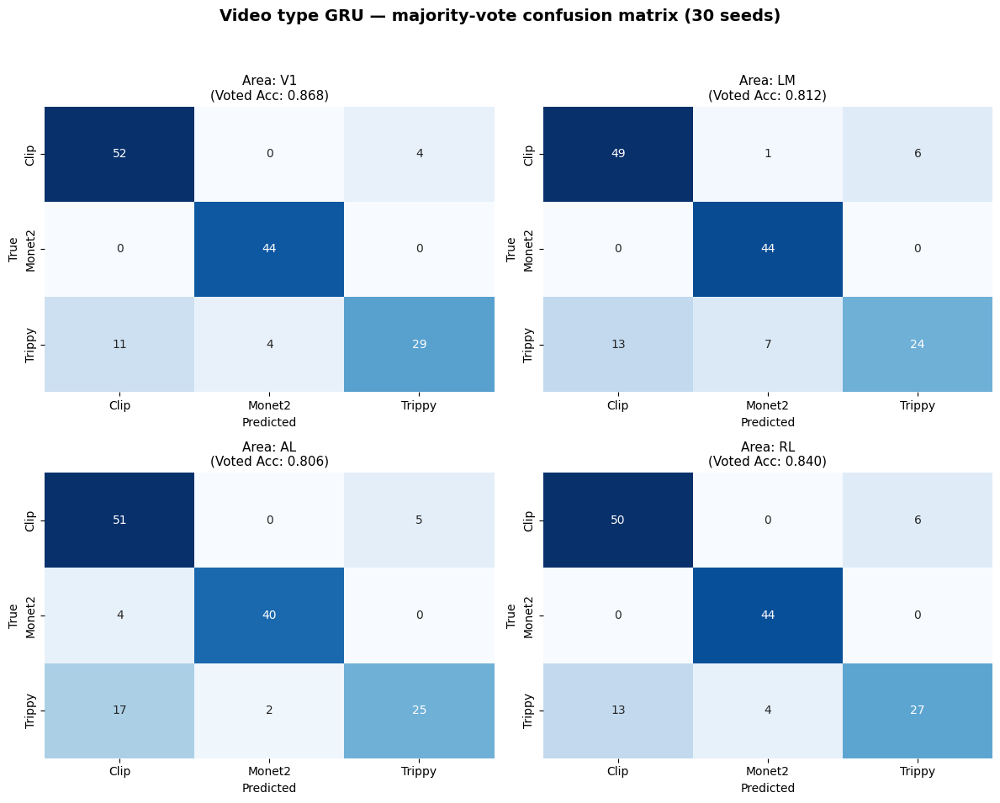


Area         Acc (mean±std)        F1 (mean±std)  vs chance
V1     0.8100 ± 0.0320   0.8066 ± 0.0333   +47.7pp
LM     0.7840 ± 0.0242   0.7728 ± 0.0263   +45.1pp
AL     0.7903 ± 0.0202   0.7849 ± 0.0205   +45.7pp
RL     0.7988 ± 0.0297   0.7917 ± 0.0312   +46.6pp


In [262]:
import copy
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# ============================================================
# Model definition (unchanged)
# ============================================================
class NeuralGRU(nn.Module):
    def __init__(self, n_neurons, proj_dim, hidden_dim,
                 n_layers, n_classes, dropout=0.3):
        super().__init__()
        self.projection = nn.Linear(n_neurons, proj_dim)
        self.gru = nn.GRU(input_size=proj_dim, hidden_size=hidden_dim,
                          num_layers=n_layers, batch_first=True,
                          dropout=dropout if n_layers > 1 else 0.0)
        self.dropout    = nn.Dropout(dropout)
        self.classifier = nn.Linear(hidden_dim, n_classes)

    def forward(self, x):
        x      = self.projection(x)
        _, h_n = self.gru(x)
        return self.classifier(self.dropout(h_n[-1]))


# ============================================================
# Single-seed training
# ============================================================
def train_one_seed(dataset, device,
                   proj_dim=64, hidden_dim=64, n_layers=1, dropout=0.3,
                   lr=1e-3, weight_decay=1e-4,
                   n_epochs=100, patience=15, batch_size=64):

    X_train  = torch.tensor(dataset["X_train"].astype(np.float32))
    y_train  = torch.tensor(dataset["y_train"])
    X_test   = torch.tensor(dataset["X_test"].astype(np.float32))
    y_test   = torch.tensor(dataset["y_test"])
    classes  = dataset["classes"]
    n_classes = len(classes)
    n_neurons = X_train.shape[2]

    train_loader = DataLoader(TensorDataset(X_train, y_train),
                              batch_size=batch_size, shuffle=True)
    test_loader  = DataLoader(TensorDataset(X_test,  y_test),
                              batch_size=batch_size, shuffle=False)

    model = NeuralGRU(n_neurons, proj_dim, hidden_dim,
                      n_layers, n_classes, dropout).to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode="min", patience=5, factor=0.5)

    best_val_loss, best_state, no_improve = float("inf"), None, 0

    for epoch in range(n_epochs):
        model.train()
        for Xb, yb in train_loader:
            Xb, yb = Xb.to(device), yb.to(device)
            optimizer.zero_grad()
            loss = criterion(model(Xb), yb)
            loss.backward()
            optimizer.step()

        model.eval()
        v_loss, v_correct, v_total = 0.0, 0, 0
        with torch.no_grad():
            for Xb, yb in test_loader:
                Xb, yb = Xb.to(device), yb.to(device)
                logits  = model(Xb)
                v_loss += criterion(logits, yb).item() * Xb.size(0)
                v_correct += (logits.argmax(1) == yb).sum().item()
                v_total   += Xb.size(0)
        val_loss = v_loss / v_total
        scheduler.step(val_loss)

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_state    = copy.deepcopy(model.state_dict())
            no_improve    = 0
        else:
            no_improve += 1
        if no_improve >= patience:
            break

    model.load_state_dict(best_state)
    model.eval()
    all_preds, all_labels = [], []
    with torch.no_grad():
        for Xb, yb in test_loader:
            all_preds.extend(model(Xb.to(device)).argmax(1).cpu().numpy())
            all_labels.extend(yb.numpy())

    all_preds  = np.array(all_preds)
    all_labels = np.array(all_labels)

    return {
        "acc":     accuracy_score(all_labels, all_preds),
        "f1":      f1_score(all_labels, all_preds, average="weighted"),
        "preds":   all_preds,
        "labels":  all_labels,
        "classes": classes,
    }


# ============================================================
# Multi-seed loop per area
# ============================================================
device = torch.device(
    "cuda" if torch.cuda.is_available() else
    "mps"  if torch.backends.mps.is_available() else
    "cpu"
)
print(f"Using device: {device}\n")

aggregated_results = {}

for area in AREAS:
    seed_accs, seed_f1s = [], []
    all_seed_preds  = []
    all_seed_labels = None
    classes         = area_datasets[area][0]["classes"]
    n_classes       = len(classes)

    for seed_idx, dataset in enumerate(area_datasets[area]):
        torch.manual_seed(RANDOM_SEED * 100 + seed_idx)

        metrics = train_one_seed(dataset, device)

        seed_accs.append(metrics["acc"])
        seed_f1s.append(metrics["f1"])
        all_seed_preds.append(metrics["preds"])
        all_seed_labels = metrics["labels"]

    aggregated_results[area] = {
        "mean_acc":  np.mean(seed_accs),
        "std_acc":   np.std(seed_accs),
        "mean_f1":   np.mean(seed_f1s),
        "std_f1":    np.std(seed_f1s),
        "all_accs":  np.array(seed_accs),
        "seed_preds": np.stack(all_seed_preds),   # (N_SEEDS, n_test)
        "labels":    all_seed_labels,
        "classes":   classes,
        "n_classes": n_classes,
    }

    r = aggregated_results[area]
    print(f"\n   ── {area} summary ──")
    print(f"   Acc:    {r['mean_acc']:.4f} ± {r['std_acc']:.4f}")
    print(f"   F1:     {r['mean_f1']:.4f} ± {r['std_f1']:.4f}")
    print(f"   Chance: {1/n_classes:.4f}")


# ============================================================
# Plots
# ============================================================

# 1 — Bar chart with error bars (Invariato)
fig, ax = plt.subplots(figsize=(8, 5))
means  = [aggregated_results[a]["mean_acc"] for a in AREAS]
stds   = [aggregated_results[a]["std_acc"]  for a in AREAS]
colors = ["steelblue", "coral", "mediumseagreen", "mediumpurple"]
bars   = ax.bar(AREAS, means, yerr=stds, capsize=6,
                color=colors, alpha=0.85,
                error_kw={"linewidth": 1.5})
chance = 1 / aggregated_results[AREAS[0]]["n_classes"]
ax.axhline(chance, color="gray", linestyle="--", linewidth=1, label="Chance")
for bar, m, s in zip(bars, means, stds):
    ax.text(bar.get_x() + bar.get_width() / 2,
            bar.get_height() + s + 0.005,
            f"{m:.3f}", ha="center", va="bottom", fontsize=9)
ax.set_ylabel("Accuracy")
ax.set_title(f"Video type GRU — mean ± std over {N_SEEDS} neuron subsamples")
ax.set_ylim(0, 1.0)
ax.legend()
plt.tight_layout()
plt.savefig("videotype_gru_area_comparison_bar.png", dpi=150)
plt.show()

# 2 — Majority-vote confusion matrix per area (GRID 2x2)
# Cambiato layout a 2 righe e 2 colonne
fig, axes = plt.subplots(2, 2, figsize=(12, 10)) 
fig.suptitle(f"Video type GRU — majority-vote confusion matrix ({N_SEEDS} seeds)",
             fontsize=14, fontweight='bold')

# Appiattiamo l'array degli assi per iterare facilmente su 4 posizioni
axes_flat = axes.flatten()

for i, area in enumerate(AREAS):
    ax = axes_flat[i]
    r = aggregated_results[area]
    
    # Calcolo del voto di maggioranza tra i seed
    majority = np.apply_along_axis(
        lambda x: np.bincount(x, minlength=r["n_classes"]).argmax(),
        axis=0, arr=r["seed_preds"]
    )
    
    cm = confusion_matrix(r["labels"], majority)
    voted_acc = accuracy_score(r["labels"], majority)
    
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=ax,
                xticklabels=r["classes"], yticklabels=r["classes"],
                cbar=False) # Rimosso cbar per pulizia
    
    ax.set_title(f"Area: {area}\n(Voted Acc: {voted_acc:.3f})", fontsize=11)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("True")

# Rimuove eventuali assi vuoti se AREAS fosse < 4
for j in range(len(AREAS), len(axes_flat)):
    fig.delaxes(axes_flat[j])

plt.tight_layout(rect=[0, 0.03, 1, 0.95]) # Spazio per il suptitle
plt.savefig("videotype_gru_area_voted_cm_2x2.png", dpi=150)
plt.show()



# ============================================================
# Summary table
# ============================================================
print("\n" + "=" * 55)
print(f"{'Area':<6} {'Acc (mean±std)':>20} {'F1 (mean±std)':>20} {'vs chance':>10}")
print("=" * 55)
for area in AREAS:
    r = aggregated_results[area]
    print(f"{area:<6} "
          f"{r['mean_acc']:.4f} ± {r['std_acc']:.4f}   "
          f"{r['mean_f1']:.4f} ± {r['std_f1']:.4f}   "
          f"+{(r['mean_acc'] - 1/r['n_classes'])*100:.1f}pp")

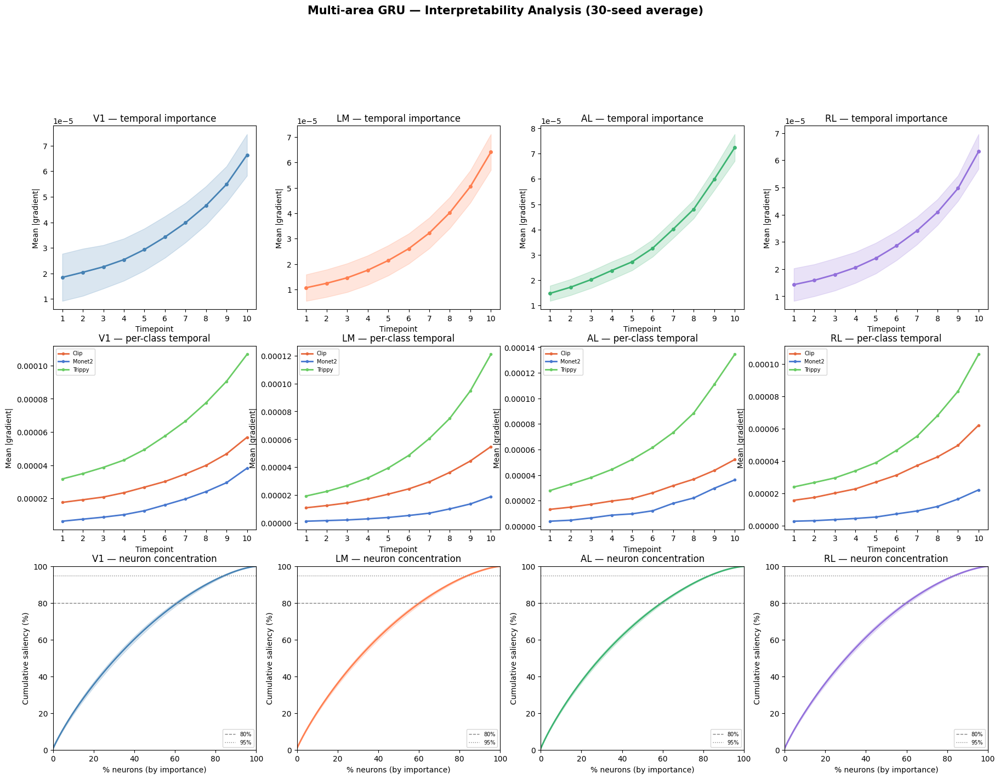

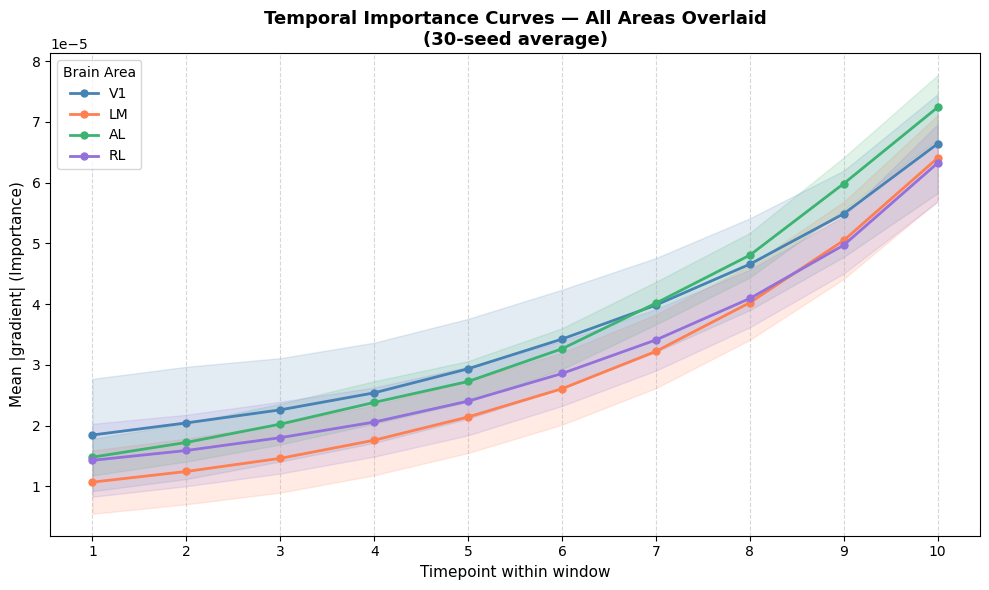


NEUROSCIENCE SUMMARY — CROSS-AREA

V1:
   Voted accuracy:         0.8681
   Peak discriminative t:  10/10  → recurrent/feedback-dominated
   80% signal in top:      76.7% of neurons  → distributed
   95% signal in top:      93.8% of neurons

LM:
   Voted accuracy:         0.8125
   Peak discriminative t:  10/10  → recurrent/feedback-dominated
   80% signal in top:      75.7% of neurons  → distributed
   95% signal in top:      93.0% of neurons

AL:
   Voted accuracy:         0.8056
   Peak discriminative t:  10/10  → recurrent/feedback-dominated
   80% signal in top:      63.0% of neurons  → distributed
   95% signal in top:      86.6% of neurons

RL:
   Voted accuracy:         0.8403
   Peak discriminative t:  10/10  → recurrent/feedback-dominated
   80% signal in top:      76.2% of neurons  → distributed
   95% signal in top:      93.5% of neurons


In [263]:
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.metrics import confusion_matrix, accuracy_score

# ============================================================
# STEP 1 — Rerun each seed's model to collect saliency
# We retrain each model from its saved seed state and compute
# gradients on that seed's test data
# ============================================================

def compute_saliency_for_seed(dataset, device,
                               proj_dim=64, hidden_dim=64,
                               n_layers=1, dropout=0.3):
    """
    Train a fresh model on this seed's data, then compute
    input-gradient saliency on the test set.
    Returns:
        neuron_importance        (n_neurons,)
        temporal_importance      (window_size,)
        neuron_imp_per_class     dict {cls_name: (n_neurons,)}
        temporal_imp_per_class   dict {cls_name: (window_size,)}
        preds, labels            for confusion matrix
    """
    X_train  = torch.tensor(dataset["X_train"].astype(np.float32))
    y_train  = torch.tensor(dataset["y_train"])
    X_test   = torch.tensor(dataset["X_test"].astype(np.float32))
    y_test_t = torch.tensor(dataset["y_test"])
    classes  = dataset["classes"]
    n_classes = len(classes)
    n_neurons = X_train.shape[2]

    import copy
    train_loader = torch.utils.data.DataLoader(
        torch.utils.data.TensorDataset(X_train, y_train),
        batch_size=64, shuffle=True)
    test_loader = torch.utils.data.DataLoader(
        torch.utils.data.TensorDataset(X_test, y_test_t),
        batch_size=64, shuffle=False)

    model = NeuralGRU(n_neurons, proj_dim, hidden_dim,
                      n_layers, n_classes, dropout).to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-4)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode="min", patience=5, factor=0.5)

    best_val_loss, best_state, no_improve = float("inf"), None, 0
    for epoch in range(100):
        model.train()
        for Xb, yb in train_loader:
            Xb, yb = Xb.to(device), yb.to(device)
            optimizer.zero_grad()
            nn.CrossEntropyLoss()(model(Xb), yb).backward()
            optimizer.step()
        model.eval()
        v_loss, v_total = 0.0, 0
        with torch.no_grad():
            for Xb, yb in test_loader:
                Xb, yb = Xb.to(device), yb.to(device)
                v_loss += criterion(model(Xb), yb).item() * Xb.size(0)
                v_total += Xb.size(0)
        val_loss = v_loss / v_total
        scheduler.step(val_loss)
        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_state    = copy.deepcopy(model.state_dict())
            no_improve    = 0
        else:
            no_improve += 1
        if no_improve >= 15:
            break

    model.load_state_dict(best_state)

    # ── Saliency ──────────────────────────────────────────
    model.train()                          # keep graph intact
    X_sal = X_test.to(device)
    X_sal.requires_grad_(True)
    y_sal = y_test_t.to(device)

    logits = model(X_sal)
    nn.CrossEntropyLoss()(logits, y_sal).backward()

    grads = X_sal.grad.detach().cpu().numpy()   # (n_samples, T, n_neurons)
    model.eval()

    abs_grads = np.abs(grads)
    neuron_sal_per_sample   = abs_grads.mean(axis=1)   # (n_samples, n_neurons)
    temporal_sal_per_sample = abs_grads.mean(axis=2)   # (n_samples, T)

    neuron_importance   = neuron_sal_per_sample.mean(axis=0)
    temporal_importance = temporal_sal_per_sample.mean(axis=0)

    y_np = dataset["y_test"]
    neuron_imp_per_class   = {}
    temporal_imp_per_class = {}
    for cls_idx, cls_name in enumerate(classes):
        mask = y_np == cls_idx
        neuron_imp_per_class[cls_name]   = neuron_sal_per_sample[mask].mean(axis=0)
        temporal_imp_per_class[cls_name] = temporal_sal_per_sample[mask].mean(axis=0)

    # ── Predictions ───────────────────────────────────────
    all_preds = []
    with torch.no_grad():
        for Xb, _ in test_loader:
            all_preds.extend(model(Xb.to(device)).argmax(1).cpu().numpy())

    return {
        "neuron_importance":        neuron_importance,
        "temporal_importance":      temporal_importance,
        "neuron_imp_per_class":     neuron_imp_per_class,
        "temporal_imp_per_class":   temporal_imp_per_class,
        "preds":                    np.array(all_preds),
        "labels":                   y_np,
    }


# ── Run across all areas and seeds ────────────────────────
# saliency_results[area] = dict of aggregated arrays
saliency_results = {}

for area in AREAS:

    datasets  = area_datasets[area]
    classes   = datasets[0]["classes"]
    n_neurons = datasets[0]["X_train"].shape[2]
    T         = datasets[0]["X_train"].shape[1]

    seed_neuron_imp   = []          # (N_SEEDS, n_neurons)
    seed_temporal_imp = []          # (N_SEEDS, T)
    seed_neuron_per_class   = {c: [] for c in classes}
    seed_temporal_per_class = {c: [] for c in classes}
    seed_preds  = []
    seed_labels = None

    for seed_idx, dataset in enumerate(datasets):
        torch.manual_seed(RANDOM_SEED * 100 + seed_idx)
        r = compute_saliency_for_seed(dataset, device)

        seed_neuron_imp.append(r["neuron_importance"])
        seed_temporal_imp.append(r["temporal_importance"])
        for c in classes:
            seed_neuron_per_class[c].append(r["neuron_imp_per_class"][c])
            seed_temporal_per_class[c].append(r["temporal_imp_per_class"][c])
        seed_preds.append(r["preds"])
        seed_labels = r["labels"]


    # Average across seeds
    saliency_results[area] = {
        "classes":        classes,
        "n_neurons":      n_neurons,
        "T":              T,
        # mean + std over seeds → (n_neurons,)
        "neuron_imp_mean":  np.mean(seed_neuron_imp,   axis=0),
        "neuron_imp_std":   np.std(seed_neuron_imp,    axis=0),
        # mean + std over seeds → (T,)
        "temporal_imp_mean": np.mean(seed_temporal_imp, axis=0),
        "temporal_imp_std":  np.std(seed_temporal_imp,  axis=0),
        # per-class means → dict {cls: (n_neurons,)} and {cls: (T,)}
        "neuron_per_class":   {c: np.mean(seed_neuron_per_class[c],   axis=0) for c in classes},
        "temporal_per_class": {c: np.mean(seed_temporal_per_class[c], axis=0) for c in classes},
        # majority vote predictions
        "majority_preds": np.apply_along_axis(
            lambda x: np.bincount(x, minlength=len(classes)).argmax(),
            axis=0, arr=np.stack(seed_preds)
        ),
        "labels": seed_labels,
        # full distribution for cumulative plot
        "all_neuron_imp": np.array(seed_neuron_imp),   # (N_SEEDS, n_neurons)
    }



# ============================================================
# STEP 3 — Temporal response profiles (seed 0 per area)
# ============================================================
temporal_profiles = {}
for area in AREAS:
    d = area_datasets[area][0]
    profiles = {}
    for cls_idx, cls_name in enumerate(d["classes"]):
        mask = d["y_test"] == cls_idx
        profiles[cls_name] = d["X_test"][mask].mean(axis=0).mean(axis=1)
    temporal_profiles[area] = profiles


# ============================================================
# PLOTS
# ============================================================
area_colors = ["steelblue", "coral", "mediumseagreen", "mediumpurple"]
class_colors = ["#E6693E", "#4878CF", "#6ACC65"]   # Monet, Clip, Trippy
timepoints   = np.arange(1, saliency_results[AREAS[0]]["T"] + 1)

fig = plt.figure(figsize=(22, 20))
fig.suptitle("Multi-area GRU — Interpretability Analysis (30-seed average)",
             fontsize=15, fontweight="bold", y=0.99)

# ── Row 1: Temporal importance per area ───────────────────
for col, (area, a_color) in enumerate(zip(AREAS, area_colors)):
    ax = fig.add_subplot(4, 4, col + 1)
    r  = saliency_results[area]
    mean = r["temporal_imp_mean"]
    std  = r["temporal_imp_std"]
    ax.plot(timepoints, mean, color=a_color, linewidth=2, marker="o", markersize=4)
    ax.fill_between(timepoints, mean - std, mean + std,
                    alpha=0.2, color=a_color)
    ax.set_title(f"{area} — temporal importance")
    ax.set_xlabel("Timepoint")
    ax.set_ylabel("Mean |gradient|")
    ax.set_xticks(timepoints)

# ── Row 2: Per-class temporal importance per area ─────────
for col, (area, a_color) in enumerate(zip(AREAS, area_colors)):
    ax = fig.add_subplot(4, 4, col + 5)
    r  = saliency_results[area]
    for cls_name, c_color in zip(r["classes"], class_colors):
        ax.plot(timepoints, r["temporal_per_class"][cls_name],
                label=cls_name, color=c_color, linewidth=2,
                marker="o", markersize=3)
    ax.set_title(f"{area} — per-class temporal")
    ax.set_xlabel("Timepoint")
    ax.set_ylabel("Mean |gradient|")
    ax.set_xticks(timepoints)
    ax.legend(fontsize=7)

# ── Row 3: Cumulative neuron saliency per area ────────────
for col, (area, a_color) in enumerate(zip(AREAS, area_colors)):
    ax  = fig.add_subplot(4, 4, col + 9)
    r   = saliency_results[area]
    # Average cumulative curve across seeds
    all_curves = []
    for seed_imp in r["all_neuron_imp"]:
        sorted_imp = np.sort(seed_imp)[::-1]
        cum = np.cumsum(sorted_imp) / np.sum(sorted_imp)
        all_curves.append(cum)
    all_curves = np.array(all_curves)
    mean_curve = all_curves.mean(axis=0)
    std_curve  = all_curves.std(axis=0)
    x_axis = np.linspace(0, 100, len(mean_curve))
    ax.plot(x_axis, mean_curve * 100, color=a_color, linewidth=2)
    ax.fill_between(x_axis,
                    (mean_curve - std_curve) * 100,
                    (mean_curve + std_curve) * 100,
                    alpha=0.2, color=a_color)
    for thresh, ls in [(80, "--"), (95, ":")]:
        ax.axhline(thresh, color="gray", linestyle=ls, linewidth=1,
                   label=f"{thresh}%")
    ax.set_xlabel("% neurons (by importance)")
    ax.set_ylabel("Cumulative saliency (%)")
    ax.set_title(f"{area} — neuron concentration")
    ax.set_xlim(0, 100); ax.set_ylim(0, 100)
    ax.legend(fontsize=7)


# ============================================================
# CROSS-AREA COMPARISON PLOT
# ============================================================
fig, ax = plt.subplots(figsize=(10, 6))


for area, a_color in zip(AREAS, area_colors):
    r    = saliency_results[area]
    mean = r["temporal_imp_mean"]
    std  = r["temporal_imp_std"]
    
    ax.plot(timepoints, mean, label=area, color=a_color,
            linewidth=2, marker="o", markersize=5) 
    ax.fill_between(timepoints, mean - std, mean + std,
                    alpha=0.15, color=a_color)


ax.set_xlabel("Timepoint within window", fontsize=11)
ax.set_ylabel("Mean |gradient| (Importance)", fontsize=11)
ax.set_title("Temporal Importance Curves — All Areas Overlaid\n(30-seed average)", fontsize=13, fontweight='bold')

ax.set_xticks(timepoints)
ax.grid(axis='x', linestyle='--', alpha=0.5) 
ax.legend(title="Brain Area", fontsize=10)

plt.tight_layout() 
plt.savefig("temporal_importance_overlaid.png", dpi=150) 
plt.show()

# ============================================================
# SUMMARY
# ============================================================
print("\n" + "=" * 65)
print("NEUROSCIENCE SUMMARY — CROSS-AREA")
print("=" * 65)

for area in AREAS:
    r = saliency_results[area]

    # Concentration
    mean_imp     = r["neuron_imp_mean"]
    sorted_imp   = np.sort(mean_imp)[::-1]
    cumulative   = np.cumsum(sorted_imp) / np.sum(sorted_imp)
    p80 = (np.searchsorted(cumulative, 0.80) + 1) / r["n_neurons"] * 100
    p95 = (np.searchsorted(cumulative, 0.95) + 1) / r["n_neurons"] * 100

    # Peak timepoint
    peak_t = np.argmax(r["temporal_imp_mean"]) + 1

    # Voted accuracy
    voted_acc = accuracy_score(r["labels"], r["majority_preds"])

    print(f"\n{area}:")
    print(f"   Voted accuracy:         {voted_acc:.4f}")
    print(f"   Peak discriminative t:  {peak_t}/{r['T']}  ", end="")
    if peak_t <= 3:
        print("→ feedforward-dominated")
    elif peak_t >= 8:
        print("→ recurrent/feedback-dominated")
    else:
        print("→ mixed")
    print(f"   80% signal in top:      {p80:.1f}% of neurons  ", end="")
    print("→ concentrated" if p80 < 20 else "→ distributed")
    print(f"   95% signal in top:      {p95:.1f}% of neurons")


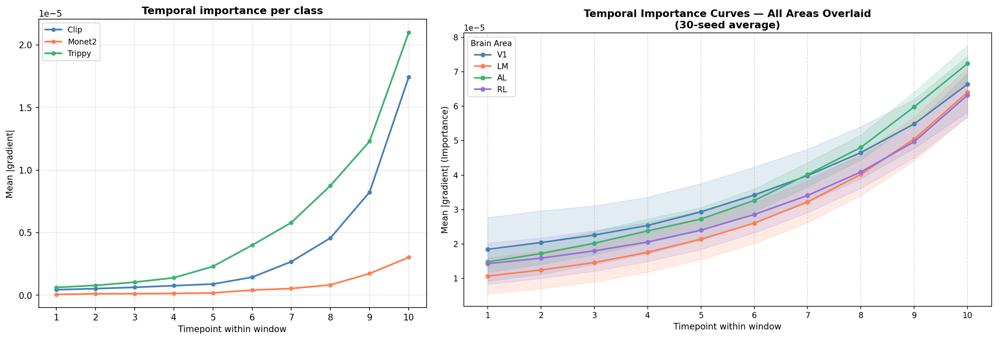

In [264]:
from PIL import Image

def join_images_scaled(path1, path2, output_name):
    img1 = Image.open(path1)
    img2 = Image.open(path2)

    target_height = img1.height

    aspect_ratio = img2.width / img2.height
    new_width = int(target_height * aspect_ratio)
    img2_resized = img2.resize((new_width, target_height), Image.Resampling.LANCZOS)

    combined = Image.new("RGB", (img1.width + img2_resized.width, target_height), (255, 255, 255))

    combined.paste(img1, (0, 0))
    combined.paste(img2_resized, (img1.width, 0))

    combined.save(output_name)
    return combined

try:
    result = join_images_scaled(
        "v1_temporal_importance_per_class.png", 
        "temporal_importance_overlaid.png", 
        "Temporal_Importance_Combined.png"
    )
    display(result)
except Exception as e:
    print(f"Error: {e}")

### Results

**All four visual areas decode stimulus type well above the 33.3% chance baseline**, confirming the Part 1 finding that population-level category representations are **distributed throughout the visual hierarchy** rather than confined to V1. Mean accuracy across the 30 neuron seeds is:

- **V1:** **0.8100 ± 0.0320** (F1 0.8066 ± 0.0333)
- **LM:** **0.7840 ± 0.0242** (F1 0.7728 ± 0.0263)
- **AL:** **0.7903 ± 0.0202** (F1 0.7849 ± 0.0205)
- **RL:** **0.7988 ± 0.0297** (F1 0.7917 ± 0.0312)

**The cross-area ranking is V1 > RL > AL > LM, but the gap between best (V1) and worst (LM) is only ≈3 pp** — comparable to the seed-to-seed standard deviation. Broad video-type information is therefore represented strongly across the entire visual hierarchy, with V1 only marginally ahead in this matched-neuron temporal setting.

**Comparison with the static models of Part 1.1.** With 387 neurons the static ranking led by RF was AL > LM > RL > V1 (RF 0.7955 / 0.7528 / 0.7487 / 0.7149). Adding short-window temporal dynamics changes the cross-area ordering: V1 jumps from worst static to best temporal area, suggesting that V1's category information is carried more strongly in the **time-evolution of the response** than in any single snapshot.

**Saliency reveals a distributed code in every area.** Reaching 80% of the total saliency requires:
- **V1:** 76.7% of neurons
- **LM:** 75.7%
- **AL:** 63.0%
- **RL:** 76.2%

AL appears slightly more concentrated, but all four areas remain firmly in the *distributed* regime rather than relying on a small dominant subpopulation.

**Temporal saliency peaks at the last window timepoint (t = 10/10) in every area**, consistent with feedback / recurrent processing across the visual hierarchy. Majority-vote accuracies across the 30 retrained models remain high — V1 0.8681, LM 0.8125, AL 0.8056, RL 0.8403 — confirming that the per-seed results are stable rather than driven by a few lucky draws.

### What Are the Most Important Neurons Doing? (All Areas)

For each area we use the **30-seed averaged neuron saliency** computed above. The top 10 neurons per area are selected and their mean activity traces across the 10-timepoint window are plotted separately for each stimulus category, using the test data of seed 0 as a representative subsampled population. This mirrors the *top-neurons-per-area* analysis of Part 1.1.

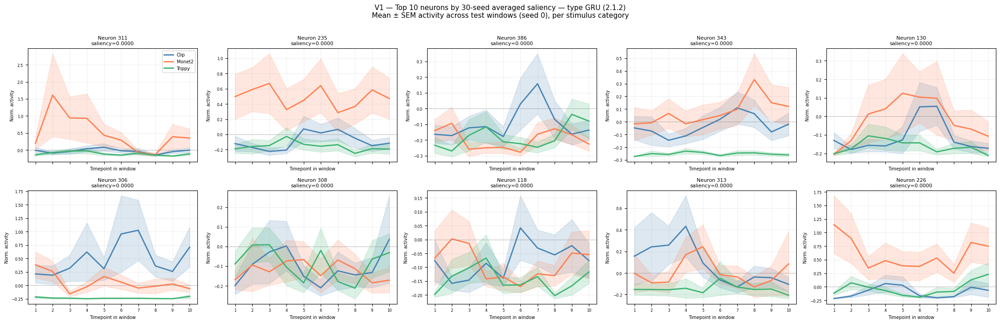

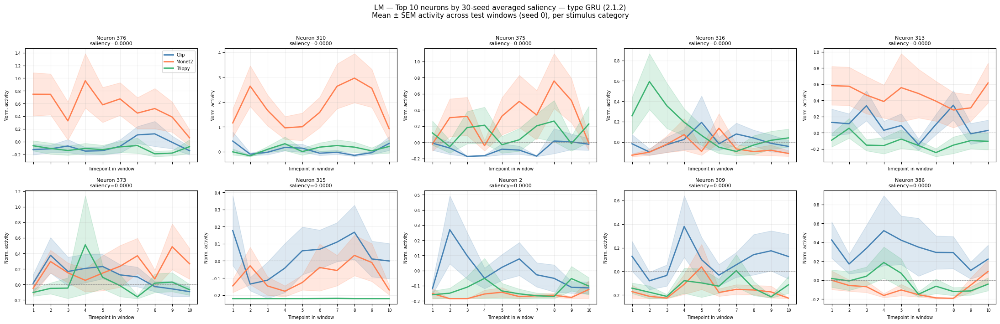

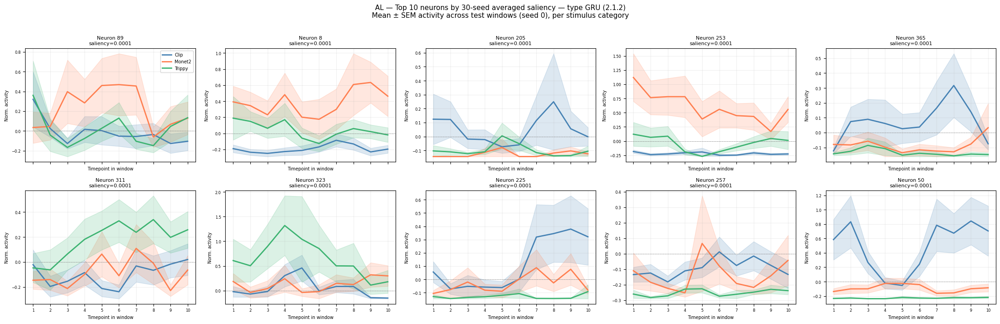

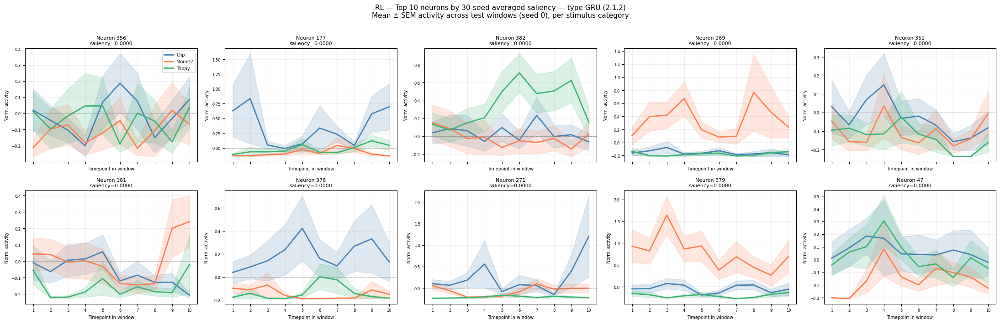

In [265]:
# ============================================================
# Top-10 neurons per area by aggregated saliency — type GRU (2.1.2)
# ============================================================
N_TOP       = 10
stim_colors = ["steelblue", "coral", "mediumseagreen"]
win_tp      = np.arange(1, area_datasets[AREAS[0]][0]["X_test"].shape[1] + 1)

for area in AREAS:
    imp_mean = saliency_results[area]["neuron_imp_mean"]   # (387,)
    top_idx  = np.argsort(imp_mean)[::-1][:N_TOP]

    # Use seed-0 test data as representative
    d        = area_datasets[area][0]
    X_te     = d["X_test"]    # (n_windows, 10, 387)
    y_te     = d["y_test"]
    classes  = d["classes"]

    fig, axes = plt.subplots(2, N_TOP // 2, figsize=(22, 7), sharex=True)
    axes = axes.flatten()

    for rank, (ax, nidx) in enumerate(zip(axes, top_idx)):
        for cls_idx, (cls_name, color) in enumerate(zip(classes, stim_colors)):
            mask   = y_te == cls_idx
            traces = X_te[mask, :, nidx]
            mean_t = traces.mean(axis=0)
            sem_t  = traces.std(axis=0) / np.sqrt(mask.sum())
            ax.plot(win_tp, mean_t, color=color, linewidth=2, label=cls_name)
            ax.fill_between(win_tp, mean_t - sem_t, mean_t + sem_t,
                            alpha=0.18, color=color)
        ax.set_title(f"Neuron {nidx}\nsaliency={imp_mean[nidx]:.4f}", fontsize=8)
        ax.set_xlabel("Timepoint in window", fontsize=7)
        ax.set_ylabel("Norm. activity", fontsize=7)
        ax.tick_params(labelsize=6)
        ax.set_xticks(win_tp)
        ax.axhline(0, color='gray', linewidth=0.5, linestyle='--')
        ax.grid(True, alpha=0.2)
        if rank == 0:
            ax.legend(fontsize=7)

    fig.suptitle(
        f"{area} — Top {N_TOP} neurons by 30-seed averaged saliency — type GRU (2.1.2)\n"
        "Mean ± SEM activity across test windows (seed 0), per stimulus category",
        fontsize=11, y=1.01
    )
    plt.tight_layout()
    fname = f"top_neurons_gru_type_{area}.png"
    plt.savefig(fname, dpi=150, bbox_inches='tight')
    plt.show()


## Part 2.2: Specific Clip Identification with Temporal Windows

### 2.2.1: Model Trained on all V1 neurons

#### Temporal dataset construction — V1 clip-identity GRU

### Task and Motivation

Mirroring Part 1.2, this subsection asks the harder question: can a temporal GRU identify the **specific clip** that was shown — among 96 candidates — from V1 population dynamics? Chance is **1.04%**, and a successful decoder demonstrates that the population code for each individual clip is **stable and reproducible** across independent presentations, not just at the level of broad category but at the level of fine stimulus identity.

---

### Clip Structure and Repetition Design

Same structure as Part 1.2: 90 clips shown twice, 6 clips shown ten times → **96 unique classes**. Clips shown only once are discarded.

---

### Train/Test Split — By Repetition, Not by Timepoint

- **×2 clips:** rep 1 → train, rep 2 → test.
- **×10 clips:** reps 1–5 → train, reps 6–10 → test.

No timepoint from a test repetition ever appears in training.

---

### Sliding-Window Extraction — All Timepoints

Identical to 2.1.1:
- **window size = 10 timepoints**
- **step size = 10 timepoints**

Each repetition contributes 7 windows (×2 clips) or 35 train + 35 test windows aggregated across reps (×10 clips), preserving the natural class imbalance of the experiment.

---

### Final Dataset

- **X_train:** `(840, 10, 5312)`
- **X_test:** `(840, 10, 5312)`
- **Classes:** **96**
- **Chance baseline:** **0.0104 (1.04%)**

Train windows per class:
- **×2 clips:** 7 each
- **×10 clips:** 35 each

Saved as `dataset_clip_temporal.npz`.

In [266]:

from collections import Counter
from sklearn.preprocessing import StandardScaler

# ============================================================
# SETUP
# ============================================================
WINDOW_SIZE = 10
STEP_SIZE   = 10
AREA        = "V1"
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

print("=" * 70)
print("TEMPORAL DATASET FOR SPECIFIC CLIP IDENTIFICATION")
print("=" * 70)

# ============================================================
# STEP 1 — Analyze clip repetitions (same logic as Part 1.2)
# ============================================================
hash_counts = Counter(clip_hashes)
clips_x2  = [h for h, c in hash_counts.items() if c == 2]
clips_x10 = [h for h, c in hash_counts.items() if c == 10]

print(f"Clip x2:  {len(clips_x2)}")
print(f"Clip x10: {len(clips_x10)}")
print(f"Total classes used: {len(clips_x2) + len(clips_x10)}")

# Reconstruct the ordered list of occurrences for each clip hash
occurrence_indices = {}
for idx, h in enumerate(clip_hashes):
    occurrence_indices.setdefault(h, []).append(idx)

# ============================================================
# STEP 2 — Sliding-window extraction
# ============================================================
def extract_windows(funcreader, hash_val, repeat_idx, area, window_size, step_size):
    responses_all = funcreader.get_responses_by_hash(hash_val, area)

    r = responses_all[repeat_idx]   # select the correct repetition

    responses = r["responses"]
    responses = responses.T

    windows = []
    for start in range(0, responses.shape[0] - window_size + 1, step_size):
        end = start + window_size
        windows.append(responses[start:end, :])
    return np.stack(windows)        # (n_windows, window_size, n_neurons)

# ============================================================
# STEP 3 — Build train/test pairs for each unique clip
# ============================================================
all_pairs = []
for h in clips_x2:
    idxs = occurrence_indices[h]
    train_hashes = [clip_hashes[idxs[0]]]
    test_hashes  = [clip_hashes[idxs[1]]]
    all_pairs.append((train_hashes, test_hashes, h, 2))

for h in clips_x10:
    idxs = occurrence_indices[h]
    train_hashes = [clip_hashes[i] for i in idxs[:5]]
    test_hashes  = [clip_hashes[i] for i in idxs[5:10]]
    all_pairs.append((train_hashes, test_hashes, h, 10))

clip_to_label = {h: i for i, (_, _, h, _) in enumerate(all_pairs)}
label_to_clip = {i: h for h, i in clip_to_label.items()}
class_labels  = [f"Clip_{i}" for i in range(len(all_pairs))]

# ============================================================
# STEP 4 — Build temporal train/test datasets
# ============================================================
X_train_list, y_train_list = [], []
X_test_list,  y_test_list  = [], []

for h in clips_x2:
    idxs = occurrence_indices[h]
    label = clip_to_label[h]

    for local_idx in range(len(idxs)):
        windows = extract_windows(
            funcreader,
            h,
            local_idx,   # select the correct repetition
            AREA,
            WINDOW_SIZE,
            STEP_SIZE
        )

        if local_idx == 0:
            X_train_list.append(windows)
            y_train_list.extend([label] * windows.shape[0])
        else:
            X_test_list.append(windows)
            y_test_list.extend([label] * windows.shape[0])


for h in clips_x10:
    idxs = occurrence_indices[h]
    label = clip_to_label[h]

    for local_idx in range(len(idxs)):
        windows = extract_windows(
            funcreader,
            h,
            local_idx,   # select the correct repetition
            AREA,
            WINDOW_SIZE,
            STEP_SIZE
        )

        if local_idx < 5:
            X_train_list.append(windows)
            y_train_list.extend([label] * windows.shape[0])
        else:
            X_test_list.append(windows)
            y_test_list.extend([label] * windows.shape[0])

# ============================================================
# STEP 5 — Normalize features using only train windows
# We flatten time/windows to fit one scaler per neuron.
# ============================================================

X_train = np.vstack(X_train_list).astype(np.float64)
X_test  = np.vstack(X_test_list).astype(np.float64)
y_train = np.array(y_train_list, dtype=np.int64)
y_test  = np.array(y_test_list,  dtype=np.int64)

X_train = np.nan_to_num(X_train, nan=0.0, posinf=0.0, neginf=0.0)
X_test  = np.nan_to_num(X_test,  nan=0.0, posinf=0.0, neginf=0.0)

n_train, win_size, n_neurons = X_train.shape
n_test = X_test.shape[0]

scaler = StandardScaler()
X_train_2d = X_train.reshape(-1, n_neurons)
X_test_2d  = X_test.reshape(-1, n_neurons)

X_train_sc = scaler.fit_transform(X_train_2d).reshape(n_train, win_size, n_neurons)
X_test_sc  = scaler.transform(X_test_2d).reshape(n_test,  win_size, n_neurons)

# ============================================================
# STEP 6 — Dataset summary and save
# ============================================================
labels_x2  = [clip_to_label[h] for _, _, h, n in all_pairs if n == 2]
labels_x10 = [clip_to_label[h] for _, _, h, n in all_pairs if n == 10]

print("\n" + "=" * 70)
print("FINAL TEMPORAL DATASET")
print("=" * 70)
print(f"X_train: {X_train_sc.shape}  (n_windows, window_size, n_neurons)")
print(f"X_test:  {X_test_sc.shape}")
print(f"y_train: {y_train.shape}")
print(f"y_test:  {y_test.shape}")
print(f"Total classes: {len(all_pairs)}")
print(f"Random baseline: {1/len(all_pairs):.4f} ({100/len(all_pairs):.2f}%)")

train_unique, train_counts = np.unique(y_train, return_counts=True)
counts_map = dict(zip(train_unique, train_counts))
counts_x2  = np.array([counts_map[l] for l in labels_x2])
counts_x10 = np.array([counts_map[l] for l in labels_x10])

print("Train windows per class:")
print(f"   Clip x2:  min={counts_x2.min()},  max={counts_x2.max()},  mean={counts_x2.mean():.1f}")
print(f"   Clip x10: min={counts_x10.min()}, max={counts_x10.max()}, mean={counts_x10.mean():.1f}")

np.savez(
    "dataset_clip_temporal.npz",
    X_train=X_train_sc,
    X_test=X_test_sc,
    y_train=y_train,
    y_test=y_test,
    clip_ids=np.array([h for _, _, h, _ in all_pairs]),
    n_reps=np.array([n for _, _, _, n in all_pairs]),
    class_labels=np.array(class_labels, dtype=object)
)

print("Dataset saved in 'dataset_clip_temporal.npz'")


TEMPORAL DATASET FOR SPECIFIC CLIP IDENTIFICATION
Clip x2:  90
Clip x10: 6
Total classes used: 96

FINAL TEMPORAL DATASET
X_train: (840, 10, 5312)  (n_windows, window_size, n_neurons)
X_test:  (840, 10, 5312)
y_train: (840,)
y_test:  (840,)
Total classes: 96
Random baseline: 0.0104 (1.04%)
Train windows per class:
   Clip x2:  min=7,  max=7,  mean=7.0
   Clip x10: min=35, max=35, mean=35.0
Dataset saved in 'dataset_clip_temporal.npz'


#### GRU training — V1 clip-identity classifier

### Model

Same architecture as 2.1.1, retargeted at 96 classes:
- **Linear projection** 5312 → 64.
- **GRU** with hidden dim 64, 1 layer, dropout 0.3.
- **Linear classifier** → 96 classes.
- **Total parameters:** 371,232.
- Training on **MPS** with Adam, learning-rate scheduler and early stopping (patience 15).

The **chance-level baseline** for 96 classes is **1.04%**.

GRU FOR SPECIFIC CLIP IDENTIFICATION
X_train: (840, 10, 5312)
X_test:  (840, 10, 5312)
Classes: 96
Baseline random: 0.0104 (1.04%)
Using device: mps

TRAINING CLIP GRU
Epoch  10/100 | Val Loss: 3.7206 Acc: 0.2464
Epoch  20/100 | Val Loss: 3.7321 Acc: 0.2560
Early stopping at epoch 24

FINAL RESULTS — CLIP GRU
Overall:    0.2500
x2 clips:    0.1238
x10 clips:   0.6286
Classification report:
              precision    recall  f1-score   support

      Clip_0       0.00      0.00      0.00         7
      Clip_1       0.00      0.00      0.00         7
      Clip_2       0.00      0.00      0.00         7
      Clip_3       0.00      0.00      0.00         7
      Clip_4       0.00      0.00      0.00         7
      Clip_5       0.00      0.00      0.00         7
      Clip_6       0.00      0.00      0.00         7
      Clip_7       1.00      0.86      0.92         7
      Clip_8       0.80      0.57      0.67         7
      Clip_9       0.86      0.86      0.86         7
     Clip_10

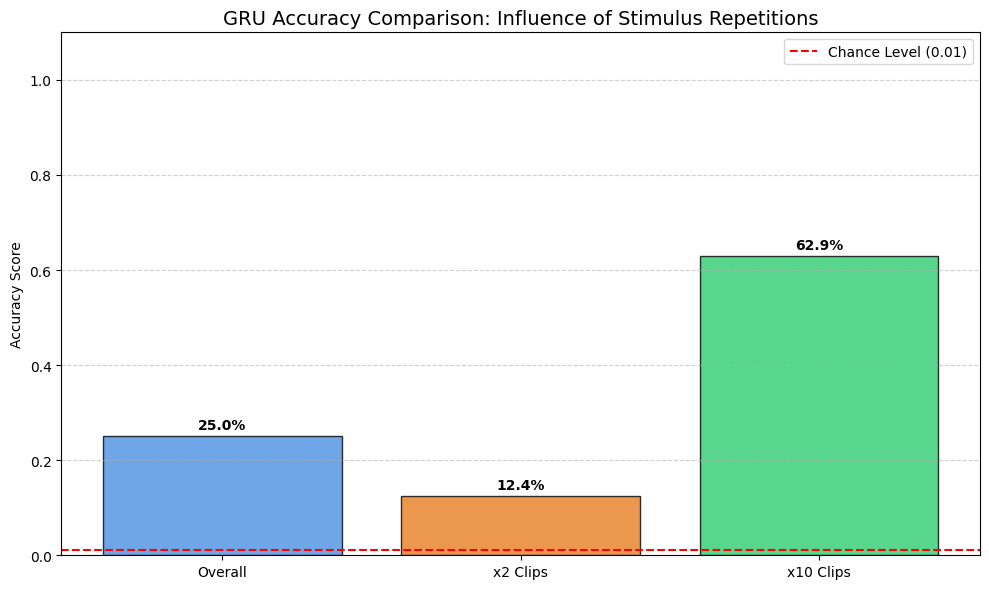

In [267]:
import copy
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# ============================================================
# Reproducibility seeding (PyTorch + NumPy)
# ============================================================
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)
if torch.backends.mps.is_available():
    torch.mps.manual_seed(RANDOM_SEED)


# ============================================================
# STEP 1 — Load temporal clip dataset
# ============================================================
data = np.load("dataset_clip_temporal.npz", allow_pickle=True)
X_train = data["X_train"].astype(np.float32)
X_test  = data["X_test"].astype(np.float32)
y_train = data["y_train"].astype(np.int64)
y_test  = data["y_test"].astype(np.int64)
class_labels = data["class_labels"]
clip_ids = data["clip_ids"]
n_reps   = data["n_reps"]

n_classes = len(class_labels)
n_neurons = X_train.shape[2]

print("=" * 70)
print("GRU FOR SPECIFIC CLIP IDENTIFICATION")
print("=" * 70)
print(f"X_train: {X_train.shape}")
print(f"X_test:  {X_test.shape}")
print(f"Classes: {n_classes}")
print(f"Baseline random: {1/n_classes:.4f} ({100/n_classes:.2f}%)")

# ============================================================
# STEP 2 — PyTorch dataloaders
# ============================================================
X_train_t = torch.tensor(X_train)
y_train_t = torch.tensor(y_train)
X_test_t  = torch.tensor(X_test)
y_test_t  = torch.tensor(y_test)

train_dataset = TensorDataset(X_train_t, y_train_t)
test_dataset  = TensorDataset(X_test_t, y_test_t)

train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
test_loader  = DataLoader(test_dataset, batch_size=64, shuffle=False)

# ============================================================
# STEP 3 — GRU model
# ============================================================
class ClipTemporalGRU(nn.Module):
    def __init__(self, n_neurons, proj_dim, hidden_dim, n_layers, n_classes, dropout=0.3):
        super().__init__()
        self.projection = nn.Linear(n_neurons, proj_dim)
        self.gru = nn.GRU(
            input_size=proj_dim,
            hidden_size=hidden_dim,
            num_layers=n_layers,
            batch_first=True,
            dropout=dropout if n_layers > 1 else 0.0
        )
        self.dropout = nn.Dropout(dropout)
        self.classifier = nn.Linear(hidden_dim, n_classes)

    def forward(self, x):
        x = self.projection(x)
        _, h_n = self.gru(x)
        out = h_n[-1]
        out = self.dropout(out)
        return self.classifier(out)

# ============================================================
# STEP 4 — Model, optimizer, scheduler
# ============================================================
device = torch.device(
    "cuda" if torch.cuda.is_available() else
    "mps" if torch.backends.mps.is_available() else
    "cpu"
)
print(f"Using device: {device}")

model = ClipTemporalGRU(
    n_neurons=n_neurons,
    proj_dim=64,
    hidden_dim=64,
    n_layers=1,
    n_classes=n_classes,
    dropout=0.3
).to(device)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode="min", patience=5, factor=0.5
)

# ============================================================
# STEP 5 — Training loop with early stopping
# ============================================================
N_EPOCHS = 100
PATIENCE = 15

train_losses, val_losses = [], []
train_accs, val_accs = [], []
best_val_loss = float("inf")
epochs_without_improvement = 0
best_model_state = None

print("\n" + "=" * 70)
print("TRAINING CLIP GRU")
print("=" * 70)

for epoch in range(N_EPOCHS):
    model.train()
    running_loss, correct, total = 0.0, 0, 0
    for X_batch, y_batch in train_loader:
        X_batch, y_batch = X_batch.to(device), y_batch.to(device)
        optimizer.zero_grad()
        logits = model(X_batch)
        loss = criterion(logits, y_batch)
        loss.backward()
        optimizer.step()
        running_loss += loss.item() * X_batch.size(0)
        preds = logits.argmax(dim=1)
        correct += (preds == y_batch).sum().item()
        total += X_batch.size(0)

    train_loss, train_acc = running_loss / total, correct / total

    model.eval()
    val_running_loss, val_correct, val_total = 0.0, 0, 0
    with torch.no_grad():
        for X_batch, y_batch in test_loader:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)
            logits = model(X_batch)
            loss = criterion(logits, y_batch)
            val_running_loss += loss.item() * X_batch.size(0)
            val_correct += (logits.argmax(dim=1) == y_batch).sum().item()
            val_total += X_batch.size(0)

    val_loss, val_acc = val_running_loss / val_total, val_correct / val_total
    train_losses.append(train_loss); val_losses.append(val_loss)
    train_accs.append(train_acc); val_accs.append(val_acc)

    scheduler.step(val_loss)
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_model_state = copy.deepcopy(model.state_dict())
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1

    if (epoch + 1) % 10 == 0:
        print(f"Epoch {epoch+1:3d}/{N_EPOCHS} | Val Loss: {val_loss:.4f} Acc: {val_acc:.4f}")

    if epochs_without_improvement >= PATIENCE:
        print(f"Early stopping at epoch {epoch+1}")
        break

model.load_state_dict(best_model_state)

# ============================================================
# STEP 6 — Final evaluation
# ============================================================
model.eval()
all_preds, all_labels = [], []
with torch.no_grad():
    for X_batch, y_batch in test_loader:
        X_batch = X_batch.to(device)
        preds = model(X_batch).argmax(dim=1).cpu().numpy()
        all_preds.extend(preds)
        all_labels.extend(y_batch.numpy())

all_preds, all_labels = np.array(all_preds), np.array(all_labels)

acc_gru = accuracy_score(all_labels, all_preds)
f1_gru = f1_score(all_labels, all_preds, average="weighted")

labels_x2 = [i for i, reps in enumerate(n_reps) if reps == 2]
labels_x10 = [i for i, reps in enumerate(n_reps) if reps == 10]

def accuracy_by_group(y_true, y_pred, labels_subset):
    mask = np.isin(y_true, labels_subset)
    return accuracy_score(y_true[mask], y_pred[mask]) if mask.sum() > 0 else 0.0

acc_x2 = accuracy_by_group(all_labels, all_preds, labels_x2)
acc_x10 = accuracy_by_group(all_labels, all_preds, labels_x10)

print("\n" + "=" * 70)
print("FINAL RESULTS — CLIP GRU")
print("=" * 70)
print(f"Overall:    {acc_gru:.4f}")
print(f"x2 clips:    {acc_x2:.4f}")
print(f"x10 clips:   {acc_x10:.4f}")
print("Classification report:")
print(classification_report(all_labels, all_preds, target_names=class_labels, zero_division=0))

# ============================================================
# STEP 7 — Accuracy Comparison Plot (Overall vs x2 vs x10)
# ============================================================
plt.figure(figsize=(10, 6))
categories = ['Overall', 'x2 Clips', 'x10 Clips']
accuracies = [acc_gru, acc_x2, acc_x10]
colors = ['#4a90e2', '#e67e22', '#2ecc71'] # Blue, Orange, Green

bars = plt.bar(categories, accuracies, color=colors, edgecolor='black', alpha=0.8)
plt.axhline(y=1/n_classes, color='red', linestyle='--', label=f'Chance Level ({1/n_classes:.2f})')

# Add percentage text on top of bars
for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2., height + 0.01,
             f'{height*100:.1f}%', ha='center', va='bottom', fontweight='bold')

plt.title('GRU Accuracy Comparison: Influence of Stimulus Repetitions', fontsize=14)
plt.ylabel('Accuracy Score')
plt.ylim(0, 1.1)
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

X_test_sc : (840, 10, 5312)
y_test    : (840,)
x2 clips  : 90   x10 clips: 6
Shapes match

Computing saliency...
   Gradient shape: (840, 10, 5312)  


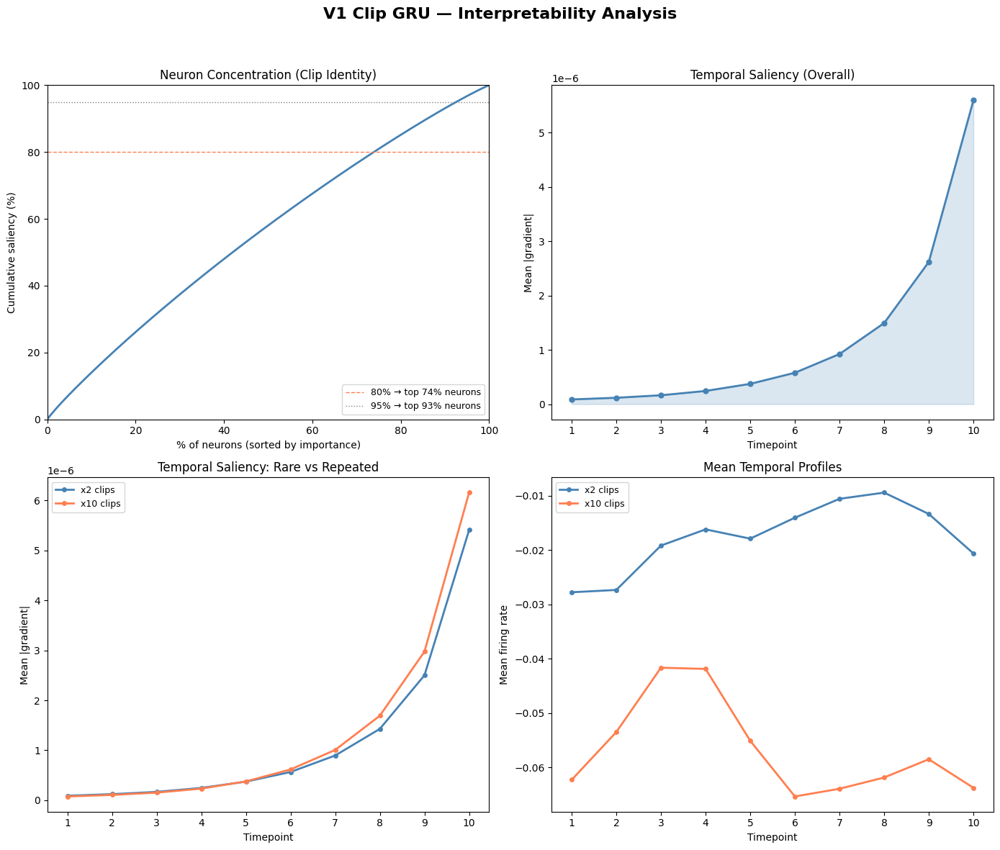


NEUROSCIENCE SUMMARY

Neuron concentration:
   80% of signal in top 73.9% of neurons
   95% of signal in top 92.6% of neurons
   → DISTRIBUTED

Temporal coding:
   Peak discriminative timepoint: t=10/10
   → Late window — recurrent/feedback

Temporal coding by rep group:
   x2  clips peak at t=10
   x10 clips peak at t=10
   → Similar temporal strategy regardless of repetitions


In [268]:
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.metrics import confusion_matrix, accuracy_score

# ============================================================
# RELOAD from disk — guarantees correct arrays are in memory
# ============================================================
data         = np.load("dataset_clip_temporal.npz", allow_pickle=True)
X_test_sc    = data["X_test"].astype(np.float32)
y_test       = data["y_test"].astype(np.int64)
X_train_sc   = data["X_train"].astype(np.float32)
y_train      = data["y_train"].astype(np.int64)
class_labels = data["class_labels"]
clip_ids     = data["clip_ids"]
n_reps       = data["n_reps"]

assert X_test_sc.shape[0] == y_test.shape[0], \
    f"Shape mismatch: {X_test_sc.shape[0]} windows vs {y_test.shape[0]} labels"

n_classes      = len(class_labels)
timepoints     = np.arange(1, X_test_sc.shape[1] + 1)
labels_x2_idx  = [i for i, r in enumerate(n_reps) if r == 2]
labels_x10_idx = [i for i, r in enumerate(n_reps) if r == 10]

print(f"X_test_sc : {X_test_sc.shape}")
print(f"y_test    : {y_test.shape}")
print(f"x2 clips  : {len(labels_x2_idx)}   x10 clips: {len(labels_x10_idx)}")
print("Shapes match")

# ============================================================
# ANALYSIS 1 & 2 — Neuron + temporal saliency
# ============================================================
print("\nComputing saliency...")

model.train()
X_sal = torch.tensor(X_test_sc).to(device)
X_sal.requires_grad_(True)
y_sal = torch.tensor(y_test).to(device)

nn.CrossEntropyLoss()(model(X_sal), y_sal).backward()

assert X_sal.grad is not None, "Gradient is None — check model"
grads     = X_sal.grad.detach().cpu().numpy()   # (n_samples, T, n_neurons)
model.eval()

abs_grads               = np.abs(grads)
neuron_sal_per_sample   = abs_grads.mean(axis=1)   # (n_samples, n_neurons)
temporal_sal_per_sample = abs_grads.mean(axis=2)   # (n_samples, T)
neuron_importance       = neuron_sal_per_sample.mean(axis=0)
temporal_importance     = temporal_sal_per_sample.mean(axis=0)

def group_sal(sal_per_sample, label_indices):
    mask = np.isin(y_test, label_indices)
    return sal_per_sample[mask].mean(axis=0)

neuron_imp_x2    = group_sal(neuron_sal_per_sample,   labels_x2_idx)
neuron_imp_x10   = group_sal(neuron_sal_per_sample,   labels_x10_idx)
temporal_imp_x2  = group_sal(temporal_sal_per_sample, labels_x2_idx)
temporal_imp_x10 = group_sal(temporal_sal_per_sample, labels_x10_idx)

print(f"   Gradient shape: {grads.shape}  ")

# ============================================================
# ANALYSIS 4 — Temporal response profiles per rep group
# ============================================================
def temporal_profile(label_indices):
    mask = np.isin(y_test, label_indices)
    return X_test_sc[mask].mean(axis=0).mean(axis=1)   # (T,)

profile_x2  = temporal_profile(labels_x2_idx)
profile_x10 = temporal_profile(labels_x10_idx)


# ============================================================
# PLOTS — Updated to 2x2 Grid
# ============================================================
fig = plt.figure(figsize=(14, 12)) # Dimensioni ridotte per 2x2
fig.suptitle("V1 Clip GRU — Interpretability Analysis",
             fontsize=16, fontweight="bold", y=0.98)

# ── 1: Cumulative saliency (Top Left) ──────────────────────
ax1 = fig.add_subplot(2, 2, 1)
sorted_imp = np.sort(neuron_importance)[::-1]
cumulative = np.cumsum(sorted_imp) / np.sum(sorted_imp)
n_total    = len(neuron_importance)
ax1.plot(np.arange(1, n_total + 1) / n_total * 100,
         cumulative * 100, color="steelblue", linewidth=2)
for thresh, color, ls in [(80, "coral", "--"), (95, "gray", ":")]:
    n_needed = np.searchsorted(cumulative, thresh / 100) + 1
    ax1.axhline(thresh, color=color, linestyle=ls, linewidth=1,
                label=f"{thresh}% → top {n_needed/n_total*100:.0f}% neurons")
ax1.set_xlabel("% of neurons (sorted by importance)")
ax1.set_ylabel("Cumulative saliency (%)")
ax1.set_title("Neuron Concentration (Clip Identity)")
ax1.legend(fontsize=9)
ax1.set_xlim(0, 100); ax1.set_ylim(0, 100)

# ── 2: Overall temporal importance (Top Right) ─────────────
ax2 = fig.add_subplot(2, 2, 2)
ax2.plot(timepoints, temporal_importance,
         color="steelblue", linewidth=2, marker="o", markersize=5)
ax2.fill_between(timepoints, temporal_importance,
                 alpha=0.2, color="steelblue")
ax2.set_xlabel("Timepoint")
ax2.set_ylabel("Mean |gradient|")
ax2.set_title("Temporal Saliency (Overall)")
ax2.set_xticks(timepoints)

# ── 3: Temporal importance x2 vs x10 (Bottom Left) ─────────
ax3 = fig.add_subplot(2, 2, 3)
ax3.plot(timepoints, temporal_imp_x2,  label="x2 clips",
         color="steelblue", linewidth=2, marker="o", markersize=4)
ax3.plot(timepoints, temporal_imp_x10, label="x10 clips",
         color="coral",     linewidth=2, marker="o", markersize=4)
ax3.set_xlabel("Timepoint")
ax3.set_ylabel("Mean |gradient|")
ax3.set_title("Temporal Saliency: Rare vs Repeated")
ax3.set_xticks(timepoints)
ax3.legend(fontsize=9)

# ── 4: Temporal response profiles x2 vs x10 (Bottom Right) ──
ax4 = fig.add_subplot(2, 2, 4)
ax4.plot(timepoints, profile_x2,  label="x2 clips",
         color="steelblue", linewidth=2, marker="o", markersize=4)
ax4.plot(timepoints, profile_x10, label="x10 clips",
         color="coral",     linewidth=2, marker="o", markersize=4)
ax4.set_xlabel("Timepoint")
ax4.set_ylabel("Mean firing rate")
ax4.set_title("Mean Temporal Profiles")
ax4.set_xticks(timepoints)
ax4.legend(fontsize=9)

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.savefig("v1_clip_gru_interpretability_2x2.png", dpi=150, bbox_inches="tight")
plt.show()

# ============================================================
# Summary
# ============================================================
p80    = (np.searchsorted(cumulative, 0.80) + 1) / n_total * 100
p95    = (np.searchsorted(cumulative, 0.95) + 1) / n_total * 100
peak_t = np.argmax(temporal_importance) + 1

print("\n" + "=" * 60)
print("NEUROSCIENCE SUMMARY")
print("=" * 60)

print(f"\nNeuron concentration:")
print(f"   80% of signal in top {p80:.1f}% of neurons")
print(f"   95% of signal in top {p95:.1f}% of neurons")
print("   → CONCENTRATED" if p80 < 20 else "   → DISTRIBUTED")

print(f"\nTemporal coding:")
print(f"   Peak discriminative timepoint: t={peak_t}/{len(timepoints)}")
if peak_t <= 3:
    print("   → Early window — feedforward")
elif peak_t >= 8:
    print("   → Late window — recurrent/feedback")
else:
    print("   → Mid-window — mixed")

peak_x2  = np.argmax(temporal_imp_x2)  + 1
peak_x10 = np.argmax(temporal_imp_x10) + 1
print(f"\nTemporal coding by rep group:")
print(f"   x2  clips peak at t={peak_x2}")
print(f"   x10 clips peak at t={peak_x10}")
if abs(peak_x2 - peak_x10) >= 2:
    print("   → Different temporal strategies for rare vs repeated clips")
else:
    print("   → Similar temporal strategy regardless of repetitions") 

### Results

**V1 temporal activity decodes clip identity well above the 1.04% chance baseline:** overall accuracy **0.2500** (weighted F1 = **0.2224**), about **24× chance**. The model fits the training set rapidly (training accuracy 0.9881 by epoch 10, 1.0000 by epoch 20) but validation accuracy plateaus around 25% with early stopping at epoch 24, indicating that the 96-class generalization problem is intrinsically difficult — not a training-time issue.

**The repetition effect is the single most informative finding.** Accuracy decomposes into:
- **×2 clips (1 train rep):** **0.1238** — already 12× chance, but variable.
- **×10 clips (5 train reps):** **0.6286** — about **5× higher** than ×2.

This mirrors Part 1.2: a single presentation does not produce a population template stable enough to generalize from, while five repetitions average out trial-to-trial noise enough that exact clip identity becomes recoverable. Per-clip accuracy confirms this — ×2: mean 0.1238, std 0.2266; ×10: mean 0.6286, std 0.0404 — meaning ×10 clips are not only decoded more accurately but also **more consistently** across clips.

**Comparison with the static V1 model of Part 1.2.** Static LR reached 0.2364, RF 0.1511; the temporal GRU at 0.2500 yields a small but real **+1.4 pp gain over the best static classifier**, much smaller than the +6.4 pp gain seen for stimulus type. With the full V1 population, a static snapshot already carries most of the recoverable clip-identity information; short-window temporal dynamics add little on top.

**Saliency analysis points to a distributed code.** 80% of the signal in the top **73.9%** of neurons, 95% in the top **92.6%** — clip identity is encoded across the V1 population rather than in a sparse subset. Temporal saliency peaks at the **last timepoint (t = 10/10)** for *both* repetition groups (×2 peak t = 10, ×10 peak t = 10), so the model uses **the same late-window strategy regardless of repetition count** — even though performance differs by ≈5×. 

Together: V1 contains substantial temporal information about exact clip identity, the code is distributed across many neurons, and repeated clips are much easier to decode despite the model relying on a similar temporal strategy for both repetition groups.

### 2.2.2: Cross-area Clip GRU on 387 neurons (30 random subsamples per area)


#### Multi-area temporal dataset construction — clip identity

### Rationale and Experimental Design

This subsection extends the V1 clip-identification analysis of 2.2.1 to a **fair cross-area comparison** across **V1, LM, AL, RL**, mirroring exactly the cross-area design of Part 1.2 (and of 2.1.2 above).

---

### Cross-Area Equalization via Random Subsampling

All four areas are matched to **N = 387 neurons** (the size of AL). For each area, **30 independent neuron seeds** generate 30 matched 387-neuron subsamples; AL has zero neuron-subsampling variance by construction.

The raw full-neuron window shapes per area are:
- **V1:** `(840, 10, 5312)`
- **LM:** `(840, 10, 983)`
- **AL:** `(840, 10, 387)`
- **RL:** `(840, 10, 811)`

After subsampling, every seed in every area uses the same matched temporal input size **(840, 10, 387)** for both training and testing.

---

### Train/Test Split

Identical to 2.2.1: ×2 clips contribute rep 1 → train, rep 2 → test; ×10 clips contribute reps 1–5 → train, reps 6–10 → test. The split is shared across areas and seeds, so cross-area differences cannot be driven by different stimuli being assigned to train or test.

---

### Implementation

To avoid 30× redundant disk reads, the full-neuron windows are loaded **once per area**; each seed then applies its own neuron subsample and train-only standardization in memory. The resulting datasets are saved as:

- `dataset_clip_temporal_V1_multiSeed.npz`
- `dataset_clip_temporal_LM_multiSeed.npz`
- `dataset_clip_temporal_AL_multiSeed.npz`
- `dataset_clip_temporal_RL_multiSeed.npz`

---

### Chance Baseline

**0.0104 (1.04%)** for 96 classes.

In [269]:
from collections import Counter
from sklearn.preprocessing import StandardScaler
import numpy as np

# ============================================================
# SETUP
# ============================================================
WINDOW_SIZE  = 10
STEP_SIZE    = 10
AREAS        = ["V1", "LM", "AL", "RL"]
RANDOM_SEED  = 42
N_SEEDS      = 30
np.random.seed(RANDOM_SEED)

print("=" * 70)
print(f"CLIP IDENTIFICATION DATASET — ALL AREAS ({N_SEEDS} NEURON SEEDS)")
print("=" * 70)

# ============================================================
# STEP 1 — Clip repetition structure (area-independent)
# ============================================================
hash_counts = Counter(clip_hashes)
clips_x2    = [h for h, c in hash_counts.items() if c == 2]
clips_x10   = [h for h, c in hash_counts.items() if c == 10]

print(f"Clip x2:  {len(clips_x2)}")
print(f"Clip x10: {len(clips_x10)}")
print(f"Total classes: {len(clips_x2) + len(clips_x10)}")

occurrence_indices = {}
for idx, h in enumerate(clip_hashes):
    occurrence_indices.setdefault(h, []).append(idx)

all_pairs     = [(h, 2)  for h in clips_x2] + [(h, 10) for h in clips_x10]
clip_to_label = {h: i for i, (h, _) in enumerate(all_pairs)}
class_labels  = [f"Clip_{i}" for i in range(len(all_pairs))]
n_classes     = len(all_pairs)

# ============================================================
# STEP 2 — Probe neuron counts per area
# ============================================================
def get_n_neurons(funcreader, area, probe_hash):
    r = funcreader.get_responses_by_hash(probe_hash, area)[0]
    return r["responses"].shape[0]

probe_hash    = clips_x2[0] if clips_x2 else clips_x10[0]
neuron_counts = {}
for area in AREAS:
    try:
        neuron_counts[area] = get_n_neurons(funcreader, area, probe_hash)
        print(f"   {area}: {neuron_counts[area]} neurons")
    except Exception as e:
        print(f"   {area}: probe failed — {e}")

N_NEURONS_SUBSAMPLE = min(neuron_counts.values())
print(f"\n→ Subsampling all areas to {N_NEURONS_SUBSAMPLE} neurons")
print(f"→ Generating {N_SEEDS} independent neuron samples per area")

# ============================================================
# STEP 3 — Generate N_SEEDS neuron index sets per area
#           Each seed gets its own RNG so draws are independent
# ============================================================
# neuron_index_sets[area] = list of N_SEEDS index arrays
neuron_index_sets = {}
for area in AREAS:
    seeds_for_area = []
    for seed_idx in range(N_SEEDS):
        # Unique seed per (area, seed_idx) — fully reproducible
        rng = np.random.default_rng(seed=RANDOM_SEED * 100 + seed_idx)
        idx = np.sort(rng.choice(neuron_counts[area],
                                 size=N_NEURONS_SUBSAMPLE,
                                 replace=False))
        seeds_for_area.append(idx)
    neuron_index_sets[area] = seeds_for_area
    print(f"   {area}: {N_SEEDS} neuron subsets ready")

# ============================================================
# STEP 4 — Windowed extraction helper
# ============================================================
def extract_windows(funcreader, hash_val, repeat_idx, area,
                    window_size, step_size, neuron_idx=None):
    r         = funcreader.get_responses_by_hash(hash_val, area)[repeat_idx]
    responses = r["responses"].T                     # (n_timepoints, n_neurons)
    if neuron_idx is not None:
        responses = responses[:, neuron_idx]
    windows = []
    for start in range(0, responses.shape[0] - window_size + 1, step_size):
        windows.append(responses[start:start + window_size, :])
    return np.stack(windows)                         # (n_windows, T, n_sub)

# ============================================================
# STEP 5 — Build raw (unscaled) windows once per area,
#           then apply per-seed neuron selection + scaling.
#           This avoids re-calling funcreader 30× per clip.
# ============================================================
def build_raw_windows_for_area(area):
    """Returns X_train_full, X_test_full (all neurons), y_train, y_test."""
    X_tr, y_tr, X_te, y_te = [], [], [], []

    for h in clips_x2:
        label = clip_to_label[h]
        for local_idx in range(2):
            w = extract_windows(funcreader, h, local_idx, area,
                                WINDOW_SIZE, STEP_SIZE, neuron_idx=None)
            if local_idx == 0:
                X_tr.append(w); y_tr.extend([label] * w.shape[0])
            else:
                X_te.append(w); y_te.extend([label] * w.shape[0])

    for h in clips_x10:
        label = clip_to_label[h]
        for local_idx in range(10):
            w = extract_windows(funcreader, h, local_idx, area,
                                WINDOW_SIZE, STEP_SIZE, neuron_idx=None)
            if local_idx < 5:
                X_tr.append(w); y_tr.extend([label] * w.shape[0])
            else:
                X_te.append(w); y_te.extend([label] * w.shape[0])

    X_train = np.nan_to_num(np.vstack(X_tr).astype(np.float64),
                            nan=0.0, posinf=0.0, neginf=0.0)
    X_test  = np.nan_to_num(np.vstack(X_te).astype(np.float64),
                            nan=0.0, posinf=0.0, neginf=0.0)
    return X_train, X_test, np.array(y_tr, dtype=np.int64), np.array(y_te, dtype=np.int64)


# clip_area_datasets[area][seed_idx] = dict with X_train, X_test, y_train, y_test
clip_area_datasets = {area: [] for area in AREAS}

for area in AREAS:
    print(f"\n{'='*70}")
    print(f"Building datasets — {area}  ({N_SEEDS} seeds)")
    print(f"{'='*70}")

    # Load full-neuron windows once
    print("   Loading full-neuron windows...", end=" ", flush=True)
    X_train_full, X_test_full, y_train, y_test = build_raw_windows_for_area(area)
    print(f"done  {X_train_full.shape}")

    n_train, T, N_full = X_train_full.shape
    n_test             = X_test_full.shape[0]

    for seed_idx, neuron_idx in enumerate(neuron_index_sets[area]):

        # Subsample neurons
        X_tr = X_train_full[:, :, neuron_idx]   
        X_te = X_test_full[:,  :, neuron_idx]

        # Normalize (fit on train only)
        scaler = StandardScaler()
        X_tr_sc = scaler.fit_transform(
            X_tr.reshape(-1, N_NEURONS_SUBSAMPLE)
        ).reshape(n_train, T, N_NEURONS_SUBSAMPLE)
        X_te_sc = scaler.transform(
            X_te.reshape(-1, N_NEURONS_SUBSAMPLE)
        ).reshape(n_test, T, N_NEURONS_SUBSAMPLE)

        clip_area_datasets[area].append({
            "X_train":        X_tr_sc,
            "X_test":         X_te_sc,
            "y_train":        y_train,
            "y_test":         y_test,
            "class_labels":   np.array(class_labels, dtype=object),
            "n_reps":         np.array([n for _, n in all_pairs]),
            "clip_ids":       np.array([h for h, _ in all_pairs]),
            "n_neurons_used": N_NEURONS_SUBSAMPLE,
            "seed_idx":       seed_idx,
            "neuron_indices": neuron_idx,
        })

    print(f" {N_SEEDS} seeded datasets ready for {area}")

    # Save all seeds for this area in one file
    save_dict = {"y_train": y_train, "y_test": y_test,
                 "class_labels": np.array(class_labels, dtype=object),
                 "n_reps": np.array([n for _, n in all_pairs]),
                 "clip_ids": np.array([h for h, _ in all_pairs]),
                 "n_neurons_subsample": N_NEURONS_SUBSAMPLE}
    for seed_idx in range(N_SEEDS):
        d = clip_area_datasets[area][seed_idx]
        save_dict[f"X_train_seed{seed_idx}"] = d["X_train"]
        save_dict[f"X_test_seed{seed_idx}"]  = d["X_test"]
        save_dict[f"neuron_idx_seed{seed_idx}"] = d["neuron_indices"]
    np.savez(f"dataset_clip_temporal_{area}_multiSeed.npz", **save_dict)
    print(f"   Saved → dataset_clip_temporal_{area}_multiSeed.npz")

print(f"\n{'='*70}")
print(f"All areas · {N_NEURONS_SUBSAMPLE} neurons · {N_SEEDS} seeds — ready ")
print(f"{'='*70}")

CLIP IDENTIFICATION DATASET — ALL AREAS (30 NEURON SEEDS)
Clip x2:  90
Clip x10: 6
Total classes: 96
   V1: 5312 neurons
   LM: 983 neurons
   AL: 387 neurons
   RL: 811 neurons

→ Subsampling all areas to 387 neurons
→ Generating 30 independent neuron samples per area
   V1: 30 neuron subsets ready
   LM: 30 neuron subsets ready
   AL: 30 neuron subsets ready
   RL: 30 neuron subsets ready

Building datasets — V1  (30 seeds)
   Loading full-neuron windows... done  (840, 10, 5312)
 30 seeded datasets ready for V1
   Saved → dataset_clip_temporal_V1_multiSeed.npz

Building datasets — LM  (30 seeds)
   Loading full-neuron windows... done  (840, 10, 983)
 30 seeded datasets ready for LM
   Saved → dataset_clip_temporal_LM_multiSeed.npz

Building datasets — AL  (30 seeds)
   Loading full-neuron windows... done  (840, 10, 387)
 30 seeded datasets ready for AL
   Saved → dataset_clip_temporal_AL_multiSeed.npz

Building datasets — RL  (30 seeds)
   Loading full-neuron windows... done  (840, 1

#### Multi-area GRU training — clip identity

### Model and Training

The same GRU architecture as 2.2.1 (linear projection 387 → 64, GRU hidden 64, dropout 0.3, linear head → 96 classes), trained with Adam, learning-rate scheduler and early stopping. **30 seeds × 4 areas = 120 trained models.** Per-seed metrics are aggregated as mean ± std.

For each model we report:
- overall accuracy
- weighted F1
- accuracy on **×2 clips** (1 rep in train)
- accuracy on **×10 clips** (5 reps in train)

Using device: mps


   ── V1 summary ──
   Acc:    0.1510 ± 0.0094
   F1:     0.0890 ± 0.0087
   x2:     0.0201 ± 0.0066
   x10:    0.5438 ± 0.0323
   Chance: 0.0104

   ── LM summary ──
   Acc:    0.1599 ± 0.0113
   F1:     0.0972 ± 0.0124
   x2:     0.0304 ± 0.0095
   x10:    0.5483 ± 0.0299
   Chance: 0.0104

   ── AL summary ──
   Acc:    0.1450 ± 0.0079
   F1:     0.0830 ± 0.0080
   x2:     0.0169 ± 0.0055
   x10:    0.5292 ± 0.0282
   Chance: 0.0104

   ── RL summary ──
   Acc:    0.1369 ± 0.0158
   F1:     0.0818 ± 0.0108
   x2:     0.0183 ± 0.0070
   x10:    0.4927 ± 0.0513
   Chance: 0.0104


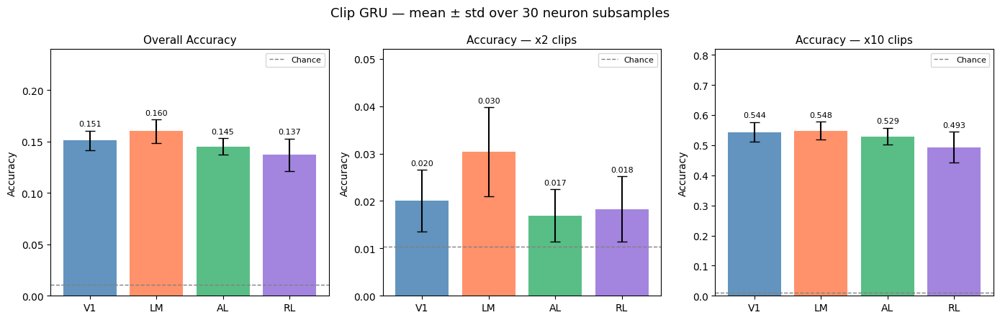


Area       Acc (mean±std)               x2              x10  vs chance
V1     0.1510 ± 0.0094   0.0201 ± 0.0066   0.5438 ± 0.0323   +14.1pp
LM     0.1599 ± 0.0113   0.0304 ± 0.0095   0.5483 ± 0.0299   +14.9pp
AL     0.1450 ± 0.0079   0.0169 ± 0.0055   0.5292 ± 0.0282   +13.5pp
RL     0.1369 ± 0.0158   0.0183 ± 0.0070   0.4927 ± 0.0513   +12.6pp


In [270]:
import copy
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# ============================================================
# Model definition (unchanged)
# ============================================================
class ClipTemporalGRU(nn.Module):
    def __init__(self, n_neurons, proj_dim, hidden_dim,
                 n_layers, n_classes, dropout=0.3):
        super().__init__()
        self.projection = nn.Linear(n_neurons, proj_dim)
        self.gru = nn.GRU(input_size=proj_dim, hidden_size=hidden_dim,
                          num_layers=n_layers, batch_first=True,
                          dropout=dropout if n_layers > 1 else 0.0)
        self.dropout    = nn.Dropout(dropout)
        self.classifier = nn.Linear(hidden_dim, n_classes)

    def forward(self, x):
        x      = self.projection(x)
        _, h_n = self.gru(x)
        return self.classifier(self.dropout(h_n[-1]))


# ============================================================
# Single-seed training (returns scalar metrics only)
# ============================================================
def train_one_seed(dataset, device, n_classes,
                   proj_dim=64, hidden_dim=64, n_layers=1, dropout=0.3,
                   lr=1e-3, weight_decay=1e-4,
                   n_epochs=100, patience=15, batch_size=64):

    X_train = torch.tensor(dataset["X_train"].astype(np.float32))
    y_train = torch.tensor(dataset["y_train"])
    X_test  = torch.tensor(dataset["X_test"].astype(np.float32))
    y_test  = torch.tensor(dataset["y_test"])
    n_reps  = dataset["n_reps"]

    n_neurons = X_train.shape[2]

    train_loader = DataLoader(TensorDataset(X_train, y_train),
                              batch_size=batch_size, shuffle=True)
    test_loader  = DataLoader(TensorDataset(X_test, y_test),
                              batch_size=batch_size, shuffle=False)

    model = ClipTemporalGRU(n_neurons, proj_dim, hidden_dim,
                            n_layers, n_classes, dropout).to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode="min", patience=5, factor=0.5)

    best_val_loss, best_state, no_improve = float("inf"), None, 0

    for epoch in range(n_epochs):
        model.train()
        for Xb, yb in train_loader:
            Xb, yb = Xb.to(device), yb.to(device)
            optimizer.zero_grad()
            loss = criterion(model(Xb), yb)
            loss.backward()
            optimizer.step()

        model.eval()
        v_loss, v_correct, v_total = 0.0, 0, 0
        with torch.no_grad():
            for Xb, yb in test_loader:
                Xb, yb = Xb.to(device), yb.to(device)
                logits  = model(Xb)
                v_loss += criterion(logits, yb).item() * Xb.size(0)
                v_correct += (logits.argmax(1) == yb).sum().item()
                v_total   += Xb.size(0)
        val_loss = v_loss / v_total
        scheduler.step(val_loss)

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_state    = copy.deepcopy(model.state_dict())
            no_improve    = 0
        else:
            no_improve += 1
        if no_improve >= patience:
            break

    model.load_state_dict(best_state)
    model.eval()
    all_preds, all_labels = [], []
    with torch.no_grad():
        for Xb, yb in test_loader:
            all_preds.extend(model(Xb.to(device)).argmax(1).cpu().numpy())
            all_labels.extend(yb.numpy())

    all_preds  = np.array(all_preds)
    all_labels = np.array(all_labels)

    labels_x2_idx  = [i for i, r in enumerate(n_reps) if r == 2]
    labels_x10_idx = [i for i, r in enumerate(n_reps) if r == 10]

    def acc_group(y_true, y_pred, subset):
        mask = np.isin(y_true, subset)
        return accuracy_score(y_true[mask], y_pred[mask]) if mask.sum() > 0 else 0.0

    return {
        "acc":     accuracy_score(all_labels, all_preds),
        "f1":      f1_score(all_labels, all_preds, average="weighted"),
        "acc_x2":  acc_group(all_labels, all_preds, labels_x2_idx),
        "acc_x10": acc_group(all_labels, all_preds, labels_x10_idx),
        "preds":   all_preds,
        "labels":  all_labels,
    }


# ============================================================
# Multi-seed loop per area
# ============================================================
device = torch.device(
    "cuda" if torch.cuda.is_available() else
    "mps"  if torch.backends.mps.is_available() else
    "cpu"
)
print(f"Using device: {device}\n")

# aggregated_results[area] = {acc: [s0, s1, ...], f1: [...], ...}
aggregated_results = {}

for area in AREAS:

    seed_metrics = {"acc": [], "f1": [], "acc_x2": [], "acc_x10": []}
    all_seed_preds  = []   # collect per-seed prediction arrays for ensemble CM
    all_seed_labels = None

    n_classes = len(clip_area_datasets[area][0]["class_labels"])

    for seed_idx, dataset in enumerate(clip_area_datasets[area]):
        # Different torch seed per (area, seed_idx) so weight inits vary
        torch.manual_seed(RANDOM_SEED * 100 + seed_idx)

        metrics = train_one_seed(dataset, device, n_classes)

        seed_metrics["acc"].append(metrics["acc"])
        seed_metrics["f1"].append(metrics["f1"])
        seed_metrics["acc_x2"].append(metrics["acc_x2"])
        seed_metrics["acc_x10"].append(metrics["acc_x10"])
        all_seed_preds.append(metrics["preds"])
        all_seed_labels = metrics["labels"]   # same y_test every seed

      

    # Summary statistics across seeds
    aggregated_results[area] = {
        "mean_acc":     np.mean(seed_metrics["acc"]),
        "std_acc":      np.std(seed_metrics["acc"]),
        "mean_f1":      np.mean(seed_metrics["f1"]),
        "std_f1":       np.std(seed_metrics["f1"]),
        "mean_acc_x2":  np.mean(seed_metrics["acc_x2"]),
        "std_acc_x2":   np.std(seed_metrics["acc_x2"]),
        "mean_acc_x10": np.mean(seed_metrics["acc_x10"]),
        "std_acc_x10":  np.std(seed_metrics["acc_x10"]),
        "all_accs":     np.array(seed_metrics["acc"]),     # full distribution
        "seed_preds":   np.stack(all_seed_preds),          # (N_SEEDS, n_test)
        "labels":       all_seed_labels,
        "n_classes":    n_classes,
    }

    r = aggregated_results[area]
    print(f"\n   ── {area} summary ──")
    print(f"   Acc:    {r['mean_acc']:.4f} ± {r['std_acc']:.4f}")
    print(f"   F1:     {r['mean_f1']:.4f} ± {r['std_f1']:.4f}")
    print(f"   x2:     {r['mean_acc_x2']:.4f} ± {r['std_acc_x2']:.4f}")
    print(f"   x10:    {r['mean_acc_x10']:.4f} ± {r['std_acc_x10']:.4f}")
    print(f"   Chance: {1/n_classes:.4f}")


# ============================================================
# 1 — Bar chart with error bars (mean ± std across seeds)
# ============================================================
fig, axes = plt.subplots(1, 3, figsize=(14, 4.5))
fig.suptitle("Clip GRU — mean ± std over 30 neuron subsamples", fontsize=13)

metrics_to_plot = [
    ("mean_acc",     "std_acc",     "Overall Accuracy"),
    ("mean_acc_x2",  "std_acc_x2",  "Accuracy — x2 clips"),
    ("mean_acc_x10", "std_acc_x10", "Accuracy — x10 clips"),
]

colors = ["steelblue", "coral", "mediumseagreen", "mediumpurple"]

for ax, (mean_key, std_key, title) in zip(axes, metrics_to_plot):
    means = [aggregated_results[a][mean_key] for a in AREAS]
    stds  = [aggregated_results[a][std_key]  for a in AREAS]
    bars  = ax.bar(AREAS, means, yerr=stds, capsize=5,
                   color=colors, alpha=0.85,
                   error_kw={"linewidth": 1.5})
    chance = 1 / aggregated_results[AREAS[0]]["n_classes"]
    ax.axhline(chance, color="gray", linestyle="--", linewidth=1, label="Chance")
    ax.set_title(title, fontsize=11)
    ax.set_ylabel("Accuracy")
    ax.set_ylim(0, max(means) * 1.4 + max(stds))
    ax.legend(fontsize=8, loc="upper right")
    for bar, m, s in zip(bars, means, stds):
        ax.text(bar.get_x() + bar.get_width() / 2,
                bar.get_height() + s + (max(means) * 0.02),
                f"{m:.3f}", ha="center", va="bottom", fontsize=8)

plt.tight_layout()
plt.savefig("clip_gru_area_comparison_bar.png", dpi=150, bbox_inches="tight")
plt.show()


# ============================================================
# Summary table
# ============================================================
chance = 1 / aggregated_results[AREAS[0]]["n_classes"]
print("\n" + "=" * 75)
print(f"{'Area':<6} {'Acc (mean±std)':>18} {'x2':>16} {'x10':>16} {'vs chance':>10}")
print("=" * 75)
for area in AREAS:
    r = aggregated_results[area]
    print(f"{area:<6} "
          f"{r['mean_acc']:.4f} ± {r['std_acc']:.4f}   "
          f"{r['mean_acc_x2']:.4f} ± {r['std_acc_x2']:.4f}   "
          f"{r['mean_acc_x10']:.4f} ± {r['std_acc_x10']:.4f}   "
          f"+{(r['mean_acc']-chance)*100:.1f}pp")

Using device: mps


NEUROSCIENCE SUMMARY — CLIP IDENTIFICATION ACROSS AREAS

V1:
   Voted accuracy:         0.1857
   Peak discriminative t:  10/10  → recurrent/feedback-dominated
   x2 peak t=10  x10 peak t=10  → same strategy regardless of repetitions
   80% signal in top 78.0% neurons  → distributed
   95% signal in top 94.3% neurons

LM:
   Voted accuracy:         0.1905
   Peak discriminative t:  10/10  → recurrent/feedback-dominated
   x2 peak t=10  x10 peak t=10  → same strategy regardless of repetitions
   80% signal in top 78.3% neurons  → distributed
   95% signal in top 94.3% neurons

AL:
   Voted accuracy:         0.1595
   Peak discriminative t:  10/10  → recurrent/feedback-dominated
   x2 peak t=10  x10 peak t=10  → same strategy regardless of repetitions
   80% signal in top 74.4% neurons  → distributed
   95% signal in top 93.0% neurons

RL:
   Voted accuracy:         0.1738
   Peak discriminative t:  10/10  → recurrent/feedback-dominated
   x2 peak t=10  x10 peak t=10 

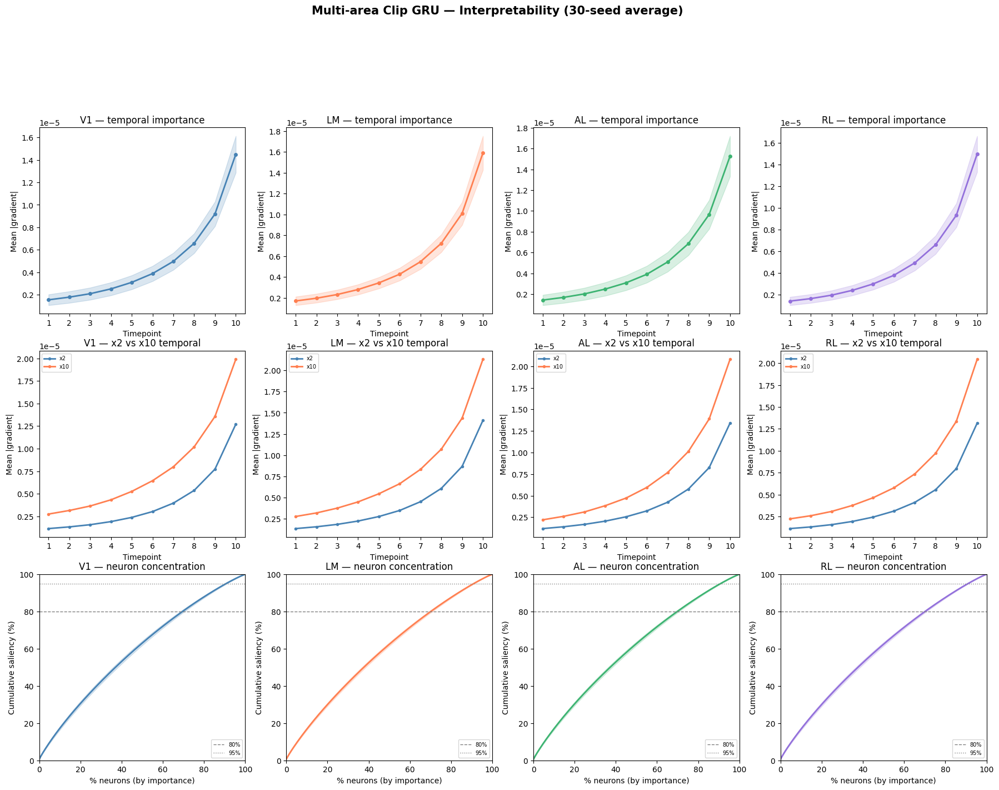

In [271]:
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.metrics import confusion_matrix, accuracy_score
import copy

# ============================================================
# SALIENCY FUNCTION — one seed at a time
# ============================================================
def compute_clip_saliency_for_seed(dataset, device,
                                    proj_dim=64, hidden_dim=64,
                                    n_layers=1, dropout=0.3):
    X_train   = torch.tensor(dataset["X_train"].astype(np.float32))
    y_train   = torch.tensor(dataset["y_train"])
    X_test    = torch.tensor(dataset["X_test"].astype(np.float32))
    y_test_t  = torch.tensor(dataset["y_test"])
    n_reps    = dataset["n_reps"]
    n_classes = len(dataset["class_labels"])
    n_neurons = X_train.shape[2]

    train_loader = torch.utils.data.DataLoader(
        torch.utils.data.TensorDataset(X_train, y_train),
        batch_size=64, shuffle=True)
    test_loader = torch.utils.data.DataLoader(
        torch.utils.data.TensorDataset(X_test, y_test_t),
        batch_size=64, shuffle=False)

    model = ClipTemporalGRU(n_neurons, proj_dim, hidden_dim,
                            n_layers, n_classes, dropout).to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-4)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode="min", patience=5, factor=0.5)

    best_val_loss, best_state, no_improve = float("inf"), None, 0
    for epoch in range(100):
        model.train()
        for Xb, yb in train_loader:
            Xb, yb = Xb.to(device), yb.to(device)
            optimizer.zero_grad()
            criterion(model(Xb), yb).backward()
            optimizer.step()
        model.eval()
        v_loss, v_total = 0.0, 0
        with torch.no_grad():
            for Xb, yb in test_loader:
                Xb, yb = Xb.to(device), yb.to(device)
                v_loss  += criterion(model(Xb), yb).item() * Xb.size(0)
                v_total += Xb.size(0)
        val_loss = v_loss / v_total
        scheduler.step(val_loss)
        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_state    = copy.deepcopy(model.state_dict())
            no_improve    = 0
        else:
            no_improve += 1
        if no_improve >= 15:
            break

    model.load_state_dict(best_state)

    # ── Saliency ──────────────────────────────────────────
    model.train()
    X_sal = X_test.to(device)
    X_sal.requires_grad_(True)
    criterion(model(X_sal), y_test_t.to(device)).backward()
    grads = X_sal.grad.detach().cpu().numpy()   # (n_samples, T, n_neurons)
    model.eval()

    abs_grads               = np.abs(grads)
    neuron_sal_per_sample   = abs_grads.mean(axis=1)   # (n_samples, n_neurons)
    temporal_sal_per_sample = abs_grads.mean(axis=2)   # (n_samples, T)

    y_np = dataset["y_test"]
    labels_x2_idx  = [i for i, r in enumerate(n_reps) if r == 2]
    labels_x10_idx = [i for i, r in enumerate(n_reps) if r == 10]

    def group_sal(sal, indices):
        mask = np.isin(y_np, indices)
        return sal[mask].mean(axis=0) if mask.sum() > 0 else np.zeros(sal.shape[1])

    # ── Predictions ───────────────────────────────────────
    all_preds = []
    with torch.no_grad():
        for Xb, _ in test_loader:
            all_preds.extend(model(Xb.to(device)).argmax(1).cpu().numpy())

    all_preds = np.array(all_preds)

    # Per-clip accuracy
    per_clip_acc = {}
    for label in range(n_classes):
        mask = y_np == label
        if mask.sum() > 0:
            per_clip_acc[label] = accuracy_score(y_np[mask], all_preds[mask])

    return {
        "neuron_importance":     neuron_sal_per_sample.mean(axis=0),
        "temporal_importance":   temporal_sal_per_sample.mean(axis=0),
        "neuron_imp_x2":         group_sal(neuron_sal_per_sample,   labels_x2_idx),
        "neuron_imp_x10":        group_sal(neuron_sal_per_sample,   labels_x10_idx),
        "temporal_imp_x2":       group_sal(temporal_sal_per_sample, labels_x2_idx),
        "temporal_imp_x10":      group_sal(temporal_sal_per_sample, labels_x10_idx),
        "preds":                 all_preds,
        "labels":                y_np,
        "per_clip_acc":          per_clip_acc,
        "labels_x2_idx":         labels_x2_idx,
        "labels_x10_idx":        labels_x10_idx,
    }


# ============================================================
# RUN — 30 seeds × 4 areas
# ============================================================
device = torch.device(
    "cuda" if torch.cuda.is_available() else
    "mps"  if torch.backends.mps.is_available() else
    "cpu"
)
print(f"Using device: {device}\n")

clip_saliency_results = {}

for area in AREAS:
    datasets  = clip_area_datasets[area]
    n_reps    = datasets[0]["n_reps"]
    n_classes = len(datasets[0]["class_labels"])
    T         = datasets[0]["X_train"].shape[1]
    n_neurons = datasets[0]["X_train"].shape[2]

    labels_x2_idx  = [i for i, r in enumerate(n_reps) if r == 2]
    labels_x10_idx = [i for i, r in enumerate(n_reps) if r == 10]

    seed_neuron_imp    = []
    seed_temporal_imp  = []
    seed_neuron_x2     = []
    seed_neuron_x10    = []
    seed_temporal_x2   = []
    seed_temporal_x10  = []
    seed_preds         = []
    seed_per_clip_acc  = {l: [] for l in range(n_classes)}
    seed_labels        = None

    for seed_idx, dataset in enumerate(datasets):
        torch.manual_seed(RANDOM_SEED * 100 + seed_idx)
        r = compute_clip_saliency_for_seed(dataset, device)

        seed_neuron_imp.append(r["neuron_importance"])
        seed_temporal_imp.append(r["temporal_importance"])
        seed_neuron_x2.append(r["neuron_imp_x2"])
        seed_neuron_x10.append(r["neuron_imp_x10"])
        seed_temporal_x2.append(r["temporal_imp_x2"])
        seed_temporal_x10.append(r["temporal_imp_x10"])
        seed_preds.append(r["preds"])
        for label, acc in r["per_clip_acc"].items():
            seed_per_clip_acc[label].append(acc)
        seed_labels = r["labels"]

        

    # Average per-clip accuracy across seeds
    mean_per_clip_acc = {l: np.mean(v) for l, v in seed_per_clip_acc.items() if v}
    acc_vals_x2  = [mean_per_clip_acc[l] for l in labels_x2_idx  if l in mean_per_clip_acc]
    acc_vals_x10 = [mean_per_clip_acc[l] for l in labels_x10_idx if l in mean_per_clip_acc]

    clip_saliency_results[area] = {
        "n_classes":          n_classes,
        "n_neurons":          n_neurons,
        "T":                  T,
        "labels_x2_idx":      labels_x2_idx,
        "labels_x10_idx":     labels_x10_idx,
        # mean/std over seeds
        "neuron_imp_mean":    np.mean(seed_neuron_imp,   axis=0),
        "neuron_imp_std":     np.std(seed_neuron_imp,    axis=0),
        "temporal_imp_mean":  np.mean(seed_temporal_imp, axis=0),
        "temporal_imp_std":   np.std(seed_temporal_imp,  axis=0),
        "neuron_x2_mean":     np.mean(seed_neuron_x2,    axis=0),
        "neuron_x10_mean":    np.mean(seed_neuron_x10,   axis=0),
        "temporal_x2_mean":   np.mean(seed_temporal_x2,  axis=0),
        "temporal_x10_mean":  np.mean(seed_temporal_x10, axis=0),
        # full distribution for cumulative plots
        "all_neuron_imp":     np.array(seed_neuron_imp),   # (N_SEEDS, n_neurons)
        # majority vote
        "majority_preds":     np.apply_along_axis(
            lambda x: np.bincount(x, minlength=n_classes).argmax(),
            axis=0, arr=np.stack(seed_preds)
        ),
        "labels":             seed_labels,
        "acc_vals_x2":        acc_vals_x2,
        "acc_vals_x10":       acc_vals_x10,
    }

# ============================================================
# PLOTS — per-area grid
# ============================================================
area_colors  = ["steelblue", "coral", "mediumseagreen", "mediumpurple"]
timepoints   = np.arange(1, clip_saliency_results[AREAS[0]]["T"] + 1)

fig = plt.figure(figsize=(22, 20))
fig.suptitle("Multi-area Clip GRU — Interpretability (30-seed average)",
             fontsize=15, fontweight="bold", y=0.99)

# ── Row 1: Overall temporal importance ────────────────────
for col, (area, a_color) in enumerate(zip(AREAS, area_colors)):
    ax   = fig.add_subplot(4, 4, col + 1)
    r    = clip_saliency_results[area]
    mean = r["temporal_imp_mean"]
    std  = r["temporal_imp_std"]
    ax.plot(timepoints, mean, color=a_color, linewidth=2, marker="o", markersize=4)
    ax.fill_between(timepoints, mean - std, mean + std,
                    alpha=0.2, color=a_color)
    ax.set_title(f"{area} — temporal importance")
    ax.set_xlabel("Timepoint")
    ax.set_ylabel("Mean |gradient|")
    ax.set_xticks(timepoints)

# ── Row 2: Temporal importance x2 vs x10 ─────────────────
for col, (area, a_color) in enumerate(zip(AREAS, area_colors)):
    ax = fig.add_subplot(4, 4, col + 5)
    r  = clip_saliency_results[area]
    ax.plot(timepoints, r["temporal_x2_mean"],  label="x2",
            color="steelblue", linewidth=2, marker="o", markersize=3)
    ax.plot(timepoints, r["temporal_x10_mean"], label="x10",
            color="coral",     linewidth=2, marker="o", markersize=3)
    ax.set_title(f"{area} — x2 vs x10 temporal")
    ax.set_xlabel("Timepoint")
    ax.set_ylabel("Mean |gradient|")
    ax.set_xticks(timepoints)
    ax.legend(fontsize=7)

# ── Row 3: Cumulative neuron saliency ─────────────────────
for col, (area, a_color) in enumerate(zip(AREAS, area_colors)):
    ax = fig.add_subplot(4, 4, col + 9)
    r  = clip_saliency_results[area]
    all_curves = []
    for seed_imp in r["all_neuron_imp"]:
        sorted_imp = np.sort(seed_imp)[::-1]
        cum = np.cumsum(sorted_imp) / np.sum(sorted_imp)
        all_curves.append(cum)
    mean_curve = np.mean(all_curves, axis=0)
    std_curve  = np.std(all_curves,  axis=0)
    x_axis = np.linspace(0, 100, len(mean_curve))
    ax.plot(x_axis, mean_curve * 100, color=a_color, linewidth=2)
    ax.fill_between(x_axis,
                    (mean_curve - std_curve) * 100,
                    (mean_curve + std_curve) * 100,
                    alpha=0.2, color=a_color)
    for thresh, ls in [(80, "--"), (95, ":")]:
        ax.axhline(thresh, color="gray", linestyle=ls, linewidth=1,
                   label=f"{thresh}%")
    ax.set_xlabel("% neurons (by importance)")
    ax.set_ylabel("Cumulative saliency (%)")
    ax.set_title(f"{area} — neuron concentration")
    ax.set_xlim(0, 100); ax.set_ylim(0, 100)
    ax.legend(fontsize=7)

# ============================================================
# SUMMARY
# ============================================================
print("\n" + "=" * 65)
print("NEUROSCIENCE SUMMARY — CLIP IDENTIFICATION ACROSS AREAS")
print("=" * 65)

for area in AREAS:
    r = clip_saliency_results[area]

    mean_imp   = r["neuron_imp_mean"]
    sorted_imp = np.sort(mean_imp)[::-1]
    cumulative = np.cumsum(sorted_imp) / np.sum(sorted_imp)
    p80 = (np.searchsorted(cumulative, 0.80) + 1) / r["n_neurons"] * 100
    p95 = (np.searchsorted(cumulative, 0.95) + 1) / r["n_neurons"] * 100

    peak_t    = np.argmax(r["temporal_imp_mean"]) + 1
    peak_x2   = np.argmax(r["temporal_x2_mean"])  + 1
    peak_x10  = np.argmax(r["temporal_x10_mean"]) + 1
    voted_acc = accuracy_score(r["labels"], r["majority_preds"])

    print(f"\n{area}:")
    print(f"   Voted accuracy:         {voted_acc:.4f}")
    print(f"   Peak discriminative t:  {peak_t}/{r['T']}  ", end="")
    if peak_t <= 3:
        print("→ feedforward-dominated")
    elif peak_t >= 8:
        print("→ recurrent/feedback-dominated")
    else:
        print("→ mixed")
    print(f"   x2 peak t={peak_x2}  x10 peak t={peak_x10}  ", end="")
    if abs(peak_x2 - peak_x10) >= 2:
        print("→ different strategy for rare vs repeated clips")
    else:
        print("→ same strategy regardless of repetitions")
    print(f"   80% signal in top {p80:.1f}% neurons  ", end="")
    print("→ concentrated" if p80 < 20 else "→ distributed")
    print(f"   95% signal in top {p95:.1f}% neurons")

### Results

**All four visual areas decode clip identity above the 1.04% chance baseline** even after matching neuron count. Mean accuracy across the 30 seeds is:

- **LM:** **0.1599 ± 0.0113** (F1 0.0972 ± 0.0124)
- **V1:** **0.1510 ± 0.0094** (F1 0.0890 ± 0.0087)
- **AL:** **0.1450 ± 0.0079** (F1 0.0830 ± 0.0080)
- **RL:** **0.1369 ± 0.0158** (F1 0.0818 ± 0.0108)

**The cross-area ranking LM > V1 > AL > RL matches the static cross-area ranking of Part 1.2** (LM also led there: RF 0.1616, LR 0.1445). LM consistently outperforms V1 when neuron counts are equalized — a pattern consistent with the idea that LM encodes more complex, intermediate-level features that are more uniquely tied to the identity of a specific clip, whereas V1 encodes low-level spatiotemporal features that may be shared across many clips. RL is the weakest and also the most variable across seeds.

**The repetition effect is dramatic in every area.** Accuracy on ×2 clips remains very low:
- **V1:** **0.0201 ± 0.0066**
- **LM:** **0.0304 ± 0.0095**
- **AL:** **0.0169 ± 0.0055**
- **RL:** **0.0183 ± 0.0070**

while accuracy on ×10 clips is much higher:
- **V1:** **0.5438 ± 0.0323**
- **LM:** **0.5483 ± 0.0299**
- **AL:** **0.5292 ± 0.0282**
- **RL:** **0.4927 ± 0.0513**

This **5–30× ratio between ×10 and ×2** is the same effect documented in Part 1.2 and in 2.2.1: a single presentation does not produce a stable population template, while five repetitions average out neural noise enough to recover clip identity. The effect appears in every area and under every model class, so it reflects a property of the population code itself rather than of any specific decoder.

**Saliency analysis: distributed code in every area, peaking at t = 10.** Reaching 80% of the total saliency requires V1 78.0%, LM 78.3%, AL 74.4%, RL 78.0% of neurons — uniformly distributed. The 95% threshold is reached at V1 94.3%, LM 94.3%, AL 93.0%, RL 94.3%. Temporal saliency peaks at the last window timepoint (t = 10/10) in every area, and the peak is the same for ×2 and ×10 clips — areas use a uniform late-window strategy regardless of repetition count, even though decoding accuracy differs by 5× between the two groups.

**Majority-vote accuracies across the 30 retrained models** are V1 0.1857, LM 0.1905, AL 0.1595, RL 0.1738 — confirming that per-seed results are stable rather than driven by a few lucky draws. The variance across iterations is low (std ≈ 0.005–0.016 for overall accuracy), meaning clip-identity information is broadly distributed across the neural population rather than concentrated in a small informative subpopulation.

# Part 3: Final comparison


This final section brings together the static decoding models from Part 1 and the temporal GRU models from Part 2. The numerical values in this section are taken from the final outputs of Parts 1 and 2. The comparison focuses on two decoding problems:

- **Stimulus type classification**: a 3-class task separating Clip, Monet2, and Trippy stimuli.
- **Specific clip identification**: a 96-class task identifying the exact natural movie clip.

The main question is whether adding temporal structure improves decoding beyond static population snapshots. To make the comparison fair across visual areas, the area-level tables use the 387-neuron setting used throughout the project, matching the smallest area (AL). For V1, an additional all-neuron comparison is shown because both static and temporal analyses also included a full V1 model.

In [272]:
# Results copied from Parts 1 and 2 of this notebook.
# All values are reproducible across kernel restarts (see reproducibility note in Part 0).

areas = ["V1", "LM", "AL", "RL"]

# Static models — 387 neurons, mean across 30 subsampling iterations (Part 1.1).
area_static_type = {
    "V1": {"RF": 0.7149, "LR": 0.6167},
    "LM": {"RF": 0.7528, "LR": 0.6205},
    "AL": {"RF": 0.7955, "LR": 0.5985},
    "RL": {"RF": 0.7487, "LR": 0.6705},
}

# Static models — 387 neurons, mean across 30 subsampling iterations (Part 1.2).
area_static_clip = {
    "V1": {"RF": 0.1276, "LR": 0.1313},
    "LM": {"RF": 0.1616, "LR": 0.1445},
    "AL": {"RF": 0.1101, "LR": 0.1232},
    "RL": {"RF": 0.1184, "LR": 0.1174},
}

# Temporal GRU — 387 neurons, mean across 30 seeds (Part 2.1.2).
area_temporal_type = {
    "V1": {"acc": 0.8100, "std": 0.0320, "f1": 0.8066},
    "LM": {"acc": 0.7840, "std": 0.0242, "f1": 0.7728},
    "AL": {"acc": 0.7903, "std": 0.0202, "f1": 0.7849},
    "RL": {"acc": 0.7988, "std": 0.0297, "f1": 0.7917},
}

# Temporal GRU — 387 neurons, mean across 30 seeds (Part 2.2.2).
area_temporal_clip = {
    "V1": {"acc": 0.1510, "std": 0.0094, "f1": 0.0890, "x2": 0.0201, "x10": 0.5438},
    "LM": {"acc": 0.1599, "std": 0.0113, "f1": 0.0972, "x2": 0.0304, "x10": 0.5483},
    "AL": {"acc": 0.1450, "std": 0.0079, "f1": 0.0830, "x2": 0.0169, "x10": 0.5292},
    "RL": {"acc": 0.1369, "std": 0.0158, "f1": 0.0818, "x2": 0.0183, "x10": 0.4927},
}


We define the result values that we will use in the final comparison. These values are copied from the earlier notebook outputs, so Part 3 can be rerun quickly without retraining the static classifiers or GRU models.


In [273]:
# V1 all-neuron comparison: static models vs temporal GRU.
v1_all_neuron_comparison = pd.DataFrame([
    {
        "Task": "Stimulus type (3 classes)",
        "Chance": 0.3333,
        "Static RF": 0.7879,
        "Static LR": 0.8409,
        "Best static": 0.8409,
        "Temporal GRU": 0.9052,
    },
    {
        "Task": "Specific clip (96 classes)",
        "Chance": 0.0104,
        "Static RF": 0.1511,
        "Static LR": 0.2364,
        "Best static": 0.2364,
        "Temporal GRU": 0.2500,
    },
])

v1_all_neuron_comparison["Temporal gain vs best static (pp)"] = (
    (v1_all_neuron_comparison["Temporal GRU"] - v1_all_neuron_comparison["Best static"]) * 100
).round(2)

v1_all_neuron_comparison.round(4)


,Task,Chance,Static RF,Static LR,Best static,Temporal GRU,Temporal gain vs best static (pp)
0,Stimulus type (3 classes),0.3333,0.7879,0.8409,0.8409,0.9052,6.43
1,Specific clip (96 classes),0.0104,0.1511,0.2364,0.2364,0.2500,1.36


This table compares the static and temporal models when all V1 neurons are used. **The temporal GRU is meaningfully ahead for stimulus type (+6.43 pp: 0.9052 vs 0.8409)** and slightly ahead for specific clip identity (+1.36 pp: 0.2500 vs 0.2364). The best static model in both cases is logistic regression.

For broad stimulus type, the GRU's gain over the best static classifier is real and several standard deviations above chance variation. For exact clip identity the gap is smaller and dominated by the difficulty of the 96-class task itself: even the temporal model only reaches 25% accuracy. Adding short-window temporal dynamics therefore helps both tasks in V1, but the effect is much larger for the easier 3-class problem.


In [274]:
# Temporal gain over the best static classifier for each area and task.
gain_rows = []

for area in areas:
    static_best_type = max(area_static_type[area].values())
    static_best_clip = max(area_static_clip[area].values())

    gain_rows.append({
        "Area": area,
        "Task": "Stimulus type",
        "Best static model": max(area_static_type[area], key=area_static_type[area].get),
        "Best static accuracy": static_best_type,
        "Temporal GRU accuracy": area_temporal_type[area]["acc"],
        "Temporal gain (pp)": (area_temporal_type[area]["acc"] - static_best_type) * 100,
    })

    gain_rows.append({
        "Area": area,
        "Task": "Specific clip",
        "Best static model": max(area_static_clip[area], key=area_static_clip[area].get),
        "Best static accuracy": static_best_clip,
        "Temporal GRU accuracy": area_temporal_clip[area]["acc"],
        "Temporal gain (pp)": (area_temporal_clip[area]["acc"] - static_best_clip) * 100,
    })

temporal_gain_table = pd.DataFrame(gain_rows)
temporal_gain_table["Temporal gain (pp)"] = temporal_gain_table["Temporal gain (pp)"].round(2)

temporal_gain_table.round(4)


,Area,Task,Best static model,Best static accuracy,Temporal GRU accuracy,Temporal gain (pp)
0,V1,Stimulus type,RF,0.7149,0.8100,9.51
1,V1,Specific clip,LR,0.1313,0.1510,1.97
2,LM,Stimulus type,RF,0.7528,0.7840,3.12
3,LM,Specific clip,RF,0.1616,0.1599,-0.17
4,AL,Stimulus type,RF,0.7955,0.7903,-0.52
5,AL,Specific clip,LR,0.1232,0.1450,2.18
6,RL,Stimulus type,RF,0.7487,0.7988,5.01
7,RL,Specific clip,RF,0.1184,0.1369,1.85


This is the cleanest static-vs-temporal comparison because every area uses the **same 387-neuron budget**. Positive values mean that the temporal GRU improved over the best static classifier in that area.

For **stimulus type classification**, three of the four areas show a clear temporal gain: **V1 (+9.51 pp)** is the largest, followed by **RL (+5.01 pp)** and **LM (+3.12 pp)**. **AL is the exception (–0.52 pp)**: its best static model — RF, which already reaches 0.7955 — is essentially matched by the temporal GRU (0.7903). One plausible reading is that AL has a particularly informative *static* category code in this 387-neuron regime, leaving little additional information for the GRU to extract from short-window dynamics.

For **specific clip identification**, three areas show small positive gains: **AL (+2.18 pp)**, **V1 (+1.97 pp)** and **RL (+1.85 pp)**. **LM is essentially flat (–0.17 pp)**, meaning that LM's static model (LR, 0.1616) and its temporal GRU (0.1599) are within seed-level variability of each other. Across the board, clip-identity gains are smaller than type gains, consistent with the fact that exact-clip decoding is dominated by the trial-to-trial variability of single-clip responses rather than by features the GRU can extract from temporal dynamics.


In [275]:
# Area-level temporal model results for V1, LM, AL, and RL.
area_level_results = pd.DataFrame([
    {
        "Area": area,
        "Type GRU acc": area_temporal_type[area]["acc"],
        "Type GRU F1": area_temporal_type[area]["f1"],
        "Clip GRU acc": area_temporal_clip[area]["acc"],
        "Clip GRU F1": area_temporal_clip[area]["f1"],
        "Clip x2 acc": area_temporal_clip[area]["x2"],
        "Clip x10 acc": area_temporal_clip[area]["x10"],
    }
    for area in areas
])

area_level_results.round(4)


,Area,Type GRU acc,Type GRU F1,Clip GRU acc,Clip GRU F1,Clip x2 acc,Clip x10 acc
0,V1,0.8100,0.8066,0.1510,0.0890,0.0201,0.5438
1,LM,0.7840,0.7728,0.1599,0.0972,0.0304,0.5483
2,AL,0.7903,0.7849,0.1450,0.0830,0.0169,0.5292
3,RL,0.7988,0.7917,0.1369,0.0818,0.0183,0.4927


We observe that population activity in the visual cortex contains robust information about broad stimulus identity across all examined cortical areas. Stimulus type can be decoded with high accuracy in V1, LM, AL, and RL, suggesting that category-level visual information is not confined to a single cortical region but is distributed across the visual hierarchy. 

In contrast, exact clip identity is decoded with lower accuracy, indicating that fine-grained naturalistic stimulus representations are more difficult to extract from neural activity and are likely more affected by trial-to-trial variability. 

However, clip decoding remains well above chance, showing that these populations still preserve stimulus-specific information beyond broad category membership. The higher decoding performance for x10 clips compared with x2 clips suggests that repeated stimulus presentations reveal more reliable stimulus-locked response patterns. 

Overall, we can affirm that these results support the idea that visual cortical populations encode naturalistic stimuli through distributed, temporally structured, neural dynamics.

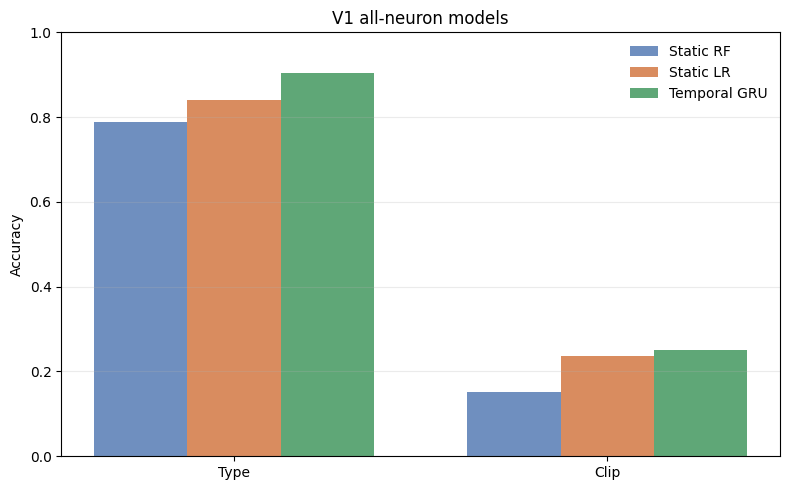

In [276]:
# Plot 1: V1 all-neuron static vs temporal comparison.
fig, ax = plt.subplots(figsize=(8, 5))

x = np.arange(len(v1_all_neuron_comparison))
width = 0.25

ax.bar(x - width, v1_all_neuron_comparison["Static RF"], width, label="Static RF", color="#6f8fbf")
ax.bar(x, v1_all_neuron_comparison["Static LR"], width, label="Static LR", color="#d98c5f")
ax.bar(x + width, v1_all_neuron_comparison["Temporal GRU"], width, label="Temporal GRU", color="#5fa777")

ax.set_xticks(x)
ax.set_xticklabels(["Type", "Clip"])
ax.set_ylim(0, 1.0)
ax.set_ylabel("Accuracy")
ax.set_title("V1 all-neuron models")
ax.legend(frameon=False)
ax.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()


The V1 plot visualizes the all-neuron result from the first table. The temporal GRU is clearly ahead of the best static classifier (logistic regression) for stimulus type (**+6.43 pp**: 0.9052 vs 0.8409) and slightly ahead for clip identity (**+1.36 pp**: 0.2500 vs 0.2364).

When the full 5312-neuron V1 population is available, the static representation already carries most of the decodable information about clip identity, so adding short-window temporal dynamics gives only a modest extra boost there. For broad stimulus type, however, temporal dynamics meaningfully help: the GRU exploits the time-evolution of the population response in a way that a single instantaneous vector cannot.


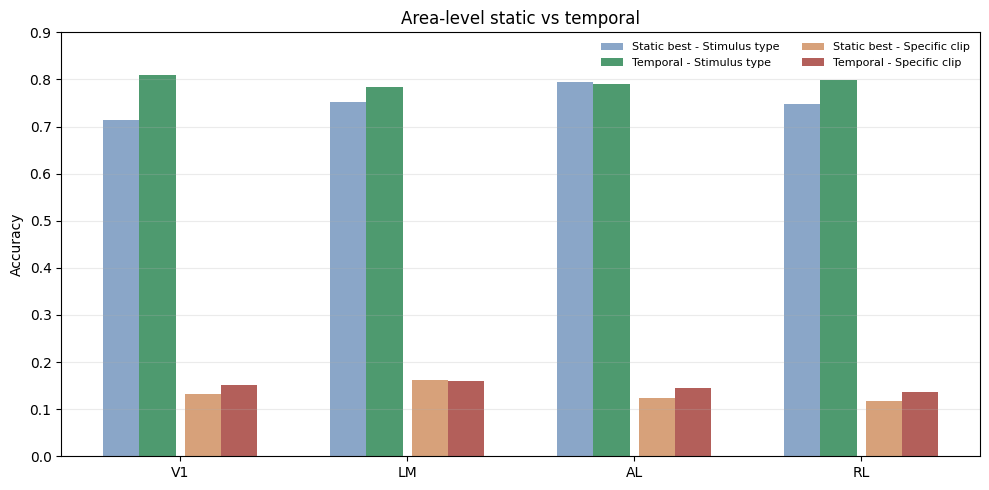

In [277]:
# Plot 2: area-level best static model vs temporal GRU.
fig, ax = plt.subplots(figsize=(10, 5))

plot_rows = temporal_gain_table.copy()
positions = np.arange(len(areas))

for offset, task, color_static, color_temporal in [
    (-0.18, "Stimulus type", "#8aa6c8", "#4e9a6f"),
    (0.18, "Specific clip", "#d7a17a", "#b35f5a"),
]:
    subset = plot_rows[plot_rows["Task"] == task]
    ax.bar(positions + offset - 0.08, subset["Best static accuracy"], 0.16,
           label=f"Static best - {task}", color=color_static)
    ax.bar(positions + offset + 0.08, subset["Temporal GRU accuracy"], 0.16,
           label=f"Temporal - {task}", color=color_temporal)

ax.set_xticks(positions)
ax.set_xticklabels(areas)
ax.set_ylim(0, 0.9)
ax.set_ylabel("Accuracy")
ax.set_title("Area-level static vs temporal")
ax.legend(frameon=False, fontsize=8, ncol=2)
ax.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()


When neuron count is controlled across areas, the picture becomes more nuanced than the simple "temporal always wins". For **stimulus type**, the temporal GRU clearly outperforms the best static classifier in V1, RL and LM (gains of +9.5, +5.0 and +3.1 pp), while AL shows essentially no temporal gain (–0.5 pp) because its static RF is already very strong. For **clip identity**, gains are smaller and more uniform (≈ +2 pp in V1, AL, RL; LM is flat).

Where temporal gains exist, they likely reflect information carried in the timing and evolution of population responses that a static snapshot cannot capture. Where they are absent — AL on stimulus type, LM on clip identity — the static representation already saturates what is recoverable from a 387-neuron sample.


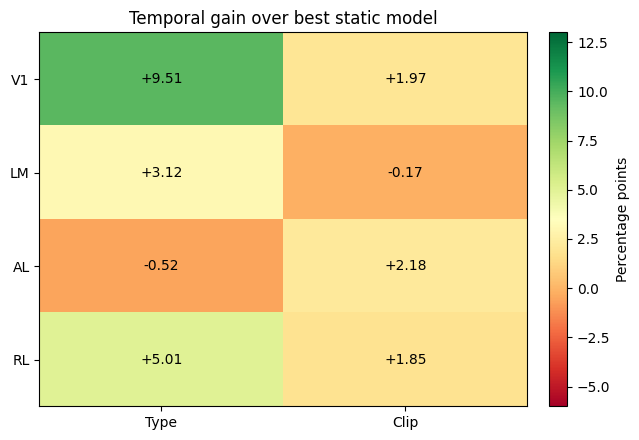

In [278]:
# Plot 3: temporal gain heatmap.
gain_matrix = temporal_gain_table.pivot(index="Area", columns="Task", values="Temporal gain (pp)").loc[areas]
gain_matrix = gain_matrix[["Stimulus type", "Specific clip"]]

fig, ax = plt.subplots(figsize=(6.5, 4.5))
im = ax.imshow(gain_matrix.values, cmap="RdYlGn", aspect="auto", vmin=-6, vmax=13)

ax.set_xticks(np.arange(gain_matrix.shape[1]))
ax.set_xticklabels(["Type", "Clip"])
ax.set_yticks(np.arange(len(areas)))
ax.set_yticklabels(areas)
ax.set_title("Temporal gain over best static model")

for i in range(gain_matrix.shape[0]):
    for j in range(gain_matrix.shape[1]):
        ax.text(j, i, f"{gain_matrix.values[i, j]:+.2f}", ha="center", va="center", fontsize=10)

cbar = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
cbar.set_label("Percentage points")

plt.tight_layout()
plt.show()


The heatmap makes the gain pattern easier to compare across areas. Positive cells show where temporal modeling adds accuracy, negative or near-zero cells show where it does not.

For **stimulus type**, V1 is the strongest beneficiary (+9.5 pp), with RL (+5.0 pp) and LM (+3.1 pp) following. **AL** is essentially flat (−0.5 pp): its static RF already reaches 0.80, leaving no room for temporal dynamics to add information at this neuron budget. For **clip identity**, gains are uniformly smaller (≤ +2.2 pp) because exact clip identification is dominated by per-trial variability that short windows cannot average out.

The overall picture is that temporal coding is most beneficial in **V1** and adds value progressively less as one moves through the areas in this dataset.


## Conclusion

### Static versus temporal coding

The static models show that a single population activity snapshot already contains strong stimulus information. This is especially clear in the full V1 analysis, where static logistic regression reaches **0.84** for stimulus type and **0.24** for exact clip identity (vs 0.33 and 0.01 chance respectively). This suggests that visual cortical population activity contains an instantaneous representation of stimulus identity, likely reflecting strong stimulus-driven tuning in the recorded neurons.

The temporal models add a second layer of information by using the evolution of activity across a short 10-timepoint window. In V1 with all neurons available, the GRU lifts type accuracy to **0.91** (+6.4 pp over static LR) and clip accuracy to **0.25** (+1.4 pp). When neuron count is controlled across areas to 387, the temporal gain is largest in V1 (+9.5 pp on type), positive in RL and LM, and **near-zero in AL**, because AL's static RF is already very strong at this neuron budget. For clip identity, gains are uniformly small (≤ +2.2 pp). Temporal dynamics therefore carry additional information beyond average activity, but how much additional information depends on the area and on the task.

### Differences across visual areas

Stimulus information is distributed across the visual hierarchy rather than isolated in **V1**. All four areas support above-chance decoding for both tasks, but they do not contribute identically. With matched 387-neuron populations:
- **V1** is the strongest beneficiary of temporal modeling for stimulus type;
- **AL** has the strongest static representation of stimulus type (RF 0.80) but gains nothing from temporal dynamics;
- **LM** consistently leads for specific-clip identification across both static and temporal settings, suggesting that intermediate-level features in LM are particularly diagnostic of individual clips;
- **RL** sits in the middle for both tasks.

This pattern is consistent with the idea that early visual cortex captures strong low-level sensory structure with strong instantaneous tuning, whereas higher visual areas may contribute differently depending on the task.

### Repetition and reliability

The specific-clip task shows a strong reliability effect. Clips shown ten times are decoded much more accurately than clips shown only twice — by 5× to 30× depending on area and model. Neuroscientifically, this suggests that clip-specific neural responses are more detectable when more repeated examples are available. The lower x2 performance does not necessarily mean that the cortex lacks clip information; it may also reflect limited training data and higher trial-to-trial variability in single-trial responses.

### Overall interpretation

Overall, the project supports two complementary conclusions. **First**, static population activity contains strong visual information and is sufficient for many decoding goals. **Second**, temporal dynamics provide additional information, but the size of the temporal gain varies by area and task: it is largest for broad stimulus type in V1, smaller in higher areas, and uniformly small for exact clip identification. Together, these results suggest that visual cortex represents stimuli through a combination of instantaneous population patterns and short-timescale temporal dynamics, with the relative weight of the two encoding modes depending on the area and on what is being decoded.
